# Deep Learning for Multi-Asset Forecasting and Portfolio Construction


In [ ]:
#
#







## Libraries And Settings


In [ ]:
import warnings
warnings.filterwarnings("ignore")

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf

from IPython.display import display

from statsmodels.tsa.stattools import adfuller

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping


# Reproducibility

SEED = 42

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)


# Display and plotting settings

sns.set_theme(style="whitegrid")

pd.set_option(
    "display.max_columns",
    None
)

pd.set_option(
    "display.float_format",
    lambda x: f"{x:.6f}"
)


print("Libraries imported successfully.")
print("TensorFlow version:", tf.__version__)


## Asset Universe


In [ ]:
etfs = {
    "SPY": "Equity",
    "TLT": "Fixed Income",
    "SHY": "Cash-like",
    "GLD": "Precious Metals (Gold)",
    "DBO": "Crude Oil"
}

symbols = list(etfs.keys())


print("\nSelected ETFs")
print("=" * 60)

for symbol, asset_class in etfs.items():
    print(
        f"{symbol}: {asset_class}"
    )


## Dataset Description


In [ ]:
dataset_description = pd.DataFrame({
    "ETF": symbols,

    "Asset Class": [
        etfs[symbol]
        for symbol in symbols
    ],

    "Description": [
        "SPDR S&P 500 ETF Trust",
        "iShares 20+ Year Treasury Bond ETF",
        "iShares 1-3 Year Treasury Bond ETF",
        "SPDR Gold Shares",
        "Invesco DB Oil Fund"
    ]
})


print("\nDataset Description")
print("=" * 60)

display(
    dataset_description
)


## Download Daily Prices


In [ ]:
#
# January 1, 2018 to December 30, 2022
#
# yfinance treats the end date as exclusive, so December 31,
# 2022 is used as the download end date to include December 30.


START_DATE = "2018-01-01"
END_DATE = "2022-12-31"


print("\nDownloading daily ETF data...")
print(
    f"Requested period: {START_DATE} to 2022-12-30"
)


raw_data = yf.download(
    symbols,
    start=START_DATE,
    end=END_DATE,
    auto_adjust=False,
    progress=False
)


# Extract adjusted closing prices

if isinstance(
    raw_data.columns,
    pd.MultiIndex
):

    if "Adj Close" in raw_data.columns.get_level_values(0):

        data = raw_data["Adj Close"].copy()

    else:

        data = raw_data["Close"].copy()

else:

    if "Adj Close" in raw_data.columns:

        data = raw_data[["Adj Close"]].copy()

        data.columns = symbols[:1]

    else:

        data = raw_data[["Close"]].copy()

        data.columns = symbols[:1]


# Make sure columns are in the required order
data = data[symbols]


# Remove rows where every asset is missing
data = data.dropna(
    how="all"
)


# Handle isolated missing observations

data = data.ffill()


print("\nDataset information")
print("=" * 60)

print(
    "First observation:",
    data.index.min().date()
)

print(
    "Last observation:",
    data.index.max().date()
)

print(
    "Number of price observations:",
    len(data)
)

print(
    "Number of ETFs:",
    data.shape[1]
)


print("\nFirst five observations")
display(
    data.head()
)


print("\nLast five observations")
display(
    data.tail()
)


## Verify Required Study Period


In [ ]:
print("\nDataset Verification")
print("=" * 60)


required_start = pd.Timestamp(
    "2018-01-01"
)

required_end = pd.Timestamp(
    "2022-12-30"
)


if data.index.min() <= required_start:

    print(
        "✓ Data cover the required starting date."
    )

else:

    print(
        "WARNING: Data do not begin early enough."
    )


if required_end in data.index:

    print(
        "✓ December 30, 2022 is included."
    )

else:

    print(
        "WARNING: December 30, 2022 is not present."
    )


## Check Missing Values


In [ ]:
missing_values = data.isna().sum()


missing_table = pd.DataFrame({

    "Missing Values":
        missing_values,

    "Missing Percentage (%)":
        (
            missing_values
            / len(data)
            * 100
        )

})


print("\nMissing Values")
print("=" * 60)

display(
    missing_table
)


## Calculate Daily Returns


In [ ]:
# Daily simple return:
#
#              P_t - P_(t-1)
# r_t = -------------------------
#                 P_(t-1)
#
# Equivalent:
#
# r_t = P_t / P_(t-1) - 1


returns = (
    data
    .pct_change()
    .dropna()
)


print("\nDaily Return Dataset")
print("=" * 60)

print(
    "Number of return observations:",
    len(returns)
)

print(
    "First return date:",
    returns.index.min().date()
)

print(
    "Last return date:",
    returns.index.max().date()
)


display(
    returns.head()
)


## Mathematical Definition Of Daily Returns


In [ ]:
print("\nMathematical definition used in the analysis:")
print()
print("r_t = (P_t - P_(t-1)) / P_(t-1)")
print()
print(
    "where P_t is the adjusted closing price at time t "
    "and P_(t-1) is the adjusted closing price on the "
    "previous trading day."
)


## Summary Statistics


In [ ]:
summary_stats = returns.describe().T


summary_stats["Skewness"] = (
    returns.skew()
)


summary_stats["Kurtosis"] = (
    returns.kurtosis()
)


summary_stats = summary_stats[
    [
        "count",
        "mean",
        "std",
        "min",
        "25%",
        "50%",
        "75%",
        "max",
        "Skewness",
        "Kurtosis"
    ]
]


print("\nTable 1: Summary Statistics of Daily Returns")
print("=" * 60)

display(
    summary_stats
)


## Annualized Return And Volatility


In [ ]:
TRADING_DAYS = 252


# Annualized mean return:
#
# R_annual = 252 × mean daily return
#
#
# Annualized volatility:
#
# sigma_annual = sigma_daily × sqrt(252)


annualized_return = (
    returns.mean()
    * TRADING_DAYS
)


annualized_volatility = (
    returns.std()
    * np.sqrt(TRADING_DAYS)
)


risk_return_table = pd.DataFrame({

    "Annualized Mean Return":
        annualized_return,

    "Annualized Volatility":
        annualized_volatility

})


print("\nTable 2: Annualized Risk-Return Characteristics")
print("=" * 60)

display(
    risk_return_table
)


## Individual Return Distributions


In [ ]:
fig, axes = plt.subplots(
    nrows=5,
    ncols=1,
    figsize=(12, 18)
)


for ax, symbol in zip(
    axes,
    symbols
):

    sns.histplot(
        returns[symbol],
        bins=60,
        kde=True,
        ax=ax
    )

    ax.set_title(
        f"{symbol} ({etfs[symbol]}) Daily Return Distribution"
    )

    ax.set_xlabel(
        "Daily Return"
    )

    ax.set_ylabel(
        "Frequency"
    )


plt.tight_layout()
plt.show()


## Distribution Numerical Interpretation


In [ ]:
print("\nDistribution Characteristics")
print("=" * 60)


for symbol in symbols:

    mean_value = (
        returns[symbol].mean()
    )

    std_value = (
        returns[symbol].std()
    )

    min_value = (
        returns[symbol].min()
    )

    max_value = (
        returns[symbol].max()
    )

    skew_value = (
        returns[symbol].skew()
    )

    kurt_value = (
        returns[symbol].kurtosis()
    )


    print(
        f"\n{symbol} - {etfs[symbol]}"
    )

    print(
        f"Mean daily return: "
        f"{mean_value:.6f}"
    )

    print(
        f"Daily standard deviation: "
        f"{std_value:.6f}"
    )

    print(
        f"Minimum daily return: "
        f"{min_value:.6f}"
    )

    print(
        f"Maximum daily return: "
        f"{max_value:.6f}"
    )

    print(
        f"Skewness: "
        f"{skew_value:.4f}"
    )

    print(
        f"Kurtosis: "
        f"{kurt_value:.4f}"
    )


## ADF Stationarity Test


In [ ]:
# Augmented Dickey-Fuller test:
#
# H0: The series has a unit root and is non-stationary.
#
# H1: The series is stationary.
#
# At the 5% significance level:
#
# p-value < 0.05
# -> reject H0
# -> evidence of stationarity.


def run_adf_test(series):

    result = adfuller(
        series.dropna(),
        autolag="AIC"
    )


    return {

        "ADF Statistic":
            result[0],

        "p-value":
            result[1],

        "1% Critical Value":
            result[4]["1%"],

        "5% Critical Value":
            result[4]["5%"],

        "10% Critical Value":
            result[4]["10%"],

        "Stationary at 5%":
            result[1] < 0.05

    }


adf_results = {}


for symbol in symbols:

    adf_results[symbol] = (
        run_adf_test(
            returns[symbol]
        )
    )


adf_table = (
    pd.DataFrame(
        adf_results
    )
    .T
)


print("\nTable 3: Augmented Dickey-Fuller Test Results")
print("=" * 60)

display(
    adf_table
)


## ADF Interpretation


In [ ]:
print("\nADF Interpretation")
print("=" * 60)


for symbol in symbols:

    p_value = (
        adf_table
        .loc[symbol, "p-value"]
    )


    if p_value < 0.05:

        print(
            f"{symbol}: p-value = "
            f"{p_value:.6f}. "
            f"The unit-root null hypothesis is rejected "
            f"at the 5% significance level, providing "
            f"evidence that the daily return series is stationary."
        )

    else:

        print(
            f"{symbol}: p-value = "
            f"{p_value:.6f}. "
            f"The unit-root null hypothesis cannot be rejected "
            f"at the 5% significance level."
        )


## Correlation Matrix


In [ ]:
# Correlation:
#
# rho_xy =
# Cov(X,Y) / (sigma_x sigma_y)


correlation_matrix = (
    returns.corr()
)


print("\nTable 4: Correlation Matrix of Daily Returns")
print("=" * 60)

display(
    correlation_matrix
)


## Covariance Matrix


In [ ]:
covariance_matrix = (
    returns.cov()
)


print("\nTable 5: Covariance Matrix of Daily Returns")
print("=" * 60)

display(
    covariance_matrix
)


## Correlation Heatmap


In [ ]:
plt.figure(
    figsize=(10, 8)
)


sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".3f",
    cmap="coolwarm",
    center=0,
    square=True
)


plt.title(
    "Correlation Matrix of Daily ETF Returns"
)

plt.xlabel(
    "ETF"
)

plt.ylabel(
    "ETF"
)


plt.tight_layout()
plt.show()


## Identify Important Correlation Relationships


In [ ]:
corr_pairs = (
    correlation_matrix
    .where(
        np.triu(
            np.ones(
                correlation_matrix.shape
            ),
            k=1
        ).astype(bool)
    )
    .stack()
)


strongest_positive_pair = (
    corr_pairs.idxmax()
)

strongest_positive_value = (
    corr_pairs.max()
)


strongest_negative_pair = (
    corr_pairs.idxmin()
)

strongest_negative_value = (
    corr_pairs.min()
)


weakest_pair = (
    corr_pairs.abs()
    .idxmin()
)

weakest_value = (
    corr_pairs.loc[weakest_pair]
)


print("\nCorrelation Findings")
print("=" * 60)


print(
    f"Strongest positive relationship: "
    f"{strongest_positive_pair[0]} and "
    f"{strongest_positive_pair[1]} "
    f"= {strongest_positive_value:.3f}"
)


print(
    f"Strongest negative relationship: "
    f"{strongest_negative_pair[0]} and "
    f"{strongest_negative_pair[1]} "
    f"= {strongest_negative_value:.3f}"
)


print(
    f"Weakest absolute relationship: "
    f"{weakest_pair[0]} and "
    f"{weakest_pair[1]} "
    f"= {weakest_value:.3f}"
)


## Historical Price Trends


In [ ]:
plt.figure(
    figsize=(14, 8)
)


for symbol in symbols:

    plt.plot(
        data.index,
        data[symbol],
        label=(
            f"{symbol} - "
            f"{etfs[symbol]}"
        )
    )


plt.title(
    "Historical Adjusted Closing Prices, 2018-2022"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Adjusted Closing Price"
)

plt.legend()

plt.tight_layout()

plt.show()


## Normalized Price Trends


In [ ]:
# All assets are normalized to 100 at the beginning
# so their relative performance can be compared.


normalized_prices = (
    data
    / data.iloc[0]
    * 100
)


plt.figure(
    figsize=(14, 8)
)


for symbol in symbols:

    plt.plot(
        normalized_prices.index,
        normalized_prices[symbol],
        label=symbol
    )


plt.title(
    "Normalized ETF Price Performance"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Value of 100 Initial Investment"
)

plt.legend()

plt.tight_layout()

plt.show()


## 60-Day Rolling Annualized Volatility


In [ ]:
rolling_volatility = (
    returns
    .rolling(
        window=60
    )
    .std()
    * np.sqrt(TRADING_DAYS)
)


plt.figure(
    figsize=(14, 8)
)


for symbol in symbols:

    plt.plot(
        rolling_volatility.index,
        rolling_volatility[symbol],
        label=symbol
    )


plt.title(
    "60-Day Rolling Annualized Volatility"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Annualized Volatility"
)

plt.legend()

plt.tight_layout()

plt.show()


## Volatility Summary


In [ ]:
volatility_comparison = pd.DataFrame({

    "Average Annualized Volatility":
        rolling_volatility.mean(),

    "Maximum Annualized Volatility":
        rolling_volatility.max(),

    "Minimum Annualized Volatility":
        rolling_volatility.min()

})


print("\nTable 6: Rolling Volatility Summary")
print("=" * 60)

display(
    volatility_comparison
)


## Exploratory Analysis Findings


In [ ]:
highest_vol_asset = (
    annualized_volatility.idxmax()
)

lowest_vol_asset = (
    annualized_volatility.idxmin()
)

highest_return_asset = (
    annualized_return.idxmax()
)

lowest_return_asset = (
    annualized_return.idxmin()
)


print("\n============================================================")
print("KEY NUMERICAL FINDINGS")
print("============================================================")


print(
    f"Highest annualized mean return: "
    f"{highest_return_asset} "
    f"({annualized_return[highest_return_asset]:.2%})"
)


print(
    f"Lowest annualized mean return: "
    f"{lowest_return_asset} "
    f"({annualized_return[lowest_return_asset]:.2%})"
)


print(
    f"Highest annualized volatility: "
    f"{highest_vol_asset} "
    f"({annualized_volatility[highest_vol_asset]:.2%})"
)


print(
    f"Lowest annualized volatility: "
    f"{lowest_vol_asset} "
    f"({annualized_volatility[lowest_vol_asset]:.2%})"
)


print(
    f"Strongest positive correlation: "
    f"{strongest_positive_pair[0]} and "
    f"{strongest_positive_pair[1]} "
    f"({strongest_positive_value:.3f})"
)


print(
    f"Strongest negative correlation: "
    f"{strongest_negative_pair[0]} and "
    f"{strongest_negative_pair[1]} "
    f"({strongest_negative_value:.3f})"
)


## Prediction Objective


In [ ]:
#  asks each asset class to be used to predict
# its 25-day-ahead return.
#
# We define:
#
# R_(t,t+25) =
# P_(t+25) / P_t - 1
#
# This represents the cumulative return from time t
# to 25 trading days later.


LOOKBACK = 25

FORECAST_HORIZON = 25


print("\n============================================================")
print("25-DAY-AHEAD RETURN PREDICTION")
print("============================================================")


print(
    "Input window: Previous 25 daily returns"
)

print(
    "Prediction target: Cumulative return over the "
    "following 25 trading days"
)


print(
    "\nTarget formula:"
)

print(
    "R_(t,t+25) = P_(t+25) / P_t - 1"
)


## Create Supervised Data


In [ ]:
def create_sequences(
    return_series,
    lookback=25,
    horizon=25
):

    X = []
    y = []

    values = (
        return_series
        .values
    )


    for i in range(
        len(values)
        - lookback
        - horizon
        + 1
    ):

        # Past information available at time t
        past_returns = (
            values[
                i:
                i + lookback
            ]
        )


        # Future 25 daily returns
        future_returns = (
            values[
                i + lookback:
                i + lookback + horizon
            ]
        )


        # Compound future returns
        future_25_day_return = (
            np.prod(
                1 + future_returns
            )
            - 1
        )


        X.append(
            past_returns
        )

        y.append(
            future_25_day_return
        )


    return (
        np.array(X),
        np.array(y)
    )


## Create Data For Each ETF


In [ ]:
sequence_data = {}


for symbol in symbols:

    X, y = create_sequences(
        returns[symbol],
        lookback=LOOKBACK,
        horizon=FORECAST_HORIZON
    )


    sequence_data[symbol] = {
        "X": X,
        "y": y
    }


    print(
        f"\n{symbol}:"
    )

    print(
        f"Input shape: {X.shape}"
    )

    print(
        f"Target shape: {y.shape}"
    )


## Verify 25-Day Target


In [ ]:
print("\n25-Day Target Verification")
print("=" * 60)


example_symbol = "SPY"


example_X = (
    sequence_data[
        example_symbol
    ]["X"]
)


example_y = (
    sequence_data[
        example_symbol
    ]["y"]
)


print(
    "Example asset:",
    example_symbol
)


print(
    "Number of historical daily returns "
    "used as input:",
    len(example_X[0])
)


print(
    "Example 25-day-ahead target:",
    example_y[0]
)


## Chronological Train/Test Split


In [ ]:
# The test period represents the later part of the sample.
#
# No random shuffling is used because random shuffling can
# mix information from different points in time.


TEST_SIZE = 0.20


def chronological_split(
    X,
    y,
    test_size=0.20
):

    split_index = int(
        len(X)
        * (1 - test_size)
    )


    X_train = (
        X[:split_index]
    )

    X_test = (
        X[split_index:]
    )


    y_train = (
        y[:split_index]
    )

    y_test = (
        y[split_index:]
    )


    return (
        X_train,
        X_test,
        y_train,
        y_test
    )


## Standardize Inputs


In [ ]:
model_data = {}


for symbol in symbols:

    X = (
        sequence_data[
            symbol
        ]["X"]
    )

    y = (
        sequence_data[
            symbol
        ]["y"]
    )


    (
        X_train,
        X_test,
        y_train,
        y_test
    ) = chronological_split(
        X,
        y,
        test_size=TEST_SIZE
    )


    # Fit scaler ONLY on training data
    scaler = StandardScaler()


    X_train_scaled = (
        scaler
        .fit_transform(
            X_train
        )
    )


    X_test_scaled = (
        scaler
        .transform(
            X_test
        )
    )


    model_data[symbol] = {

        "X_train":
            X_train,

        "X_test":
            X_test,

        "y_train":
            y_train,

        "y_test":
            y_test,

        "X_train_scaled":
            X_train_scaled,

        "X_test_scaled":
            X_test_scaled,

        "scaler":
            scaler

    }


    print(
        f"{symbol}: "
        f"Training observations = "
        f"{len(X_train)}, "
        f"Testing observations = "
        f"{len(X_test)}"
    )


## Build Prediction Model


In [ ]:
def build_prediction_model(
    input_length
):

    model = Sequential([

        Input(
            shape=(input_length,)
        ),

        Dense(
            64,
            activation="relu"
        ),

        Dense(
            32,
            activation="relu"
        ),

        Dense(
            1
        )

    ])


    model.compile(
        optimizer="adam",
        loss="mse"
    )


    return model


## Performance Metrics


In [ ]:
# Mean Squared Error:
#
# MSE = (1/n) Σ(y_i - ŷ_i)^2
#
#
# Root Mean Squared Error:
#
# RMSE = sqrt(MSE)
#
#
# Mean Absolute Error:
#
# MAE = (1/n) Σ|y_i - ŷ_i|
#
#
# R-squared:
#
# R² = 1 - SSE/SST


def calculate_metrics(
    y_true,
    predictions
):

    mse = mean_squared_error(
        y_true,
        predictions
    )


    rmse = np.sqrt(
        mse
    )


    mae = mean_absolute_error(
        y_true,
        predictions
    )


    r2 = r2_score(
        y_true,
        predictions
    )


    return {

        "MSE":
            mse,

        "RMSE":
            rmse,

        "MAE":
            mae,

        "R2":
            r2

    }


## Train And Test The Models


In [ ]:
results = []

predictions = {}

actual_values = {}

training_histories = {}


for symbol in symbols:

    print("\n")
    print("=" * 60)

    print(
        f"Training model for "
        f"{symbol} - {etfs[symbol]}"
    )

    print("=" * 60)


    X_train = (
        model_data[
            symbol
        ]["X_train_scaled"]
    )


    X_test = (
        model_data[
            symbol
        ]["X_test_scaled"]
    )


    y_train = (
        model_data[
            symbol
        ]["y_train"]
    )


    y_test = (
        model_data[
            symbol
        ]["y_test"]
    )


    # Build

    model = build_prediction_model(
        LOOKBACK
    )


    # Early stopping

    early_stopping = EarlyStopping(

        monitor="val_loss",

        patience=7,

        restore_best_weights=True

    )


    # Train

    history = model.fit(

        X_train,

        y_train,

        validation_split=0.20,

        epochs=75,

        batch_size=32,

        callbacks=[
            early_stopping
        ],

        verbose=0,

        shuffle=False

    )


    # Predictions

    train_predictions = (
        model
        .predict(
            X_train,
            verbose=0
        )
        .flatten()
    )


    test_predictions = (
        model
        .predict(
            X_test,
            verbose=0
        )
        .flatten()
    )


    # Metrics

    train_metrics = (
        calculate_metrics(
            y_train,
            train_predictions
        )
    )


    test_metrics = (
        calculate_metrics(
            y_test,
            test_predictions
        )
    )


    # Store results

    results.append({

        "ETF":
            symbol,

        "Asset Class":
            etfs[symbol],

        "Training MSE":
            train_metrics["MSE"],

        "Training RMSE":
            train_metrics["RMSE"],

        "Training MAE":
            train_metrics["MAE"],

        "Training R2":
            train_metrics["R2"],

        "Test MSE":
            test_metrics["MSE"],

        "Test RMSE":
            test_metrics["RMSE"],

        "Test MAE":
            test_metrics["MAE"],

        "Test R2":
            test_metrics["R2"]

    })


    predictions[symbol] = (
        test_predictions
    )


    actual_values[symbol] = (
        y_test
    )


    training_histories[symbol] = (
        history
    )


## Performance Table


In [ ]:
performance_table = (
    pd.DataFrame(
        results
    )
    .set_index("ETF")
)


print("\n")
print("=" * 70)

print(
    "TABLE 7: IN-SAMPLE AND OUT-OF-SAMPLE PREDICTIVE PERFORMANCE"
)

print("=" * 70)


display(
    performance_table
)


## Model Performance Summary


In [ ]:
report_performance_table = (
    performance_table
    .round(6)
)


print(
    "\nReport-ready performance table:"
)

display(
    report_performance_table
)


## Out-Of-Sample Rmse


In [ ]:
plt.figure(
    figsize=(10, 6)
)


plt.bar(
    performance_table.index,
    performance_table[
        "Test RMSE"
    ]
)


plt.title(
    "Out-of-Sample RMSE Across Asset Classes"
)

plt.xlabel(
    "ETF"
)

plt.ylabel(
    "Test RMSE"
)


plt.tight_layout()

plt.show()


## Out-Of-Sample R²


In [ ]:
plt.figure(
    figsize=(10, 6)
)


plt.bar(
    performance_table.index,
    performance_table[
        "Test R2"
    ]
)


plt.axhline(
    0,
    linestyle="--"
)


plt.title(
    "Out-of-Sample R² Across Asset Classes"
)

plt.xlabel(
    "ETF"
)

plt.ylabel(
    "Test R²"
)


plt.tight_layout()

plt.show()


## Actual Vs Predicted Returns


In [ ]:
fig, axes = plt.subplots(
    nrows=5,
    ncols=1,
    figsize=(14, 18)
)


for ax, symbol in zip(
    axes,
    symbols
):

    actual = (
        actual_values[
            symbol
        ]
    )


    predicted = (
        predictions[
            symbol
        ]
    )


    ax.plot(
        actual,
        label="Actual 25-Day Return",
        linewidth=1.5
    )


    ax.plot(
        predicted,
        label="Predicted 25-Day Return",
        linewidth=1.2
    )


    ax.set_title(
        f"{symbol} - Actual vs Predicted "
        f"25-Day-Ahead Return"
    )


    ax.set_xlabel(
        "Test Observation"
    )


    ax.set_ylabel(
        "25-Day Return"
    )


    ax.legend()


plt.tight_layout()

plt.show()


## Predicted Vs Actual Scatterplots


In [ ]:
fig, axes = plt.subplots(
    2,
    3,
    figsize=(16, 10)
)


axes = axes.flatten()


for i, symbol in enumerate(
    symbols
):

    actual = (
        actual_values[
            symbol
        ]
    )


    predicted = (
        predictions[
            symbol
        ]
    )


    axes[i].scatter(
        actual,
        predicted,
        alpha=0.5
    )


    minimum = min(
        actual.min(),
        predicted.min()
    )


    maximum = max(
        actual.max(),
        predicted.max()
    )


    axes[i].plot(
        [minimum, maximum],
        [minimum, maximum],
        linestyle="--"
    )


    axes[i].set_title(
        f"{symbol} - Predicted vs Actual"
    )


    axes[i].set_xlabel(
        "Actual 25-Day Return"
    )


    axes[i].set_ylabel(
        "Predicted 25-Day Return"
    )


# Remove unused sixth plot
fig.delaxes(
    axes[-1]
)


plt.tight_layout()

plt.show()


## In-Sample Vs Out-Of-Sample Comparison


In [ ]:
comparison_table = performance_table[
    [
        "Training R2",
        "Test R2",
        "Training RMSE",
        "Test RMSE"
    ]
].copy()


comparison_table[
    "R2 Difference"
] = (
    comparison_table[
        "Training R2"
    ]
    -
    comparison_table[
        "Test R2"
    ]
)


comparison_table[
    "RMSE Increase"
] = (
    comparison_table[
        "Test RMSE"
    ]
    -
    comparison_table[
        "Training RMSE"
    ]
)


print("\nTable 8: In-Sample vs Out-of-Sample Comparison")

display(
    comparison_table
    .round(6)
)


## Best And Weakest Out-Of-Sample Results


In [ ]:
best_rmse_asset = (
    performance_table[
        "Test RMSE"
    ].idxmin()
)


worst_rmse_asset = (
    performance_table[
        "Test RMSE"
    ].idxmax()
)


best_r2_asset = (
    performance_table[
        "Test R2"
    ].idxmax()
)


worst_r2_asset = (
    performance_table[
        "Test R2"
    ].idxmin()
)


print("\n")
print("=" * 70)

print(
    "KEY NUMERICAL FINDINGS"
)

print("=" * 70)


print(
    f"Lowest out-of-sample RMSE: "
    f"{best_rmse_asset} = "
    f"{performance_table.loc[best_rmse_asset, 'Test RMSE']:.6f}"
)


print(
    f"Highest out-of-sample RMSE: "
    f"{worst_rmse_asset} = "
    f"{performance_table.loc[worst_rmse_asset, 'Test RMSE']:.6f}"
)


print(
    f"Highest out-of-sample R²: "
    f"{best_r2_asset} = "
    f"{performance_table.loc[best_r2_asset, 'Test R2']:.6f}"
)


print(
    f"Lowest out-of-sample R²: "
    f"{worst_r2_asset} = "
    f"{performance_table.loc[worst_r2_asset, 'Test R2']:.6f}"
)


## Detailed Numerical Interpretation


In [ ]:
print("\n")
print("=" * 70)

print(
    "DETAILED INTERPRETATION"
)

print("=" * 70)


for symbol in symbols:

    row = (
        performance_table
        .loc[symbol]
    )


    train_r2 = (
        row["Training R2"]
    )


    test_r2 = (
        row["Test R2"]
    )


    train_rmse = (
        row["Training RMSE"]
    )


    test_rmse = (
        row["Test RMSE"]
    )


    print(
        f"\n{symbol} - {etfs[symbol]}"
    )

    print(
        "-" * 60
    )


    print(
        f"Training R²: "
        f"{train_r2:.6f}"
    )


    print(
        f"Out-of-sample R²: "
        f"{test_r2:.6f}"
    )


    print(
        f"Training RMSE: "
        f"{train_rmse:.6f}"
    )


    print(
        f"Out-of-sample RMSE: "
        f"{test_rmse:.6f}"
    )


    if test_r2 > 0:

        print(
            "Interpretation: The positive out-of-sample R² "
            "indicates that the predictions explain some variation "
            "in the 25-day-ahead return relative to a mean-based "
            "benchmark."
        )

    elif test_r2 == 0:

        print(
            "Interpretation: An R² close to zero indicates that "
            "the predictions provide little improvement over a "
            "mean-based benchmark."
        )

    else:

        print(
            "Interpretation: The negative out-of-sample R² "
            "indicates that the prediction errors are larger than "
            "those of the mean-based benchmark."
        )


    if test_rmse > train_rmse:

        print(
            "The increase in RMSE from training to testing "
            "indicates weaker predictive performance on unseen "
            "observations."
        )

    else:

        print(
            "The test RMSE is not higher than the training RMSE. "
            "This result should nevertheless be interpreted using "
            "the full test-period evidence."
        )


## Investment-Oriented Interpretation


In [ ]:
print("\n")
print("=" * 70)

print(
    "INVESTMENT-ORIENTED SUMMARY"
)

print("=" * 70)


print(
    f"The lowest out-of-sample prediction error was observed "
    f"for {best_rmse_asset}, while {worst_rmse_asset} had "
    f"the highest prediction error."
)


print(
    f"{best_r2_asset} recorded the highest out-of-sample R², "
    f"whereas {worst_r2_asset} recorded the lowest."
)


print(
    "\nThe differences across asset classes indicate that "
    "historical return information does not provide the same "
    "degree of short-term predictive information for every "
    "market. Consequently, investment decisions should not "
    "be based on prediction accuracy alone. Risk, volatility, "
    "correlation with other assets, liquidity, and the economic "
    "conditions affecting each asset should also be considered."
)


## Training History


In [ ]:
fig, axes = plt.subplots(
    5,
    1,
    figsize=(12, 18)
)


for ax, symbol in zip(
    axes,
    symbols
):

    history = (
        training_histories[
            symbol
        ]
    )


    ax.plot(
        history.history["loss"],
        label="Training Loss"
    )


    ax.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )


    ax.set_title(
        f"{symbol} - Training and Validation Loss"
    )


    ax.set_xlabel(
        "Epoch"
    )


    ax.set_ylabel(
        "Mean Squared Error"
    )


    ax.legend()


plt.tight_layout()

plt.show()


## Save All Important Results


Libraries imported successfully.
TensorFlow version: 2.20.0

Selected ETFs
SPY: Equity
TLT: Fixed Income
SHY: Cash-like
GLD: Precious Metals (Gold)
DBO: Crude Oil

Dataset Description


,ETF,Asset Class,Description
0,SPY,Equity,SPDR S&P 500 ETF Trust
1,TLT,Fixed Income,iShares 20+ Year Treasury Bond ETF
2,SHY,Cash-like,iShares 1-3 Year Treasury Bond ETF
3,GLD,Precious Metals (Gold),SPDR Gold Shares
4,DBO,Crude Oil,Invesco DB Oil Fund



Requested period: 2018-01-01 to 2022-12-30

Dataset information
First observation: 2018-01-02
Last observation: 2022-12-30
Number of price observations: 1259
Number of ETFs: 5

First five observations


Ticker,SPY,TLT,SHY,GLD,DBO
Date,,,,,
2018-01-02,235.954300,97.574036,69.016350,125.150002,8.636581
2018-01-03,237.446732,98.040527,69.016350,124.820000,8.823044
2018-01-04,238.447495,98.024986,68.983437,125.459999,8.839995
2018-01-05,240.036606,97.745087,68.983437,125.330002,8.797618
2018-01-08,240.475586,97.682838,68.983437,125.309998,8.848471



Last five observations


...

Ticker,SPY,TLT,SHY,GLD,DBO
Date,,,,,
2018-01-03,0.006325,0.004781,0.000000,-0.002637,0.021590
2018-01-04,0.004215,-0.000159,-0.000477,0.005127,0.001921
2018-01-05,0.006664,-0.002855,0.000000,-0.001036,-0.004794
2018-01-08,0.001829,-0.000637,0.000000,-0.000160,0.005780
2018-01-09,0.002263,-0.013373,-0.000358,-0.004628,0.017241



Mathematical definition used in the analysis:

r_t = (P_t - P_(t-1)) / P_(t-1)

where P_t is the adjusted closing price at time t and P_(t-1) is the adjusted closing price on the previous trading day.

Table 1: Summary Statistics of Daily Returns


,count,mean,std,min,25%,50%,75%,max,Skewness,Kurtosis
Ticker,,,,,,,,,,
SPY,1258.000000,0.000441,0.013575,-0.109424,-0.005130,0.000768,0.007112,0.090604,-0.526702,10.485367
TLT,1258.000000,-0.000050,0.010171,-0.066682,-0.005797,0.000072,0.005653,0.075195,0.253291,6.883077
SHY,1258.000000,0.000025,0.000883,-0.005088,-0.000348,0.000000,0.000354,0.005453,0.097273,7.495036
GLD,1258.000000,0.000283,0.009044,-0.053694,-0.004325,0.000520,0.005091,0.048530,-0.271012,3.550753
DBO,1258.000000,0.000587,0.021621,-0.166453,-0.009601,0.002443,0.012775,0.106227,-0.877981,5.896078



Table 2: Annualized Risk-Return Characteristics


,Annualized Mean Return,Annualized Volatility
Ticker,,
SPY,0.111105,0.215497
TLT,-0.012646,0.161453
SHY,0.006361,0.014010
GLD,0.071251,0.143565
DBO,0.147803,0.343228


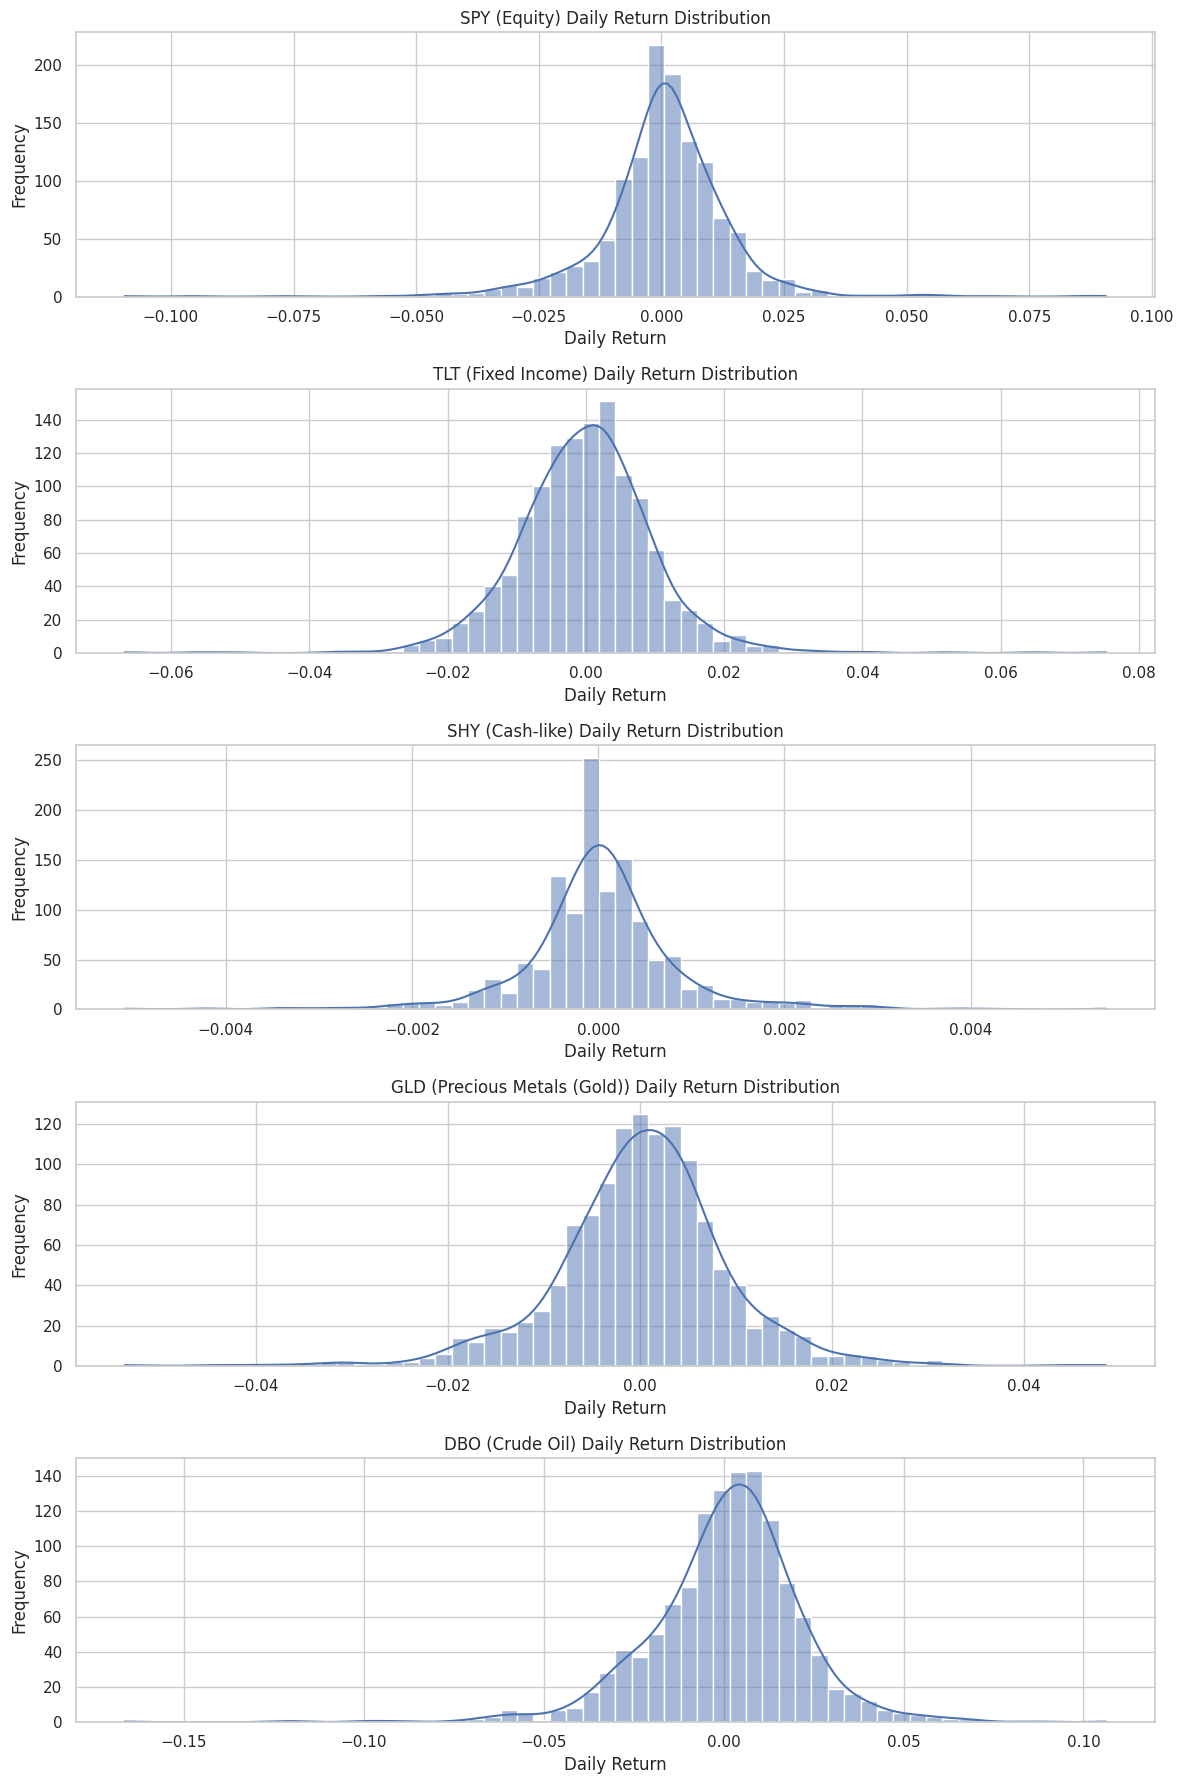


Distribution Characteristics

SPY - Equity
Mean daily return: 0.000441
Daily standard deviation: 0.013575
Minimum daily return: -0.109424
Maximum daily return: 0.090604
Skewness: -0.5267
Kurtosis: 10.4854

TLT - Fixed Income
Mean daily return: -0.000050
Daily standard deviation: 0.010171
Minimum daily return: -0.066682
Maximum daily return: 0.075195
Skewness: 0.2533
Kurtosis: 6.8831

SHY - Cash-like
Mean daily return: 0.000025
Daily standard deviation: 0.000883
Minimum daily return: -0.005088
Maximum daily return: 0.005453
Skewness: 0.0973
Kurtosis: 7.4950

GLD - Precious Metals (Gold)
Mean daily return: 0.000283
Daily standard deviation: 0.009044
Minimum daily return: -0.053694
Maximum daily return: 0.048530
Skewness: -0.2710
Kurtosis: 3.5508

DBO - Crude Oil
Mean daily return: 0.000587
Daily standard deviation: 0.021621
Minimum daily return: -0.166453
Maximum daily return: 0.106227
Skewness: -0.8780
Kurtosis: 5.8961

Table 3: Augmented Dickey-Fuller Test Results


,ADF Statistic,p-value,1% Critical Value,5% Critical Value,10% Critical Value,Stationary at 5%
SPY,-10.954162,0.000000,-3.435596,-2.863857,-2.568004,True
TLT,-10.464827,0.000000,-3.435601,-2.863859,-2.568004,True
SHY,-6.672287,0.000000,-3.435635,-2.863874,-2.568012,True
GLD,-15.407026,0.000000,-3.435588,-2.863853,-2.568002,True
DBO,-37.013988,0.000000,-3.435563,-2.863842,-2.567996,True



ADF Interpretation
SPY: p-value = 0.000000. The unit-root null hypothesis is rejected at the 5% significance level, providing evidence that the daily return series is stationary.
TLT: p-value = 0.000000. The unit-root null hypothesis is rejected at the 5% significance level, providing evidence that the daily return series is stationary.
SHY: p-value = 0.000000. The unit-root null hypothesis is rejected at the 5% significance level, providing evidence that the daily return series is stationary.
GLD: p-value = 0.000000. The unit-root null hypothesis is rejected at the 5% significance level, providing evidence that the daily return series is stationary.
DBO: p-value = 0.000000. The unit-root null hypothesis is rejected at the 5% significance level, providing evidence that the daily return series is stationary.

Table 4: Correlation Matrix of Daily Returns


Ticker,SPY,TLT,SHY,GLD,DBO
Ticker,,,,,
SPY,1.000000,-0.249393,-0.079337,0.105514,0.357895
TLT,-0.249393,1.000000,0.598481,0.279475,-0.203727
SHY,-0.079337,0.598481,1.000000,0.327861,-0.130175
GLD,0.105514,0.279475,0.327861,1.000000,0.103214
DBO,0.357895,-0.203727,-0.130175,0.103214,1.000000



Table 5: Covariance Matrix of Daily Returns


Ticker,SPY,TLT,SHY,GLD,DBO
Ticker,,,,,
SPY,0.000184,-0.000034,-0.000001,0.000013,0.000105
TLT,-0.000034,0.000103,0.000005,0.000026,-0.000045
SHY,-0.000001,0.000005,0.000001,0.000003,-0.000002
GLD,0.000013,0.000026,0.000003,0.000082,0.000020
DBO,0.000105,-0.000045,-0.000002,0.000020,0.000467


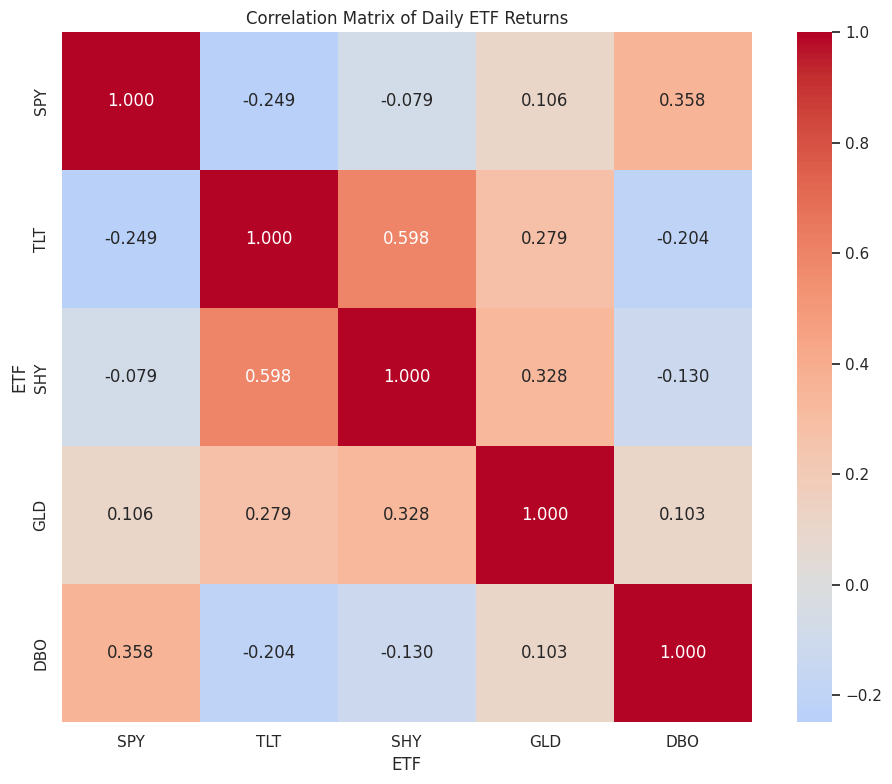


Correlation Findings
Strongest positive relationship: TLT and SHY = 0.598
Strongest negative relationship: SPY and TLT = -0.249
Weakest absolute relationship: SPY and SHY = -0.079


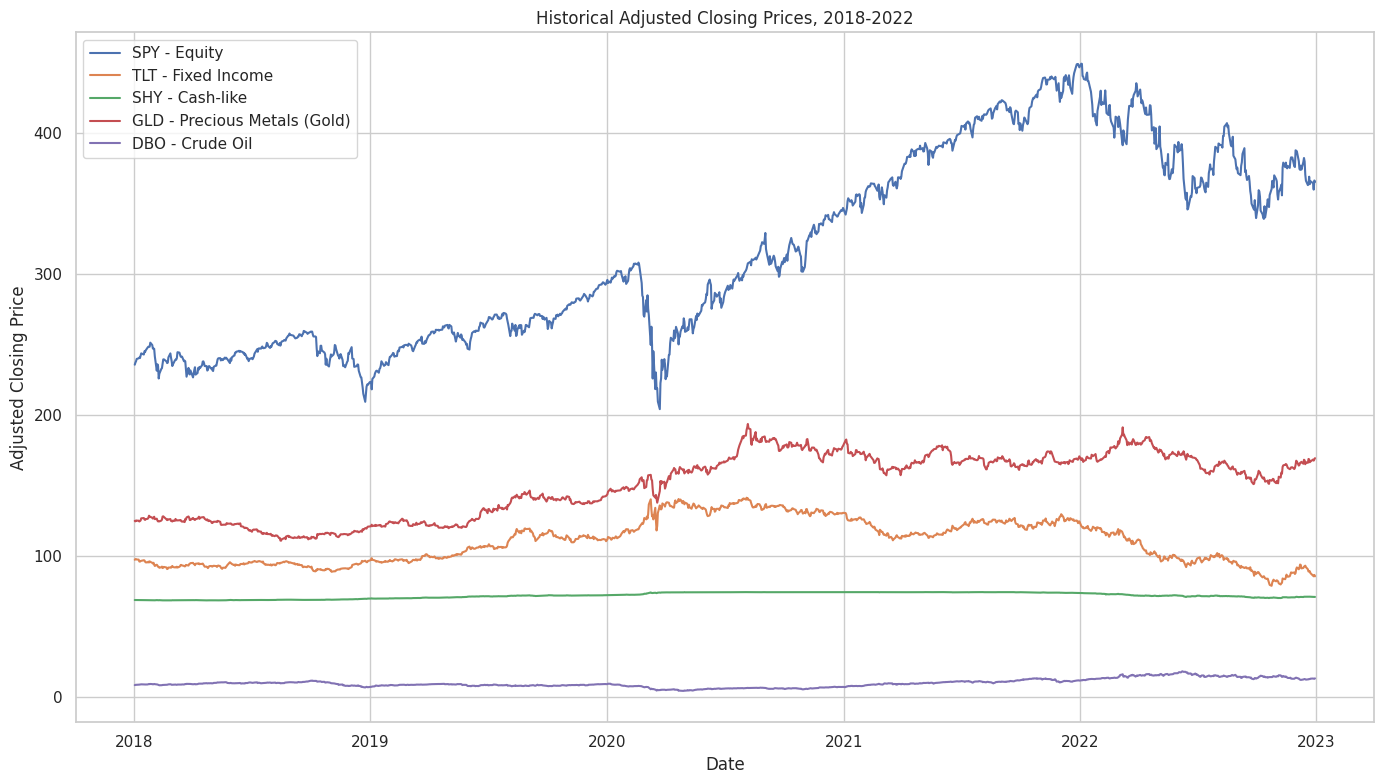

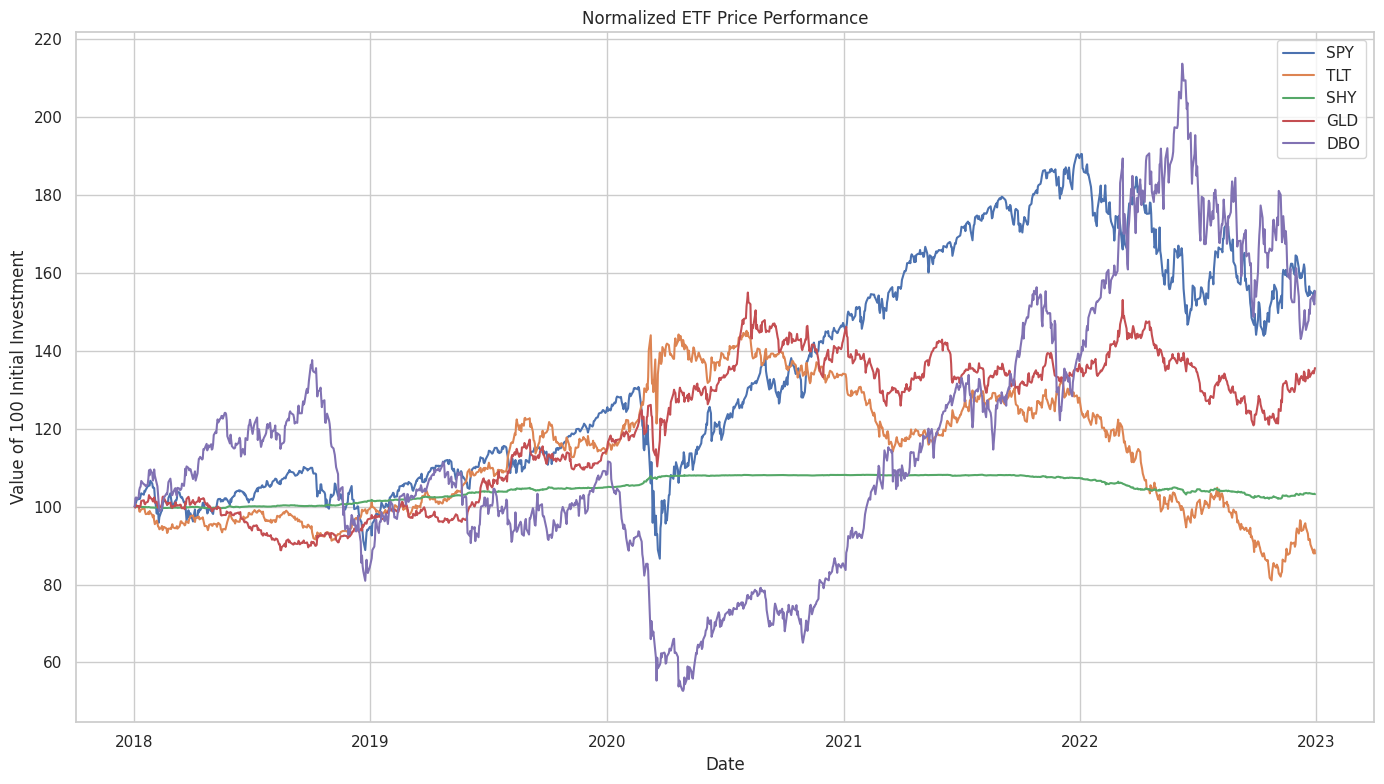

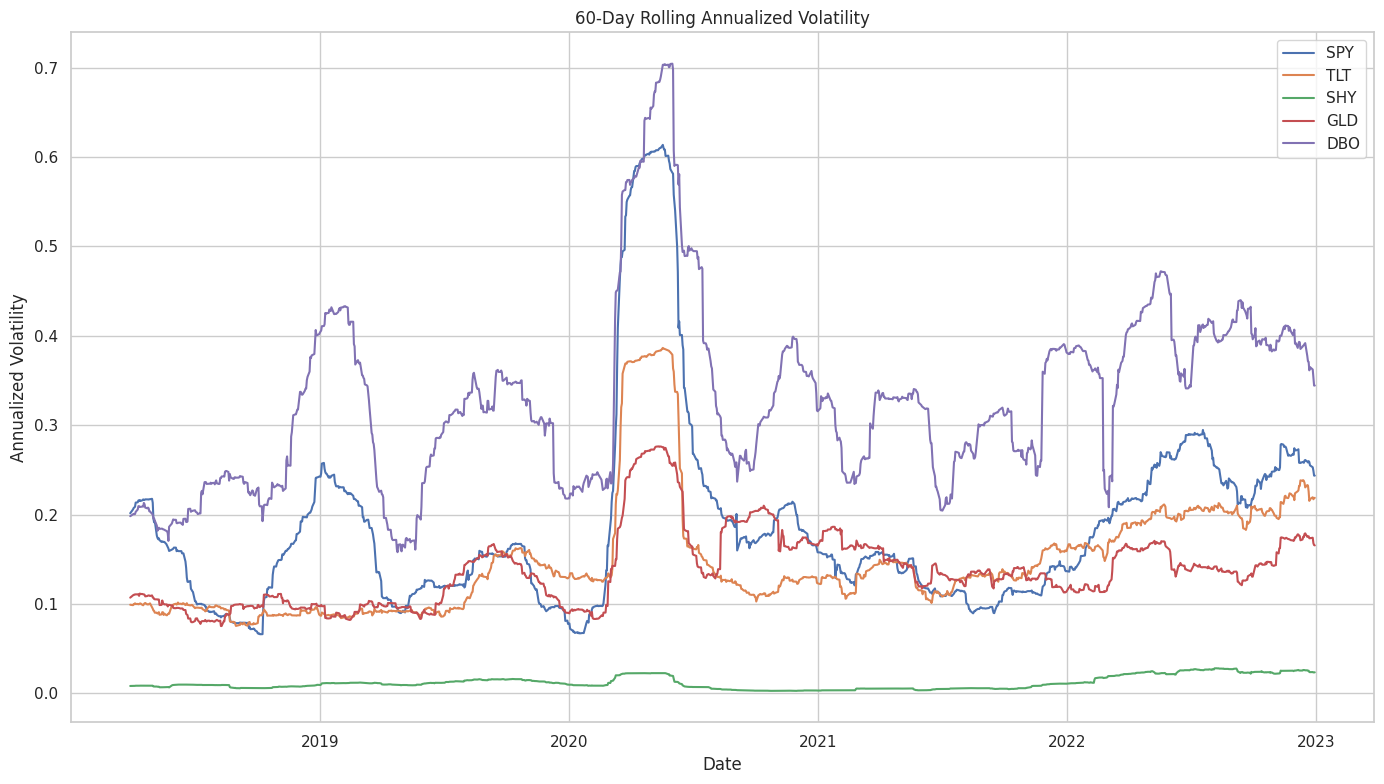


Table 6: Rolling Volatility Summary


,Average Annualized Volatility,Maximum Annualized Volatility,Minimum Annualized Volatility
Ticker,,,
SPY,0.187744,0.613724,0.065996
TLT,0.147111,0.386484,0.075304
SHY,0.011636,0.027896,0.002584
GLD,0.137902,0.276268,0.075176
DBO,0.330066,0.704593,0.157853



STEP 1: KEY NUMERICAL FINDINGS
Highest annualized mean return: DBO (14.78%)
Lowest annualized mean return: TLT (-1.26%)
Highest annualized volatility: DBO (34.32%)
Lowest annualized volatility: SHY (1.40%)
Strongest positive correlation: TLT and SHY (0.598)
Strongest negative correlation: SPY and TLT (-0.249)

STEP 2: 25-DAY-AHEAD RETURN PREDICTION
Input window: Previous 25 daily returns
Prediction target: Cumulative return over the following 25 trading days

Target formula:
R_(t,t+25) = P_(t+25) / P_t - 1

SPY:
Input shape: (1209, 25)
Target shape: (1209,)

TLT:
Input shape: (1209, 25)
Target shape: (1209,)

SHY:
Input shape: (1209, 25)
Target shape: (1209,)

GLD:
Input shape: (1209, 25)
Target shape: (1209,)

DBO:
Input shape: (1209, 25)
Target shape: (1209,)

25-Day Target Verification
Example asset: SPY
Number of historical daily returns used as input: 25
Example 25-day-ahead target: 0.02738422629916415
SPY: Training observations = 967, Testing observations = 242
TLT: Training obs

,Asset Class,Training MSE,Training RMSE,Training MAE,Training R2,Test MSE,Test RMSE,Test MAE,Test R2
ETF,,,,,,,,,
SPY,Equity,0.002038,0.045146,0.032568,0.360767,0.019494,0.139620,0.112887,-3.545448
TLT,Fixed Income,0.002376,0.048741,0.030489,-0.425170,0.026006,0.161264,0.128803,-6.521020
SHY,Cash-like,0.003534,0.059445,0.037954,-229.783055,0.040468,0.201167,0.152657,-851.719258
GLD,Precious Metals (Gold),0.002503,0.050029,0.030230,-0.542553,0.014667,0.121108,0.096314,-6.306070
DBO,Crude Oil,0.005925,0.076977,0.051986,0.499168,0.044948,0.212010,0.169160,-3.706983



Report-ready performance table:


,Asset Class,Training MSE,Training RMSE,Training MAE,Training R2,Test MSE,Test RMSE,Test MAE,Test R2
ETF,,,,,,,,,
SPY,Equity,0.002038,0.045146,0.032568,0.360767,0.019494,0.139620,0.112887,-3.545448
TLT,Fixed Income,0.002376,0.048741,0.030489,-0.425170,0.026006,0.161264,0.128803,-6.521020
SHY,Cash-like,0.003534,0.059445,0.037954,-229.783055,0.040468,0.201167,0.152657,-851.719258
GLD,Precious Metals (Gold),0.002503,0.050029,0.030230,-0.542553,0.014667,0.121108,0.096314,-6.306070
DBO,Crude Oil,0.005925,0.076977,0.051986,0.499168,0.044948,0.212010,0.169160,-3.706983


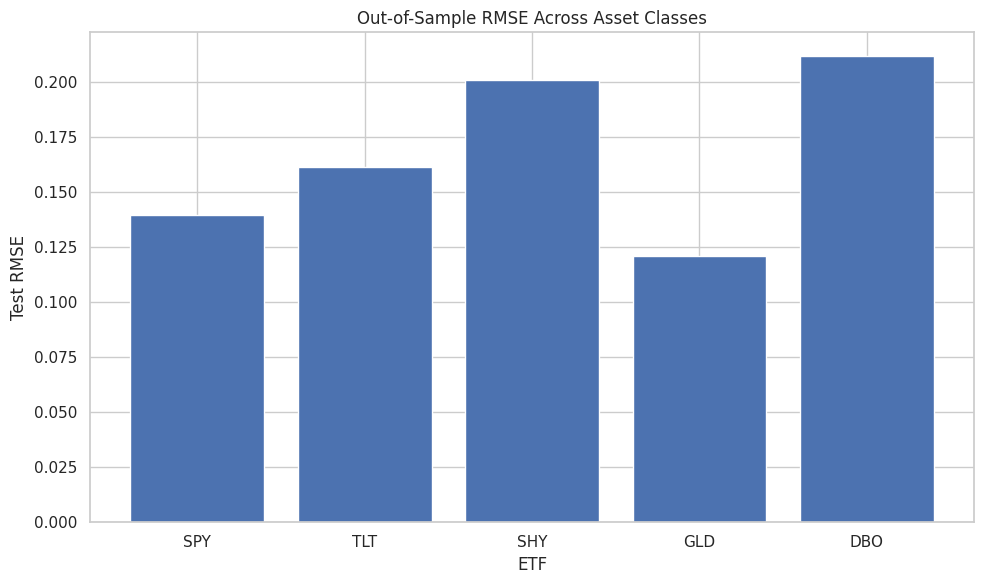

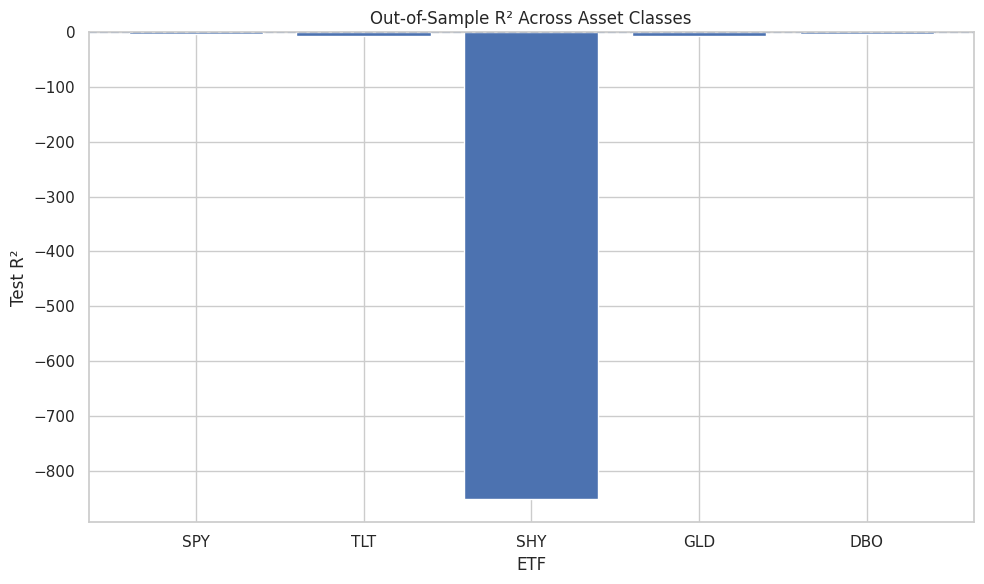

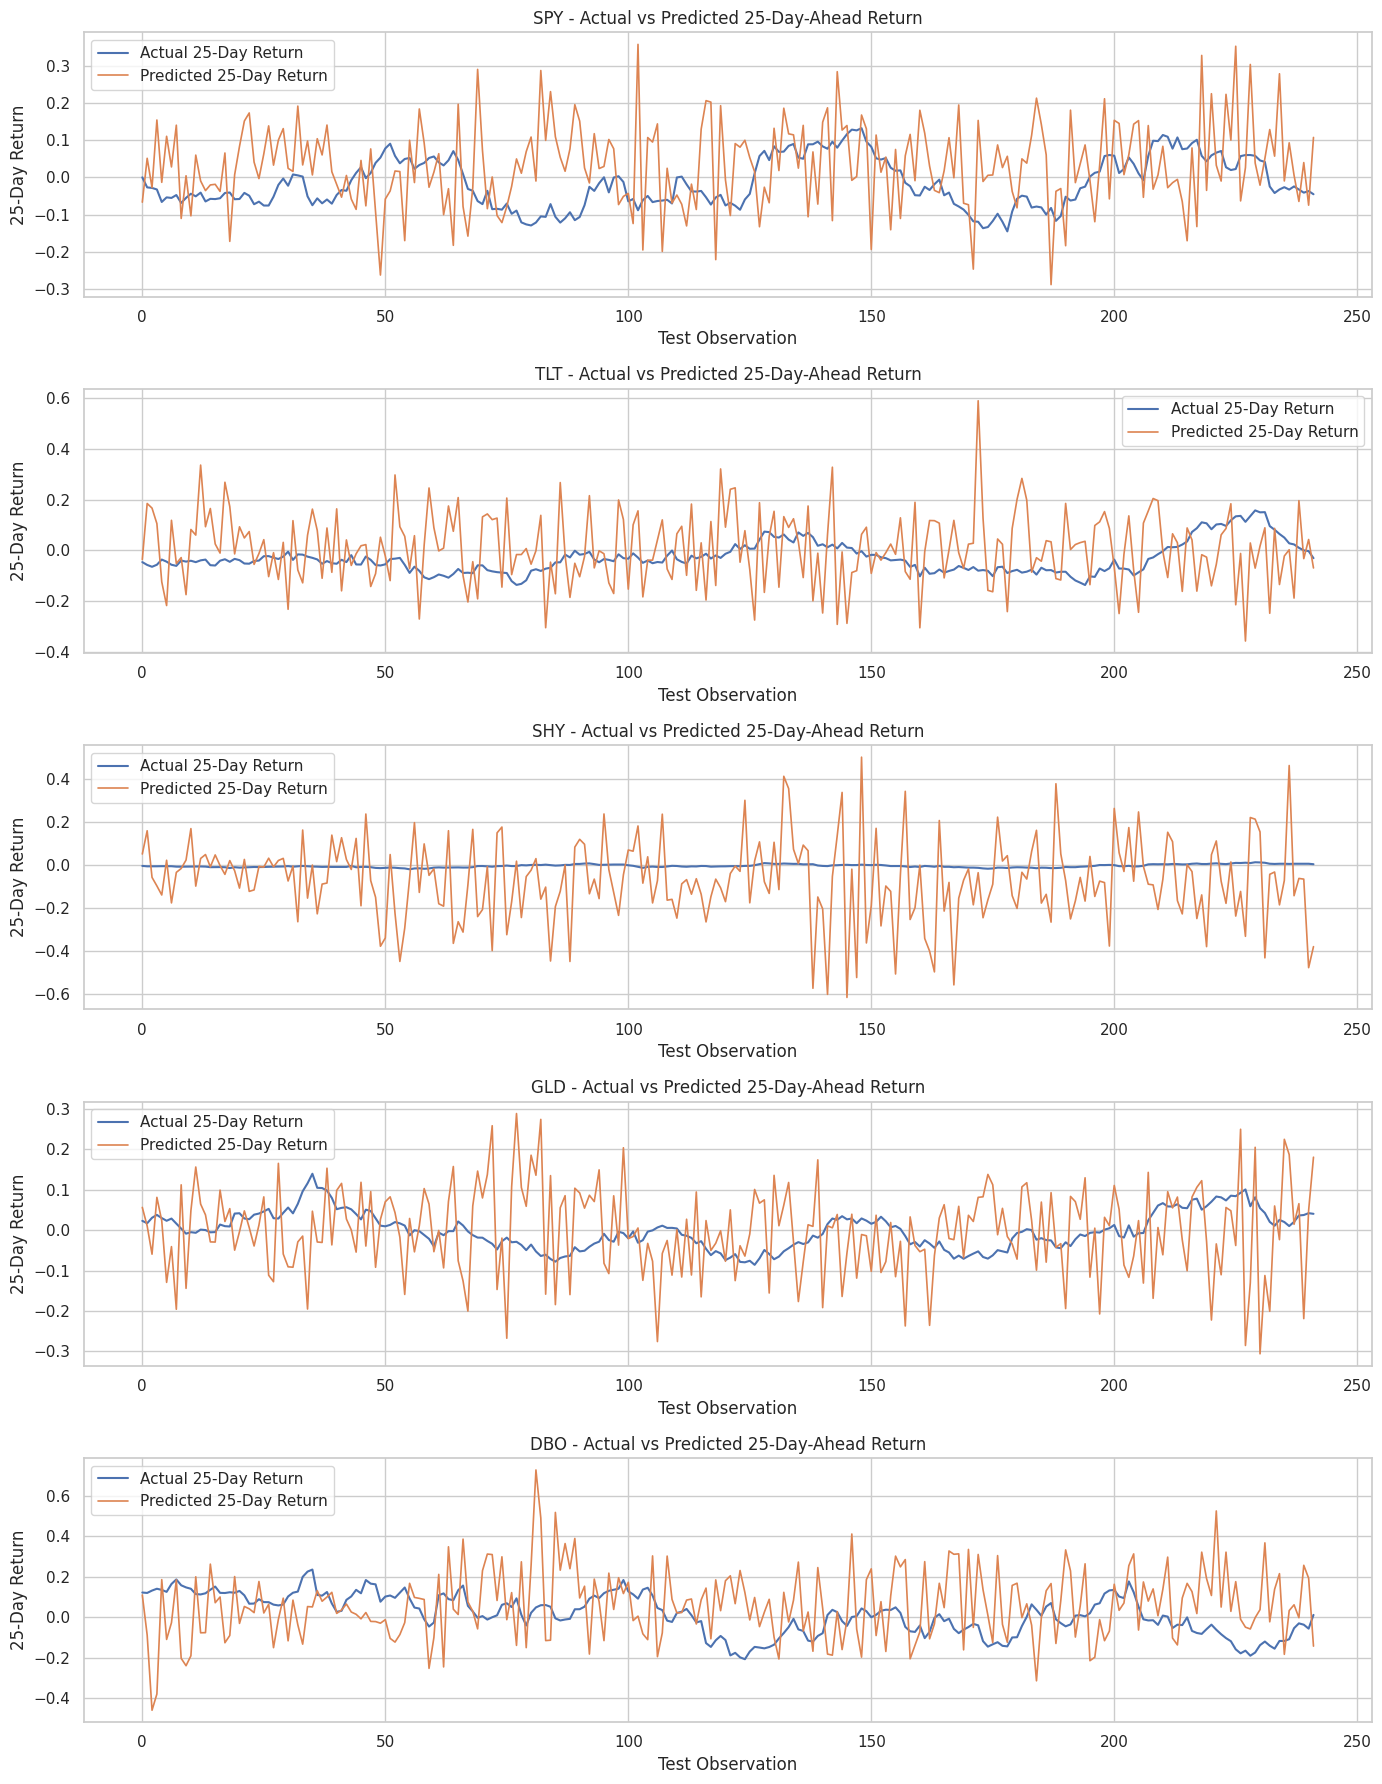

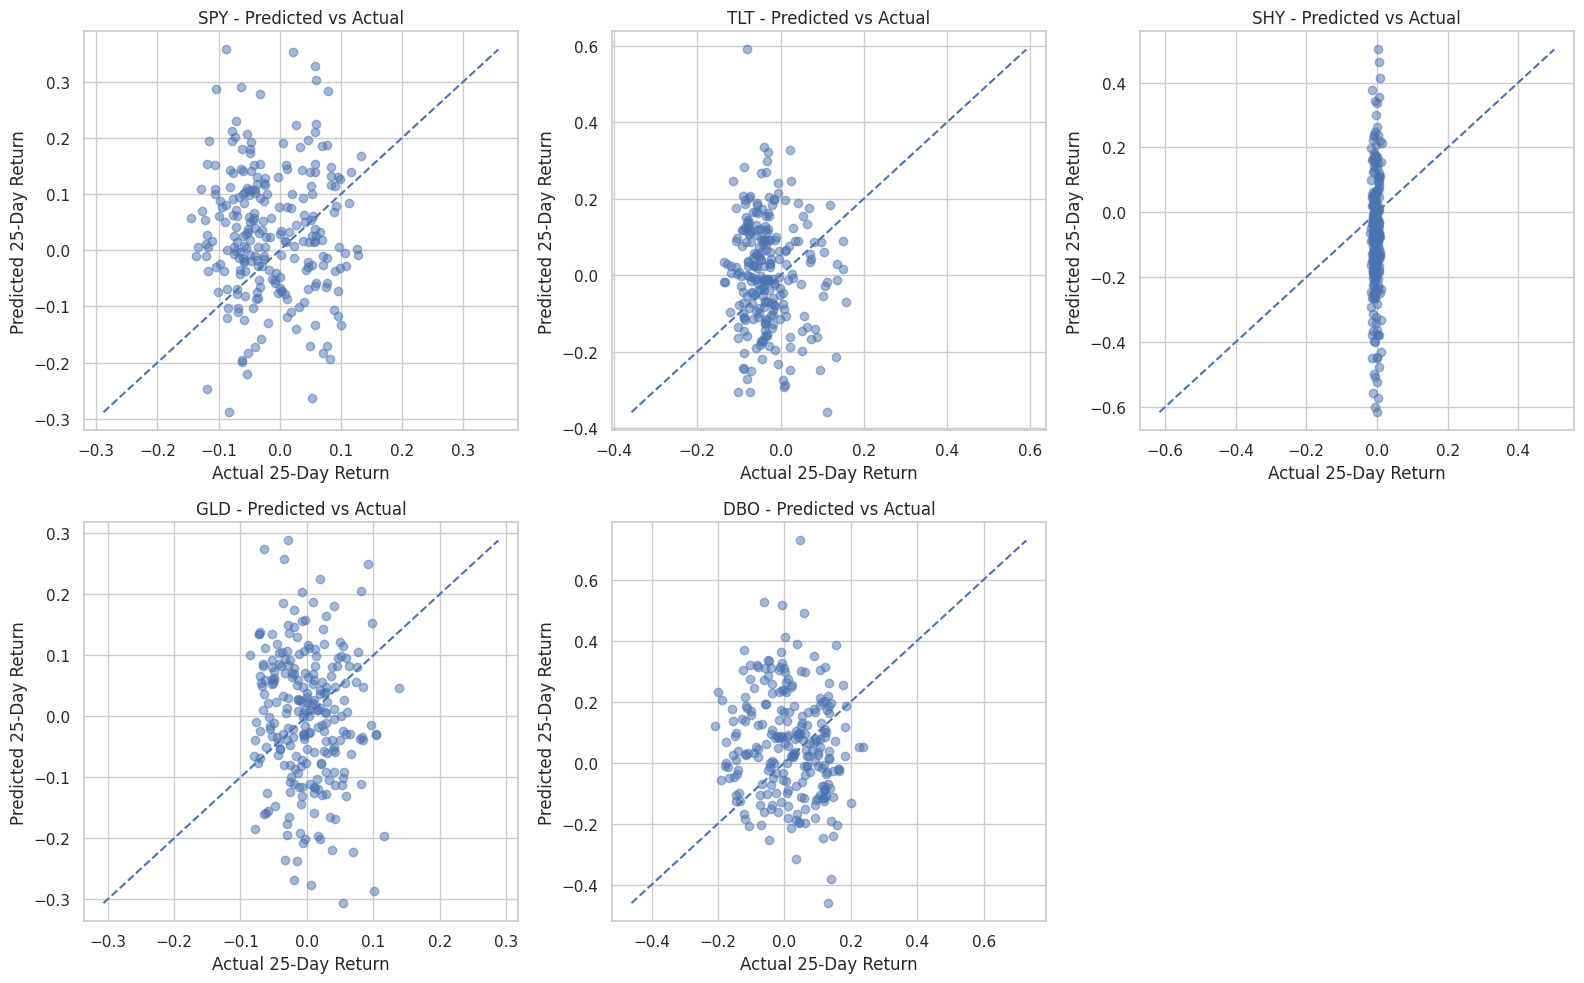


Table 8: In-Sample vs Out-of-Sample Comparison


,Training R2,Test R2,Training RMSE,Test RMSE,R2 Difference,RMSE Increase
ETF,,,,,,
SPY,0.360767,-3.545448,0.045146,0.139620,3.906215,0.094474
TLT,-0.425170,-6.521020,0.048741,0.161264,6.095850,0.112524
SHY,-229.783055,-851.719258,0.059445,0.201167,621.936203,0.141722
GLD,-0.542553,-6.306070,0.050029,0.121108,5.763518,0.071079
DBO,0.499168,-3.706983,0.076977,0.212010,4.206151,0.135033




STEP 2: KEY NUMERICAL FINDINGS
Lowest out-of-sample RMSE: GLD = 0.121108
Highest out-of-sample RMSE: DBO = 0.212010
Highest out-of-sample R²: SPY = -3.545448
Lowest out-of-sample R²: SHY = -851.719258


STEP 2: DETAILED INTERPRETATION

SPY - Equity
------------------------------------------------------------
Training R²: 0.360767
Out-of-sample R²: -3.545448
Training RMSE: 0.045146
Out-of-sample RMSE: 0.139620
Interpretation: The negative out-of-sample R² indicates that the prediction errors are larger than those of the mean-based benchmark.
The increase in RMSE from training to testing indicates weaker predictive performance on unseen observations.

TLT - Fixed Income
------------------------------------------------------------
Training R²: -0.425170
Out-of-sample R²: -6.521020
Training RMSE: 0.048741
Out-of-sample RMSE: 0.161264
Interpretation: The negative out-of-sample R² indicates that the prediction errors are larger than those of the mean-based benchmark.
The increase in RMSE f

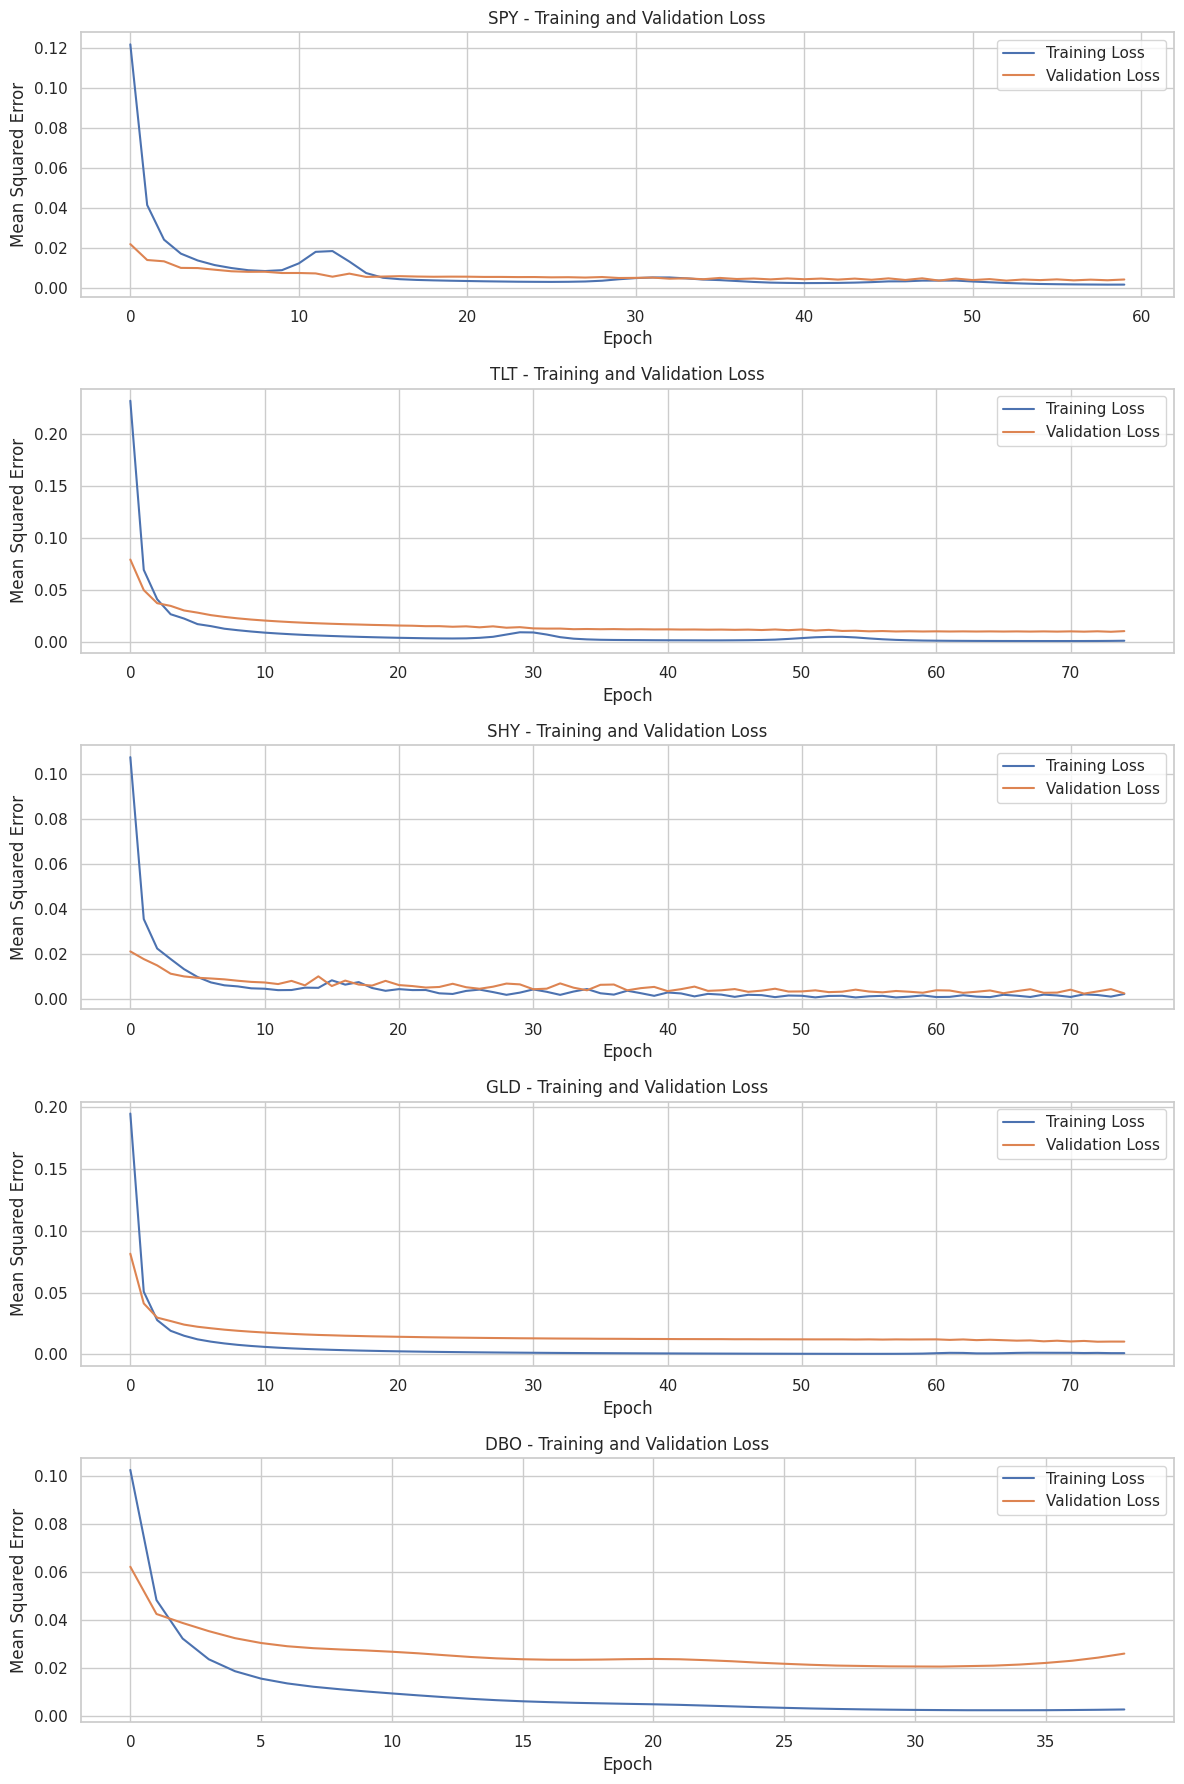



ALL RESULT TABLES HAVE BEEN SAVED

Files created:
1. Dataset_Description.csv
2. Step1_Summary_Statistics.csv
3. Step1_Risk_Return_Table.csv
4. Step1_ADF_Results.csv
5. Step1_Correlation_Matrix.csv
6. Step1_Covariance_Matrix.csv
7. Step1_Volatility_Summary.csv
8. Step2_Predictive_Performance.csv
9. Step2_Training_Test_Comparison.csv


MScFE 642 GWP1 - TEAM MEMBER A
STEP 1 AND STEP 2 COMPLETED

Step 1 includes:
✓ Dataset description
✓ Daily adjusted prices
✓ Daily returns
✓ Summary statistics
✓ Individual return distributions
✓ ADF stationarity test
✓ Correlation matrix
✓ Covariance matrix
✓ Price trends
✓ Normalized price comparison
✓ Rolling volatility

Step 2 includes:
✓ 25-day-ahead cumulative return target
✓ 25 historical daily returns as inputs
✓ Chronological train/test separation
✓ Training and validation procedure
✓ Out-of-sample testing
✓ MSE
✓ RMSE
✓ MAE
✓ R²
✓ Actual versus predicted plots
✓ In-sample versus out-of-sample comparison
✓ Numerical interpretation
✓ Investment-o

In [6]:
summary_stats.to_csv(
    "Step1_Summary_Statistics.csv"
)


risk_return_table.to_csv(
    "Step1_Risk_Return_Table.csv"
)


adf_table.to_csv(
    "Step1_ADF_Results.csv"
)


correlation_matrix.to_csv(
    "Step1_Correlation_Matrix.csv"
)


covariance_matrix.to_csv(
    "Step1_Covariance_Matrix.csv"
)


volatility_comparison.to_csv(
    "Step1_Volatility_Summary.csv"
)


performance_table.to_csv(
    "Step2_Predictive_Performance.csv"
)


comparison_table.to_csv(
    "Step2_Training_Test_Comparison.csv"
)


dataset_description.to_csv(
    "Dataset_Description.csv",
    index=False
)


print("\n")
print("=" * 70)

print(
    "ALL RESULT TABLES HAVE BEEN SAVED"
)

print("=" * 70)


print(
    "\nFiles created:"
)


print(
    "1. Dataset_Description.csv"
)

print(
    "2. Step1_Summary_Statistics.csv"
)

print(
    "3. Step1_Risk_Return_Table.csv"
)

print(
    "4. Step1_ADF_Results.csv"
)

print(
    "5. Step1_Correlation_Matrix.csv"
)

print(
    "6. Step1_Covariance_Matrix.csv"
)

print(
    "7. Step1_Volatility_Summary.csv"
)

print(
    "8. Step2_Predictive_Performance.csv"
)

print(
    "9. Step2_Training_Test_Comparison.csv"
)


# FINAL CHECK

print("\n")
print("=" * 70)

print(
    " - MULTI-ASSET ANALYSIS COMPLETED"
)

print(
    "STEP 1 AND STEP 2 COMPLETED"
)

print("=" * 70)


print(
    "\nStep 1 includes:"
)

print(
    "✓ Dataset description"
)

print(
    "✓ Daily adjusted prices"
)

print(
    "✓ Daily returns"
)

print(
    "✓ Summary statistics"
)

print(
    "✓ Individual return distributions"
)

print(
    "✓ ADF stationarity test"
)

print(
    "✓ Correlation matrix"
)

print(
    "✓ Covariance matrix"
)

print(
    "✓ Price trends"
)

print(
    "✓ Normalized price comparison"
)

print(
    "✓ Rolling volatility"
)


print(
    "\nStep 2 includes:"
)

print(
    "✓ 25-day-ahead cumulative return target"
)

print(
    "✓ 25 historical daily returns as inputs"
)

print(
    "✓ Chronological train/test separation"
)

print(
    "✓ Training and validation procedure"
)

print(
    "✓ Out-of-sample testing"
)

print(
    "✓ MSE"
)

print(
    "✓ RMSE"
)

print(
    "✓ MAE"
)

print(
    "✓ R²"
)

print(
    "✓ Actual versus predicted plots"
)

print(
    "✓ In-sample versus out-of-sample comparison"
)

print(
    "✓ Numerical interpretation"
)

print(
    "✓ Investment-oriented interpretation"
)


print("\nNotebook execution completed.")


## CNN Models Using Gramian Angular Field (GAF)


In [7]:
print("\n============================================================")
print("CNN MODELS USING GAF REPRESENTATION")
print("============================================================")

# Additional libraries for GAF and CNN

from tensorflow.keras.layers import (
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dropout
)

from sklearn.preprocessing import MinMaxScaler



STEP 3: CNN MODELS USING GAF REPRESENTATION


## GAF Transformation Function


In [8]:
def create_gaf(sequence):
    """
    Convert a one-dimensional time series into a
    Gramian Angular Summation Field (GASF).
    """

    sequence = np.asarray(sequence, dtype=np.float64)

    # Scale the sequence to [-1, 1]

    min_value = np.min(sequence)
    max_value = np.max(sequence)

    # Avoid division by zero if all observations are identical
    if max_value == min_value:

        scaled_sequence = np.zeros_like(sequence)

    else:

        scaled_sequence = (
            2 * (sequence - min_value)
            / (max_value - min_value)
            - 1
        )

    # Numerical protection
    scaled_sequence = np.clip(
        scaled_sequence,
        -1,
        1
    )

    # Angular representation

    phi = np.arccos(
        scaled_sequence
    )

    # Gramian Angular Summation Field
    #
    # G_ij = cos(phi_i + phi_j)

    gaf = np.cos(
        phi[:, None]
        +
        phi[None, :]
    )

    return gaf


## Verify GAF Transformation


In [9]:
example_symbol = "SPY"

example_sequence = (
    sequence_data[
        example_symbol
    ]["X"][0]
)

example_gaf = (
    create_gaf(
        example_sequence
    )
)

print("\nGAF Transformation Verification")
print("=" * 60)

print(
    "Original sequence shape:",
    example_sequence.shape
)

print(
    "GAF image shape:",
    example_gaf.shape
)



GAF Transformation Verification
Original sequence shape: (25,)
GAF image shape: (25, 25)


## Visualize Example GAF Representation


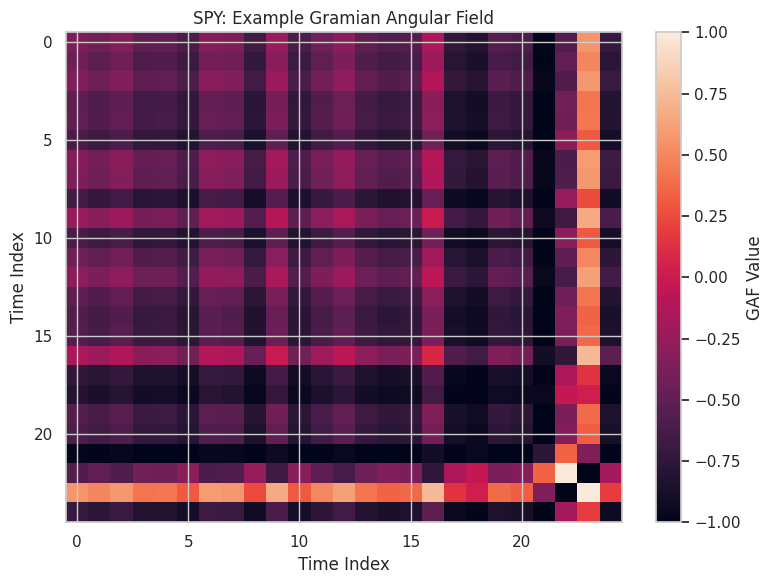

In [10]:
plt.figure(
    figsize=(8, 6)
)

plt.imshow(
    example_gaf,
    aspect="auto"
)

plt.colorbar(
    label="GAF Value"
)

plt.title(
    f"{example_symbol}: Example Gramian Angular Field"
)

plt.xlabel(
    "Time Index"
)

plt.ylabel(
    "Time Index"
)

plt.tight_layout()

plt.show()


## CREATE GAF DATASETS FOR ALL ETFs


In [11]:
gaf_data = {}

for symbol in symbols:

    print(f"\nPreparing GAF data for {symbol}...")

    # Get the existing Step 2 sequences and targets

    X = sequence_data[symbol]["X"]

    y = sequence_data[symbol]["y"]

    # Chronological train/test split

    (
        X_train,
        X_test,
        y_train,
        y_test
    ) = chronological_split(
        X,
        y,
        test_size=TEST_SIZE
    )

    # Transform each 25-day sequence into a GAF image

    X_train_gaf = np.array([
        create_gaf(sequence)
        for sequence in X_train
    ])

    X_test_gaf = np.array([
        create_gaf(sequence)
        for sequence in X_test
    ])

    # Add channel dimension for CNN
    #
    # Required shape:
    # (samples, height, width, channels)

    X_train_gaf = np.expand_dims(
        X_train_gaf,
        axis=-1
    )

    X_test_gaf = np.expand_dims(
        X_test_gaf,
        axis=-1
    )

    # Store the prepared data

    gaf_data[symbol] = {

        "X_train": X_train_gaf,

        "X_test": X_test_gaf,

        "y_train": y_train,

        "y_test": y_test

    }

    # Display shapes

    print(
        f"Training GAF shape: "
        f"{X_train_gaf.shape}"
    )

    print(
        f"Testing GAF shape: "
        f"{X_test_gaf.shape}"
    )



Preparing GAF data for SPY...
Training GAF shape: (967, 25, 25, 1)
Testing GAF shape: (242, 25, 25, 1)

Preparing GAF data for TLT...
Training GAF shape: (967, 25, 25, 1)
Testing GAF shape: (242, 25, 25, 1)

Preparing GAF data for SHY...
Training GAF shape: (967, 25, 25, 1)
Testing GAF shape: (242, 25, 25, 1)

Preparing GAF data for GLD...
Training GAF shape: (967, 25, 25, 1)
Testing GAF shape: (242, 25, 25, 1)

Preparing GAF data for DBO...
Training GAF shape: (967, 25, 25, 1)
Testing GAF shape: (242, 25, 25, 1)


## Build CNN Model


In [12]:
def build_cnn_model(input_shape):

    model = Sequential([

        # Input Layer

        Input(
            shape=input_shape
        ),

        # First Convolutional Block

        Conv2D(
            filters=32,
            kernel_size=(3, 3),
            activation="relu",
            padding="same"
        ),

        MaxPooling2D(
            pool_size=(2, 2)
        ),

        # Second Convolutional Block

        Conv2D(
            filters=64,
            kernel_size=(3, 3),
            activation="relu",
            padding="same"
        ),

        MaxPooling2D(
            pool_size=(2, 2)
        ),

        # Flatten Features

        Flatten(),

        # Dense Layers

        Dense(
            64,
            activation="relu"
        ),

        Dropout(
            0.20
        ),

        Dense(
            32,
            activation="relu"
        ),

        # Output Layer

        Dense(
            1
        )

    ])

    # Compile Model

    model.compile(
        optimizer="adam",
        loss="mse"
    )

    return model


# VERIFY CNN ARCHITECTURE

example_cnn_model = build_cnn_model(
    input_shape=(
        LOOKBACK,
        LOOKBACK,
        1
    )
)

print("\nCNN Model Architecture")
print("=" * 60)

example_cnn_model.summary()



CNN Model Architecture


Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 25, 25, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 168,449 (658.00 KB)

 Trainable params: 168,449 (658.00 KB)

 Non-trainable params: 0 (0.00 B)

## TRAIN CNN MODELS FOR ALL ETFs


In [13]:
cnn_results = []

cnn_predictions = {}

cnn_actual_values = {}

cnn_training_histories = {}

cnn_models = {}


for symbol in symbols:

    print("\n")
    print("=" * 60)
    print(
        f"Training CNN model for "
        f"{symbol} - {etfs[symbol]}"
    )
    print("=" * 60)


    # Get GAF data

    X_train = gaf_data[symbol]["X_train"]

    X_test = gaf_data[symbol]["X_test"]

    y_train = gaf_data[symbol]["y_train"]

    y_test = gaf_data[symbol]["y_test"]


    # Build CNN model

    model = build_cnn_model(
        input_shape=X_train.shape[1:]
    )


    # Early stopping

    early_stopping = EarlyStopping(

        monitor="val_loss",

        patience=10,

        restore_best_weights=True

    )


    # Train model

    history = model.fit(

        X_train,

        y_train,

        validation_split=0.20,

        epochs=100,

        batch_size=32,

        callbacks=[
            early_stopping
        ],

        verbose=0,

        shuffle=False

    )


    # Generate predictions

    train_predictions = (
        model
        .predict(
            X_train,
            verbose=0
        )
        .flatten()
    )


    test_predictions = (
        model
        .predict(
            X_test,
            verbose=0
        )
        .flatten()
    )


    # Calculate performance metrics

    train_metrics = calculate_metrics(
        y_train,
        train_predictions
    )


    test_metrics = calculate_metrics(
        y_test,
        test_predictions
    )


    # Store results

    cnn_results.append({

        "ETF":
            symbol,

        "Asset Class":
            etfs[symbol],


        # Training / In-Sample

        "Training MSE":
            train_metrics["MSE"],

        "Training RMSE":
            train_metrics["RMSE"],

        "Training MAE":
            train_metrics["MAE"],

        "Training R2":
            train_metrics["R2"],


        # Testing / Out-of-Sample

        "Test MSE":
            test_metrics["MSE"],

        "Test RMSE":
            test_metrics["RMSE"],

        "Test MAE":
            test_metrics["MAE"],

        "Test R2":
            test_metrics["R2"]

    })


    # Store predictions and models

    cnn_predictions[symbol] = test_predictions

    cnn_actual_values[symbol] = y_test

    cnn_training_histories[symbol] = history

    cnn_models[symbol] = model


    # Print results

    print(
        f"\n{symbol} Results"
    )

    print("-" * 40)

    print(
        f"Training RMSE: "
        f"{train_metrics['RMSE']:.6f}"
    )

    print(
        f"Training R²: "
        f"{train_metrics['R2']:.6f}"
    )

    print(
        f"Test RMSE: "
        f"{test_metrics['RMSE']:.6f}"
    )

    print(
        f"Test R²: "
        f"{test_metrics['R2']:.6f}"
    )




Training CNN model for SPY - Equity

SPY Results
----------------------------------------
Training RMSE: 0.056106
Training R²: 0.012722
Test RMSE: 0.074502
Test R²: -0.294247


Training CNN model for TLT - Fixed Income

TLT Results
----------------------------------------
Training RMSE: 0.040936
Training R²: -0.005279
Test RMSE: 0.072388
Test R²: -0.515426


Training CNN model for SHY - Cash-like

SHY Results
----------------------------------------
Training RMSE: 0.004128
Training R²: -0.113017
Test RMSE: 0.010282
Test R²: -1.227647


Training CNN model for GLD - Precious Metals (Gold)

GLD Results
----------------------------------------
Training RMSE: 0.038660
Training R²: 0.078836
Test RMSE: 0.046923
Test R²: -0.096777


Training CNN model for DBO - Crude Oil

DBO Results
----------------------------------------
Training RMSE: 0.094319
Training R²: 0.248079
Test RMSE: 0.102480
Test R²: -0.099791


## CNN Performance Results Table


In [14]:
cnn_results_df = pd.DataFrame(cnn_results)

# Round values for presentation

cnn_results_display = cnn_results_df.copy()

numeric_columns = cnn_results_display.select_dtypes(
    include=[np.number]
).columns

cnn_results_display[numeric_columns] = (
    cnn_results_display[numeric_columns].round(6)
)

print("\n")
print("=" * 100)
print("CNN WITH GAF REPRESENTATION - PERFORMANCE RESULTS")
print("=" * 100)

print(
    cnn_results_display.to_string(
        index=False
    )
)




STEP 3: CNN WITH GAF REPRESENTATION - PERFORMANCE RESULTS
ETF            Asset Class  Training MSE  Training RMSE  Training MAE  Training R2  Test MSE  Test RMSE  Test MAE   Test R2
SPY                 Equity      0.003148       0.056106      0.035454     0.012722  0.005551   0.074502  0.064533 -0.294247
TLT           Fixed Income      0.001676       0.040936      0.031358    -0.005279  0.005240   0.072388  0.063509 -0.515426
SHY              Cash-like      0.000017       0.004128      0.003291    -0.113017  0.000106   0.010282  0.008770 -1.227647
GLD Precious Metals (Gold)      0.001495       0.038660      0.030855     0.078836  0.002202   0.046923  0.038874 -0.096777
DBO              Crude Oil      0.008896       0.094319      0.070047     0.248079  0.010502   0.102480  0.085633 -0.099791


## CNN Out-Of-Sample Performance Summary


In [15]:
cnn_test_summary = cnn_results_df[[
    "ETF",
    "Asset Class",
    "Test MSE",
    "Test RMSE",
    "Test MAE",
    "Test R2"
]].copy()

cnn_test_summary = cnn_test_summary.sort_values(
    by="Test RMSE"
)

print("\n")
print("=" * 80)
print("CNN OUT-OF-SAMPLE PERFORMANCE SUMMARY")
print("=" * 80)

print(
    cnn_test_summary.round(6).to_string(
        index=False
    )
)




CNN OUT-OF-SAMPLE PERFORMANCE SUMMARY
ETF            Asset Class  Test MSE  Test RMSE  Test MAE   Test R2
SHY              Cash-like  0.000106   0.010282  0.008770 -1.227647
GLD Precious Metals (Gold)  0.002202   0.046923  0.038874 -0.096777
TLT           Fixed Income  0.005240   0.072388  0.063509 -0.515426
SPY                 Equity  0.005551   0.074502  0.064533 -0.294247
DBO              Crude Oil  0.010502   0.102480  0.085633 -0.099791


## Actual Vs Predicted Returns


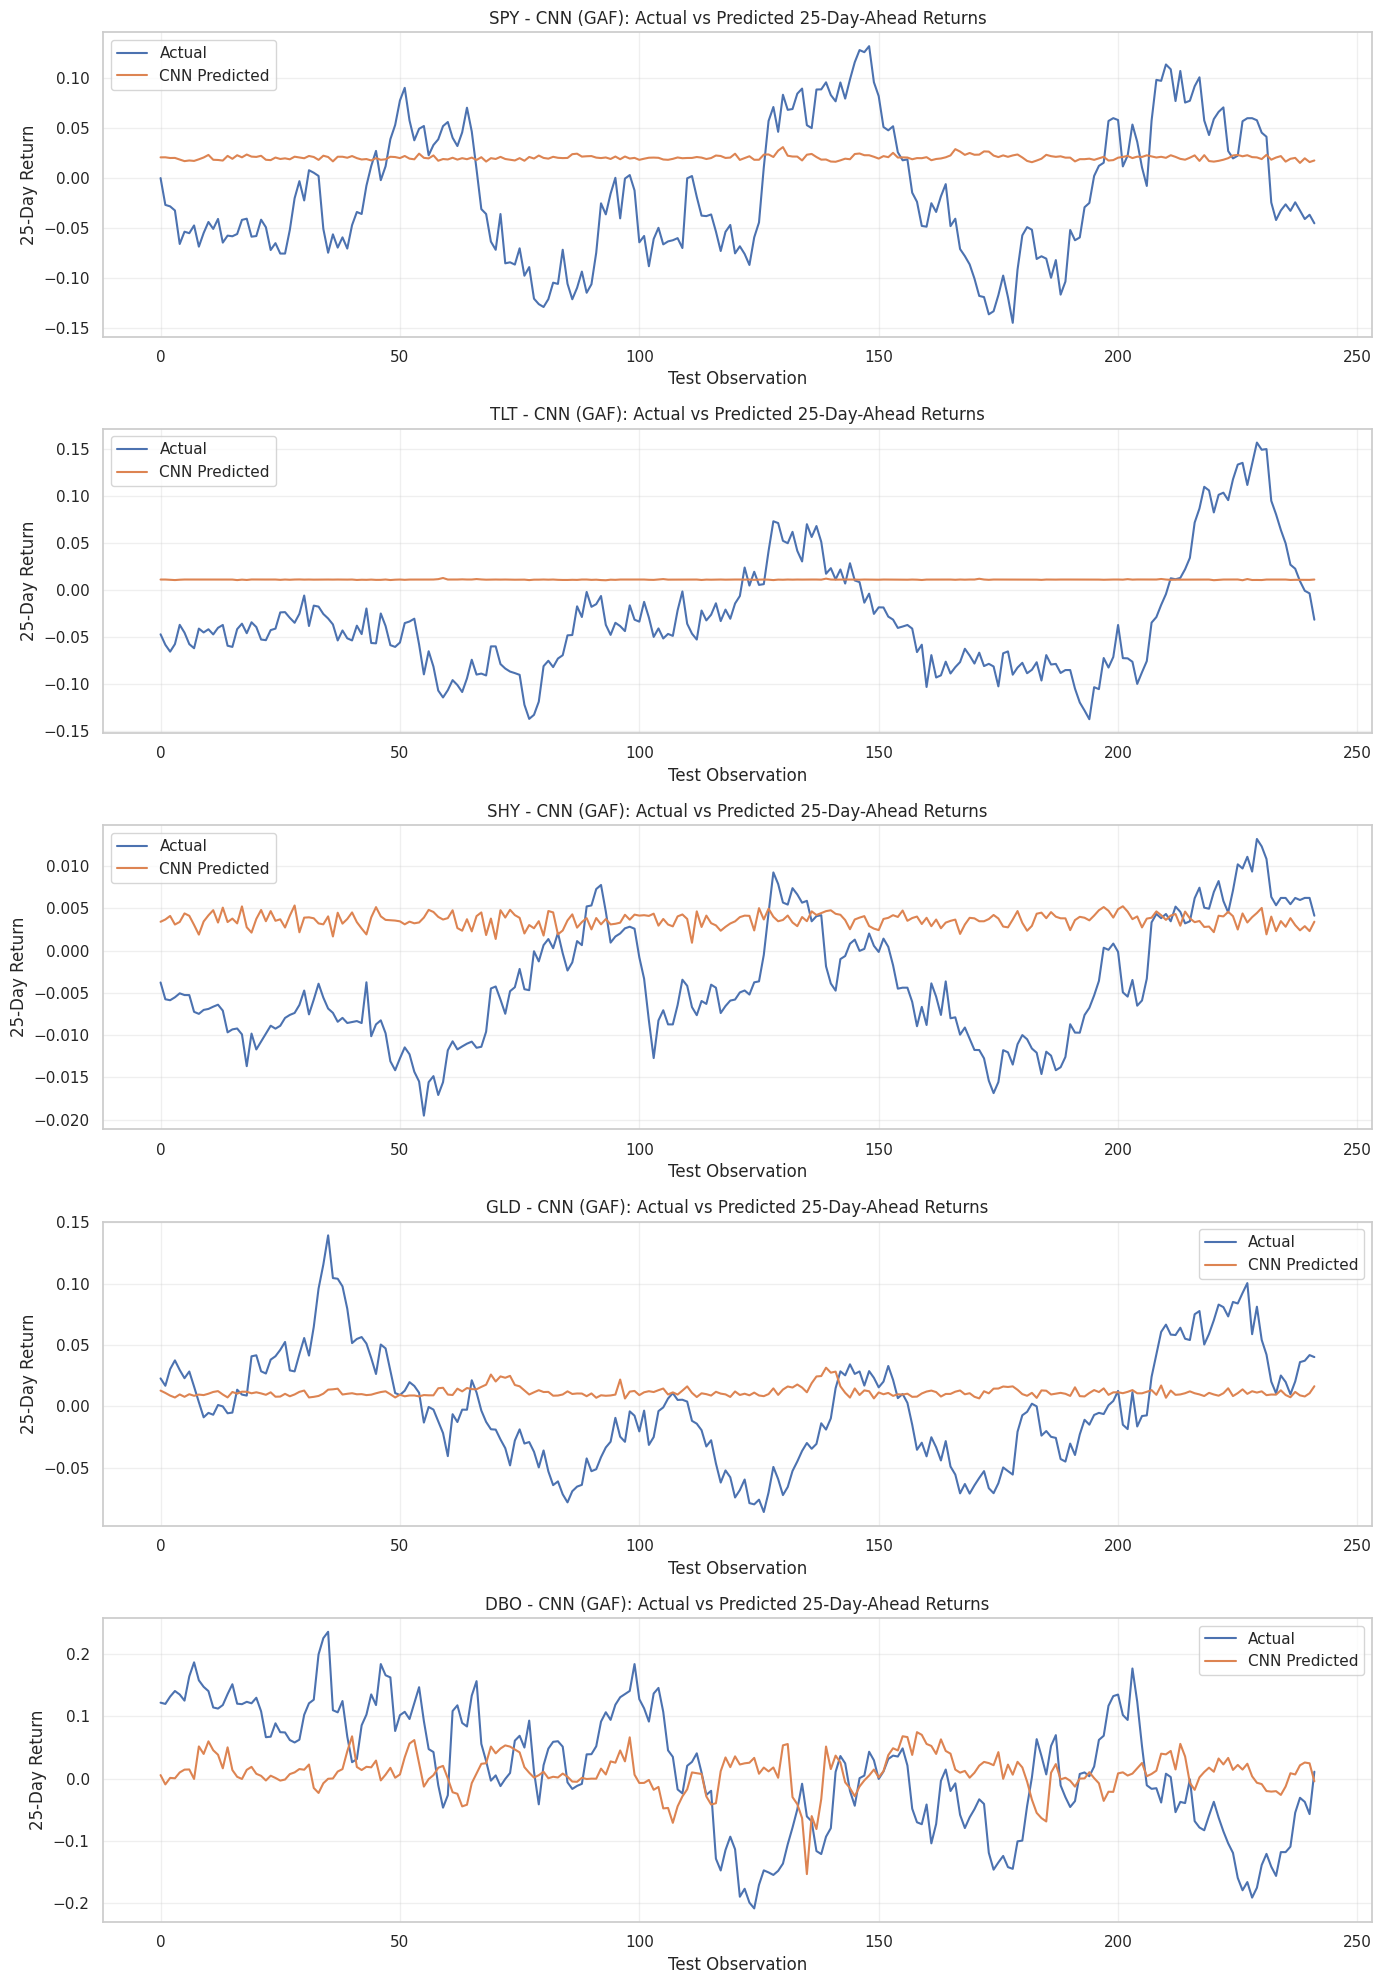

In [16]:
fig, axes = plt.subplots(
    nrows=5,
    ncols=1,
    figsize=(14, 20)
)

for i, symbol in enumerate(symbols):

    # Get actual and predicted values

    actual = cnn_actual_values[symbol]

    predicted = cnn_predictions[symbol]

    # Plot

    axes[i].plot(
        actual,
        label="Actual"
    )

    axes[i].plot(
        predicted,
        label="CNN Predicted"
    )

    axes[i].set_title(
        f"{symbol} - CNN (GAF): "
        f"Actual vs Predicted 25-Day-Ahead Returns"
    )

    axes[i].set_xlabel(
        "Test Observation"
    )

    axes[i].set_ylabel(
        "25-Day Return"
    )

    axes[i].legend()

    axes[i].grid(
        True,
        alpha=0.3
    )


plt.tight_layout()

plt.show()


## CNN Training And Validation Loss


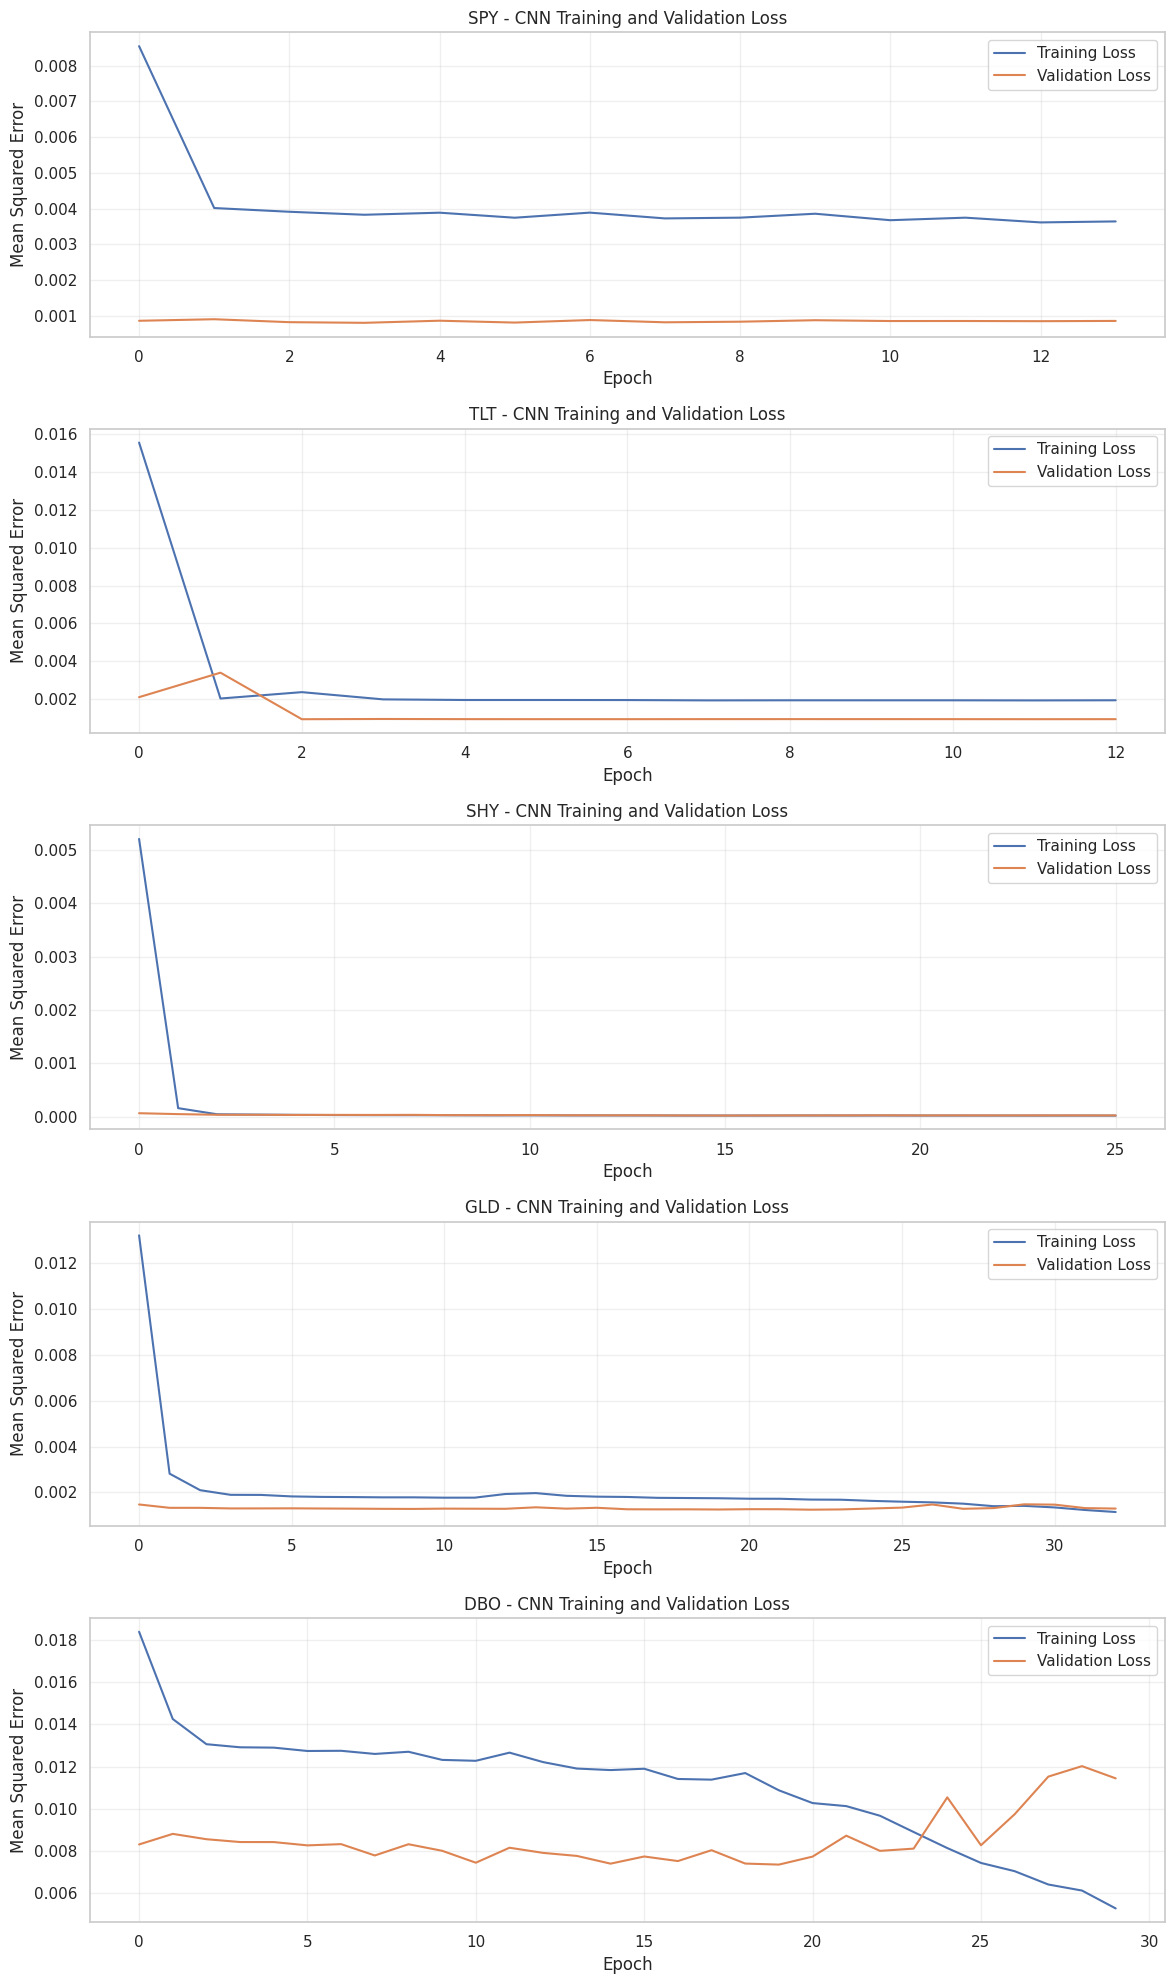

In [17]:
fig, axes = plt.subplots(
    nrows=5,
    ncols=1,
    figsize=(12, 20)
)

for i, symbol in enumerate(symbols):

    history = cnn_training_histories[symbol]

    axes[i].plot(
        history.history["loss"],
        label="Training Loss"
    )

    axes[i].plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    axes[i].set_title(
        f"{symbol} - CNN Training and Validation Loss"
    )

    axes[i].set_xlabel(
        "Epoch"
    )

    axes[i].set_ylabel(
        "Mean Squared Error"
    )

    axes[i].legend()

    axes[i].grid(
        True,
        alpha=0.3
    )


plt.tight_layout()

plt.show()


## CNN Training Epoch Summary


In [18]:
cnn_epoch_summary = []

for symbol in symbols:

    history = cnn_training_histories[symbol]

    epochs_trained = len(
        history.history["loss"]
    )

    best_epoch = (
        np.argmin(
            history.history["val_loss"]
        )
        + 1
    )

    cnn_epoch_summary.append({

        "ETF": symbol,

        "Epochs Trained": epochs_trained,

        "Best Validation Epoch": best_epoch,

        "Best Validation Loss":
            np.min(
                history.history["val_loss"]
            )

    })


cnn_epoch_summary_df = pd.DataFrame(
    cnn_epoch_summary
)

print("\n")
print("=" * 70)
print("CNN TRAINING SUMMARY")
print("=" * 70)

print(
    cnn_epoch_summary_df.round(6).to_string(
        index=False
    )
)




CNN TRAINING SUMMARY
ETF  Epochs Trained  Best Validation Epoch  Best Validation Loss
SPY              14                      4              0.000802
TLT              13                      3              0.000946
SHY              26                     16              0.000021
GLD              33                     23              0.001249
DBO              30                     20              0.007346


## Visual Comparison Of CNN Test Performance


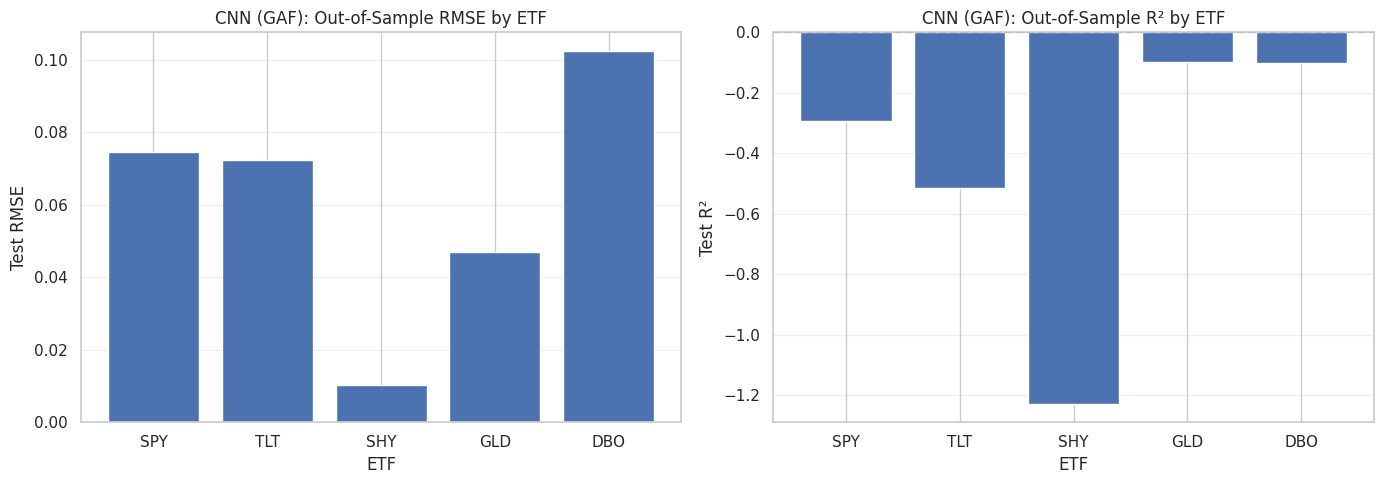

In [19]:
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5)
)

# Test RMSE

axes[0].bar(
    cnn_results_df["ETF"],
    cnn_results_df["Test RMSE"]
)

axes[0].set_title(
    "CNN (GAF): Out-of-Sample RMSE by ETF"
)

axes[0].set_xlabel(
    "ETF"
)

axes[0].set_ylabel(
    "Test RMSE"
)

axes[0].grid(
    axis="y",
    alpha=0.3
)


# Test R²

axes[1].bar(
    cnn_results_df["ETF"],
    cnn_results_df["Test R2"]
)

axes[1].axhline(
    y=0,
    linestyle="--"
)

axes[1].set_title(
    "CNN (GAF): Out-of-Sample R² by ETF"
)

axes[1].set_xlabel(
    "ETF"
)

axes[1].set_ylabel(
    "Test R²"
)

axes[1].grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()

plt.show()


In [20]:
# LOAD STEP 2 RESULTS FOR COMPARISON

step2_results_df = pd.read_csv(
    "Step2_Predictive_Performance.csv"
)

step2_results_df.head()

,ETF,Asset Class,Training MSE,Training RMSE,Training MAE,Training R2,Test MSE,Test RMSE,Test MAE,Test R2
0,SPY,Equity,0.002038,0.045146,0.032568,0.360767,0.019494,0.139620,0.112887,-3.545448
1,TLT,Fixed Income,0.002376,0.048741,0.030489,-0.425170,0.026006,0.161264,0.128803,-6.521020
2,SHY,Cash-like,0.003534,0.059445,0.037954,-229.783055,0.040468,0.201167,0.152657,-851.719258
3,GLD,Precious Metals (Gold),0.002503,0.050029,0.030230,-0.542553,0.014667,0.121108,0.096314,-6.306070
4,DBO,Crude Oil,0.005925,0.076977,0.051986,0.499168,0.044948,0.212010,0.169160,-3.706983


## Feedforward and CNN Performance Comparison


In [21]:
# Select Step 2 performance metrics

step2_comparison = step2_results_df[[
    "ETF",
    "Training RMSE",
    "Training R2",
    "Test RMSE",
    "Test R2"
]].copy()


# Select CNN (Step 3) performance metrics

step3_comparison = cnn_results_df[[
    "ETF",
    "Training RMSE",
    "Training R2",
    "Test RMSE",
    "Test R2"
]].copy()


# Rename columns

step2_comparison.columns = [

    "ETF",

    "Step 2 Training RMSE",
    "Step 2 Training R2",

    "Step 2 Test RMSE",
    "Step 2 Test R2"
]


step3_comparison.columns = [

    "ETF",

    "CNN Training RMSE",
    "CNN Training R2",

    "CNN Test RMSE",
    "CNN Test R2"
]


# Merge results

model_comparison_df = pd.merge(

    step2_comparison,

    step3_comparison,

    on="ETF"

)


# Calculate improvement in test performance

model_comparison_df[
    "RMSE Improvement"
] = (

    model_comparison_df[
        "Step 2 Test RMSE"
    ]

    -

    model_comparison_df[
        "CNN Test RMSE"
    ]

)


model_comparison_df[
    "R2 Improvement"
] = (

    model_comparison_df[
        "CNN Test R2"
    ]

    -

    model_comparison_df[
        "Step 2 Test R2"
    ]

)


# Display results

print("\n")
print("=" * 120)

print(
    "STEP 2 VS STEP 3 (CNN-GAF) PERFORMANCE COMPARISON"
)

print("=" * 120)

print(
    model_comparison_df.round(6).to_string(
        index=False
    )
)




STEP 2 VS STEP 3 (CNN-GAF) PERFORMANCE COMPARISON
ETF  Step 2 Training RMSE  Step 2 Training R2  Step 2 Test RMSE  Step 2 Test R2  CNN Training RMSE  CNN Training R2  CNN Test RMSE  CNN Test R2  RMSE Improvement  R2 Improvement
SPY              0.045146            0.360767          0.139620       -3.545448           0.056106         0.012722       0.074502    -0.294247          0.065118        3.251201
TLT              0.048741           -0.425170          0.161264       -6.521020           0.040936        -0.005279       0.072388    -0.515426          0.088876        6.005594
SHY              0.059445         -229.783055          0.201167     -851.719258           0.004128        -0.113017       0.010282    -1.227647          0.190885      850.491611
GLD              0.050029           -0.542553          0.121108       -6.306070           0.038660         0.078836       0.046923    -0.096777          0.074185        6.209293
DBO              0.076977            0.499168          0.2

## Feedforward and CNN Test RMSE


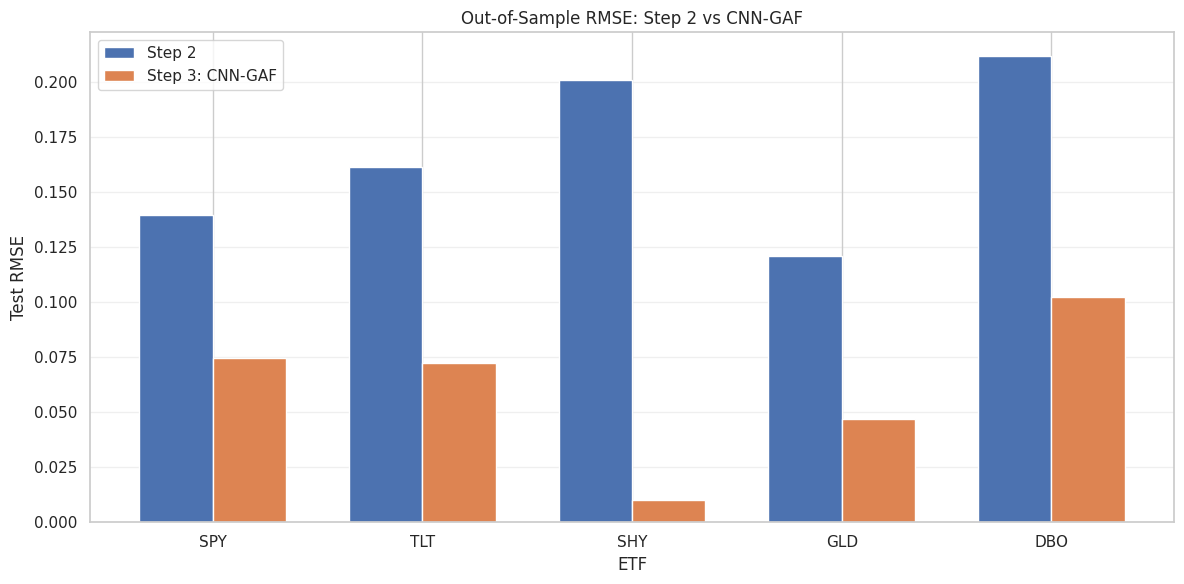

In [22]:
comparison_plot = model_comparison_df.copy()

x = np.arange(
    len(comparison_plot["ETF"])
)

width = 0.35


plt.figure(
    figsize=(12, 6)
)


plt.bar(

    x - width / 2,

    comparison_plot[
        "Step 2 Test RMSE"
    ],

    width,

    label="Step 2"

)


plt.bar(

    x + width / 2,

    comparison_plot[
        "CNN Test RMSE"
    ],

    width,

    label="CNN-GAF"

)


plt.xticks(
    x,
    comparison_plot["ETF"]
)


plt.xlabel(
    "ETF"
)

plt.ylabel(
    "Test RMSE"
)

plt.title(
    "Out-of-Sample RMSE: Step 2 vs CNN-GAF"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()


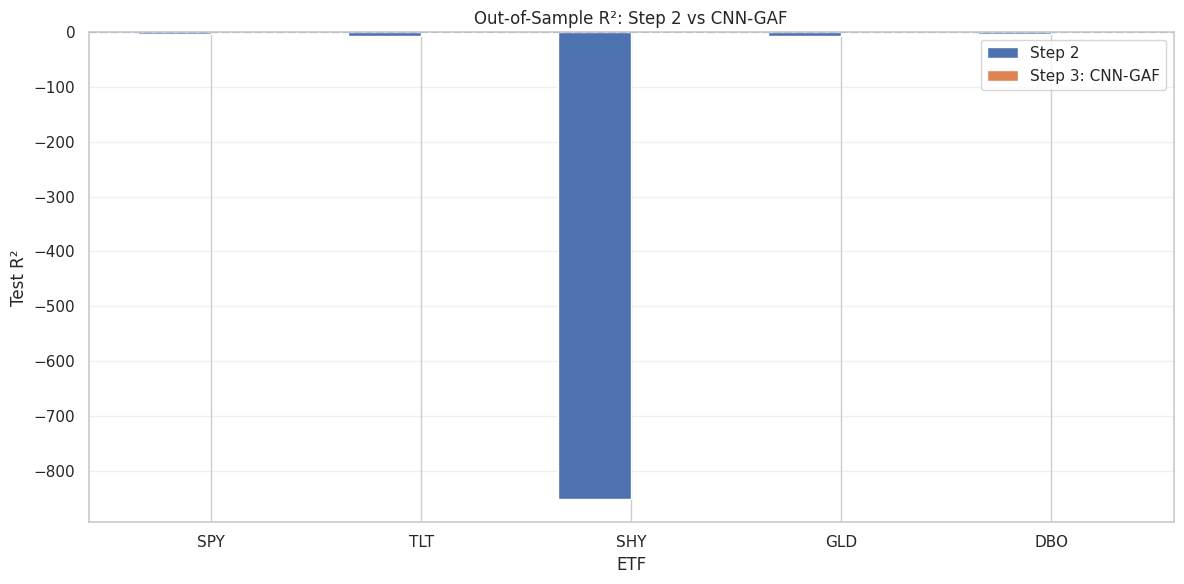

In [23]:
plt.figure(
    figsize=(12, 6)
)


plt.bar(

    x - width / 2,

    comparison_plot[
        "Step 2 Test R2"
    ],

    width,

    label="Step 2"

)


plt.bar(

    x + width / 2,

    comparison_plot[
        "CNN Test R2"
    ],

    width,

    label="CNN-GAF"

)


plt.axhline(
    y=0,
    linestyle="--"
)


plt.xticks(
    x,
    comparison_plot["ETF"]
)


plt.xlabel(
    "ETF"
)

plt.ylabel(
    "Test R²"
)

plt.title(
    "Out-of-Sample R²: Step 2 vs CNN-GAF"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()


In [ ]:
# LSTM MODELS USING HISTORICAL RETURNS

print("\n" + "=" * 60)
print("LSTM MODELS USING HISTORICAL RETURNS")
print("=" * 60)




## Prepare LSTM Datasets


In [24]:
lstm_data = {}


for symbol in symbols:

    print(f"\nPreparing LSTM data for {symbol}...")


    # Get sequences and targets created earlier

    X = sequence_data[symbol]["X"]

    y = sequence_data[symbol]["y"]


    # Chronological train/test split

    (
        X_train,
        X_test,
        y_train,
        y_test
    ) = chronological_split(
        X,
        y,
        test_size=TEST_SIZE
    )


    # Reshape for LSTM
    #
    # Original:
    # (samples, 25)
    #
    # LSTM:
    # (samples, 25, 1)

    X_train_lstm = X_train.reshape(
        X_train.shape[0],
        X_train.shape[1],
        1
    )


    X_test_lstm = X_test.reshape(
        X_test.shape[0],
        X_test.shape[1],
        1
    )


    # Store data

    lstm_data[symbol] = {

        "X_train": X_train_lstm,

        "X_test": X_test_lstm,

        "y_train": y_train,

        "y_test": y_test

    }


    # Display shapes

    print(
        f"Training shape: {X_train_lstm.shape}"
    )

    print(
        f"Testing shape: {X_test_lstm.shape}"
    )



STEP 4: LSTM MODELS USING HISTORICAL RETURNS

Preparing LSTM data for SPY...
Training shape: (967, 25, 1)
Testing shape: (242, 25, 1)

Preparing LSTM data for TLT...
Training shape: (967, 25, 1)
Testing shape: (242, 25, 1)

Preparing LSTM data for SHY...
Training shape: (967, 25, 1)
Testing shape: (242, 25, 1)

Preparing LSTM data for GLD...
Training shape: (967, 25, 1)
Testing shape: (242, 25, 1)

Preparing LSTM data for DBO...
Training shape: (967, 25, 1)
Testing shape: (242, 25, 1)


## Build LSTM Model


In [25]:
from tensorflow.keras.layers import LSTM


def build_lstm_model(input_shape):

    model = Sequential([

        # Input Layer

        Input(
            shape=input_shape
        ),

       # LSTM Layer

        LSTM(
            50,
            activation="tanh"
        ),

        # Dropout

        Dropout(
            0.20
        ),

        # Dense Hidden Layer

        Dense(
            32,
            activation="relu"
        ),

        # Output Layer

        Dense(
            1
        )

    ])


    # Compile Model

    model.compile(

        optimizer="adam",

        loss="mse"

    )


    return model


# VERIFY LSTM ARCHITECTURE

example_lstm_model = build_lstm_model(
    input_shape=(
        LOOKBACK,
        1
    )
)


print("\nLSTM Model Architecture")
print("=" * 60)

example_lstm_model.summary()



LSTM Model Architecture


Model: "sequential_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 32)             │         1,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,065 (47.13 KB)

 Trainable params: 12,065 (47.13 KB)

 Non-trainable params: 0 (0.00 B)

## TRAIN LSTM MODELS FOR ALL ETFs


In [26]:
lstm_results = []

lstm_predictions = {}

lstm_actual_values = {}

lstm_training_histories = {}

lstm_models = {}


for symbol in symbols:

    print("\n")
    print("=" * 60)
    print(
        f"Training LSTM model for "
        f"{symbol} - {etfs[symbol]}"
    )
    print("=" * 60)


    # Get LSTM data

    X_train = lstm_data[symbol]["X_train"]

    X_test = lstm_data[symbol]["X_test"]

    y_train = lstm_data[symbol]["y_train"]

    y_test = lstm_data[symbol]["y_test"]


    # Build LSTM model

    model = build_lstm_model(
        input_shape=X_train.shape[1:]
    )


    # Early stopping

    early_stopping = EarlyStopping(

        monitor="val_loss",

        patience=10,

        restore_best_weights=True

    )


    # Train model

    history = model.fit(

        X_train,

        y_train,

        validation_split=0.20,

        epochs=100,

        batch_size=32,

        callbacks=[
            early_stopping
        ],

        verbose=0,

        shuffle=False

    )


    # Generate predictions

    train_predictions = (
        model.predict(
            X_train,
            verbose=0
        )
        .flatten()
    )


    test_predictions = (
        model.predict(
            X_test,
            verbose=0
        )
        .flatten()
    )


    # Calculate performance metrics

    train_metrics = calculate_metrics(
        y_train,
        train_predictions
    )

    test_metrics = calculate_metrics(
        y_test,
        test_predictions
    )


    # Store results

    lstm_results.append({

        "ETF":
            symbol,

        "Asset Class":
            etfs[symbol],


        # Training / In-Sample

        "Training MSE":
            train_metrics["MSE"],

        "Training RMSE":
            train_metrics["RMSE"],

        "Training MAE":
            train_metrics["MAE"],

        "Training R2":
            train_metrics["R2"],


        # Testing / Out-of-Sample

        "Test MSE":
            test_metrics["MSE"],

        "Test RMSE":
            test_metrics["RMSE"],

        "Test MAE":
            test_metrics["MAE"],

        "Test R2":
            test_metrics["R2"]

    })


    # Store predictions and model information

    lstm_predictions[symbol] = test_predictions

    lstm_actual_values[symbol] = y_test

    lstm_training_histories[symbol] = history

    lstm_models[symbol] = model


    # Display key results

    print(f"\n{symbol} Results")

    print("-" * 40)

    print(
        f"Training RMSE: "
        f"{train_metrics['RMSE']:.6f}"
    )

    print(
        f"Training R²: "
        f"{train_metrics['R2']:.6f}"
    )

    print(
        f"Test RMSE: "
        f"{test_metrics['RMSE']:.6f}"
    )

    print(
        f"Test R²: "
        f"{test_metrics['R2']:.6f}"
    )




Training LSTM model for SPY - Equity

SPY Results
----------------------------------------
Training RMSE: 0.057508
Training R²: -0.037218
Test RMSE: 0.078972
Test R²: -0.454192


Training LSTM model for TLT - Fixed Income

TLT Results
----------------------------------------
Training RMSE: 0.040819
Training R²: 0.000414
Test RMSE: 0.070980
Test R²: -0.457057


Training LSTM model for SHY - Cash-like

SHY Results
----------------------------------------
Training RMSE: 0.004717
Training R²: -0.453440
Test RMSE: 0.007595
Test R²: -0.215605


Training LSTM model for GLD - Precious Metals (Gold)

GLD Results
----------------------------------------
Training RMSE: 0.040303
Training R²: -0.001108
Test RMSE: 0.045881
Test R²: -0.048563


Training LSTM model for DBO - Crude Oil

DBO Results
----------------------------------------
Training RMSE: 0.108823
Training R²: -0.000951
Test RMSE: 0.097868
Test R²: -0.003024


## LSTM Performance Results Table


In [27]:
lstm_results_df = pd.DataFrame(lstm_results)


# Create display version

lstm_results_display = lstm_results_df.copy()

numeric_columns = lstm_results_display.select_dtypes(
    include=[np.number]
).columns


lstm_results_display[numeric_columns] = (
    lstm_results_display[numeric_columns].round(6)
)


print("\n")
print("=" * 100)
print("LSTM - PERFORMANCE RESULTS")
print("=" * 100)

print(
    lstm_results_display.to_string(
        index=False
    )
)




STEP 4: LSTM - PERFORMANCE RESULTS
ETF            Asset Class  Training MSE  Training RMSE  Training MAE  Training R2  Test MSE  Test RMSE  Test MAE   Test R2
SPY                 Equity      0.003307       0.057508      0.035592    -0.037218  0.006237   0.078972  0.068063 -0.454192
TLT           Fixed Income      0.001666       0.040819      0.030990     0.000414  0.005038   0.070980  0.062042 -0.457057
SHY              Cash-like      0.000022       0.004717      0.003073    -0.453440  0.000058   0.007595  0.006612 -0.215605
GLD Precious Metals (Gold)      0.001624       0.040303      0.032023    -0.001108  0.002105   0.045881  0.037645 -0.048563
DBO              Crude Oil      0.011842       0.108823      0.083988    -0.000951  0.009578   0.097868  0.081544 -0.003024


## LSTM Out-Of-Sample Performance Summary


In [28]:
lstm_test_summary = lstm_results_df[[
    "ETF",
    "Asset Class",
    "Test MSE",
    "Test RMSE",
    "Test MAE",
    "Test R2"
]].copy()


lstm_test_summary = lstm_test_summary.sort_values(
    by="Test RMSE"
)


print("\n")
print("=" * 80)
print("LSTM OUT-OF-SAMPLE PERFORMANCE SUMMARY")
print("=" * 80)

print(
    lstm_test_summary.round(6).to_string(
        index=False
    )
)




LSTM OUT-OF-SAMPLE PERFORMANCE SUMMARY
ETF            Asset Class  Test MSE  Test RMSE  Test MAE   Test R2
SHY              Cash-like  0.000058   0.007595  0.006612 -0.215605
GLD Precious Metals (Gold)  0.002105   0.045881  0.037645 -0.048563
TLT           Fixed Income  0.005038   0.070980  0.062042 -0.457057
SPY                 Equity  0.006237   0.078972  0.068063 -0.454192
DBO              Crude Oil  0.009578   0.097868  0.081544 -0.003024


## LSTM: Actual Vs Predicted Returns


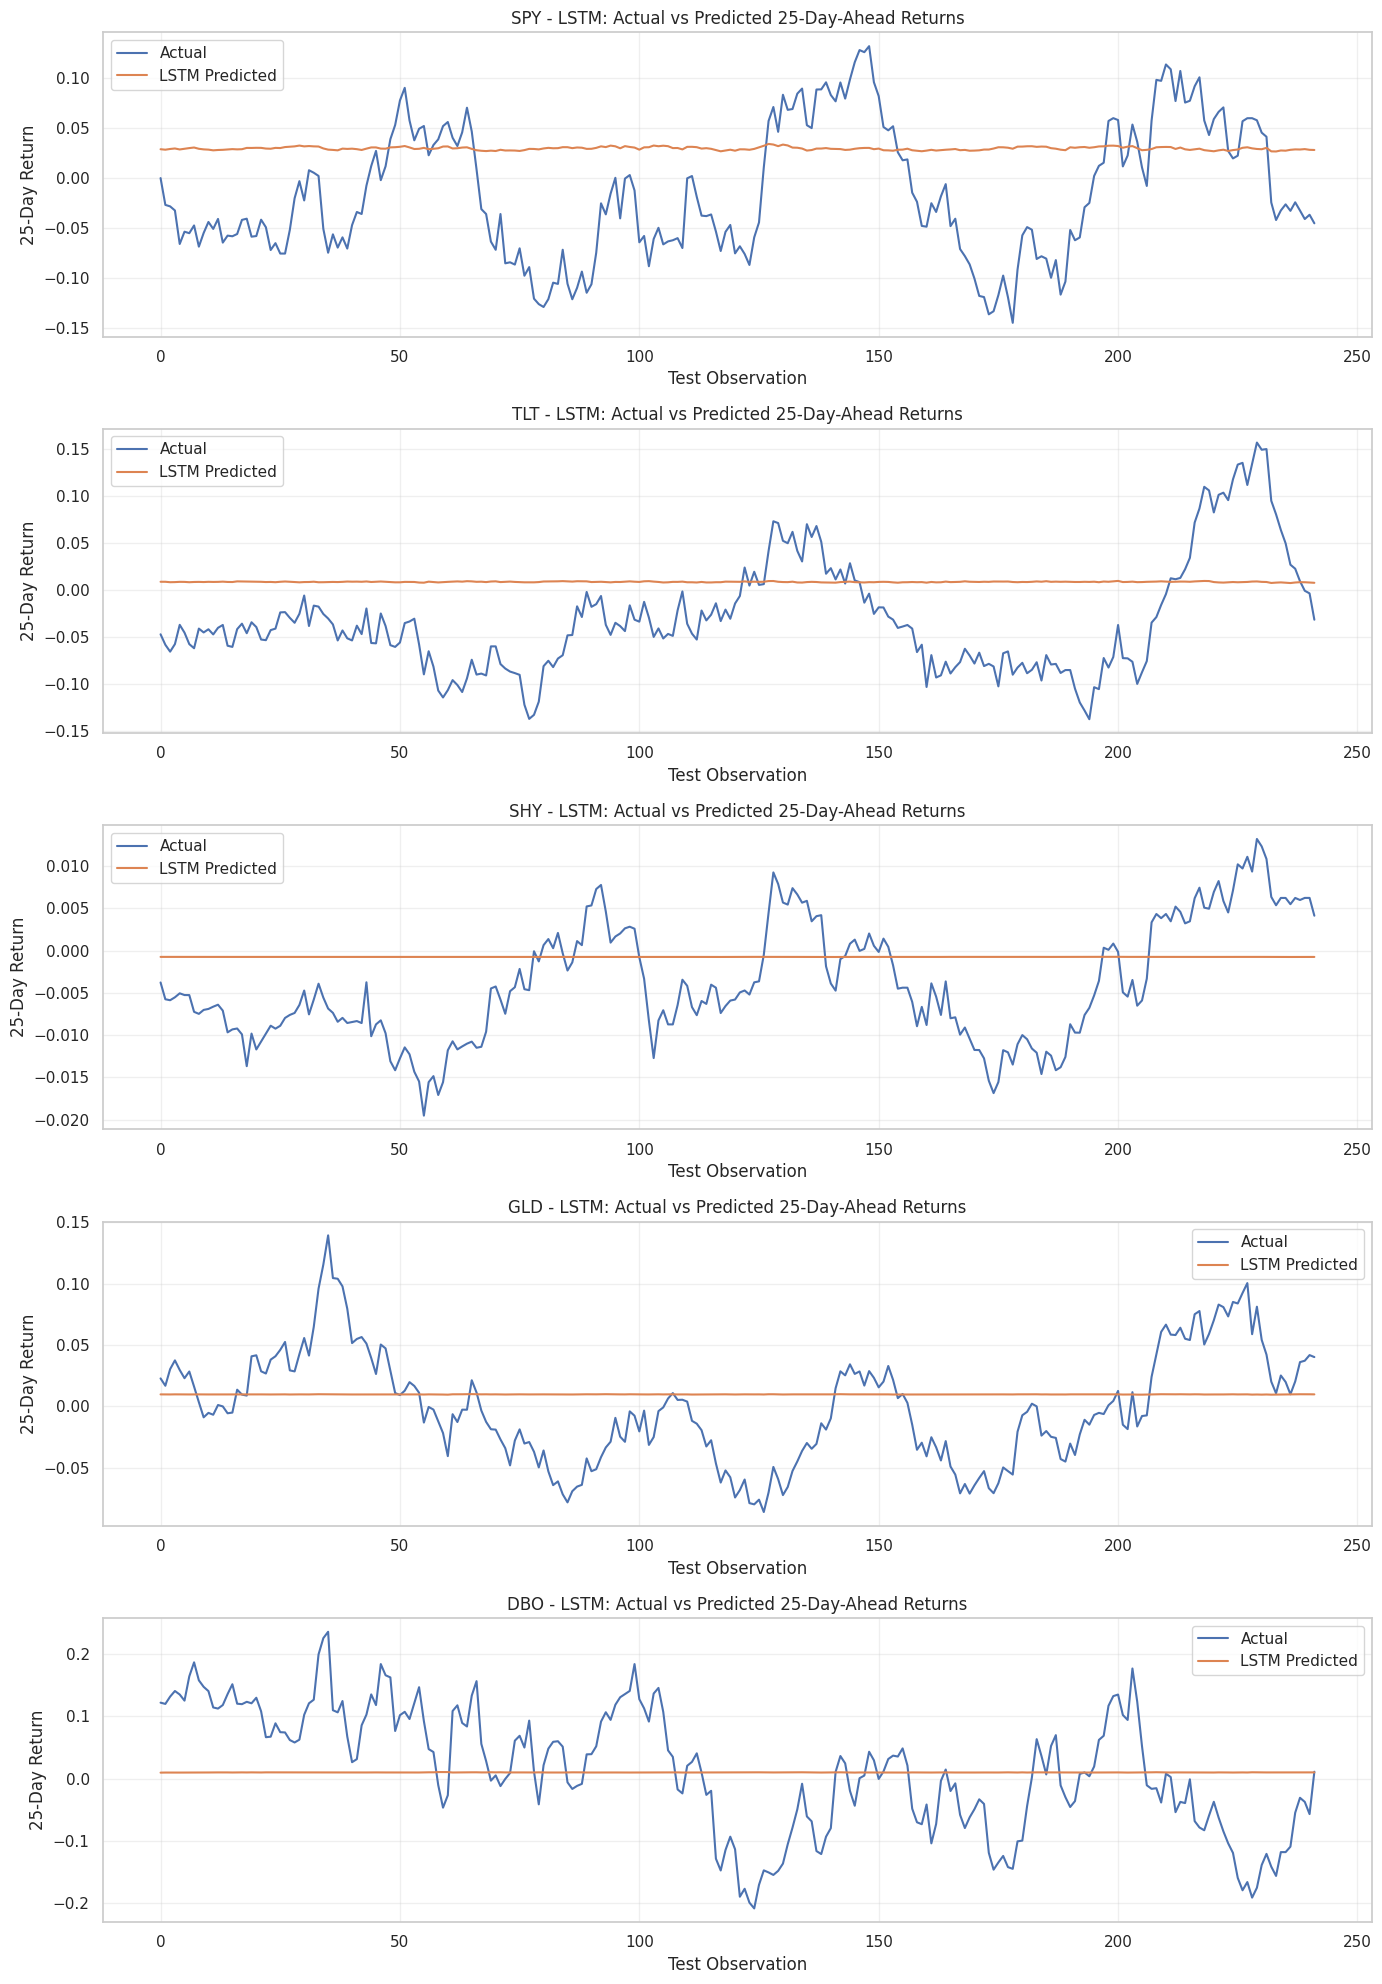

In [29]:
fig, axes = plt.subplots(
    nrows=5,
    ncols=1,
    figsize=(14, 20)
)

for i, symbol in enumerate(symbols):

    actual = lstm_actual_values[symbol]

    predicted = lstm_predictions[symbol]

    axes[i].plot(
        actual,
        label="Actual"
    )

    axes[i].plot(
        predicted,
        label="LSTM Predicted"
    )

    axes[i].set_title(
        f"{symbol} - LSTM: "
        f"Actual vs Predicted 25-Day-Ahead Returns"
    )

    axes[i].set_xlabel(
        "Test Observation"
    )

    axes[i].set_ylabel(
        "25-Day Return"
    )

    axes[i].legend()

    axes[i].grid(
        True,
        alpha=0.3
    )


plt.tight_layout()

plt.show()


## LSTM Training And Validation Loss


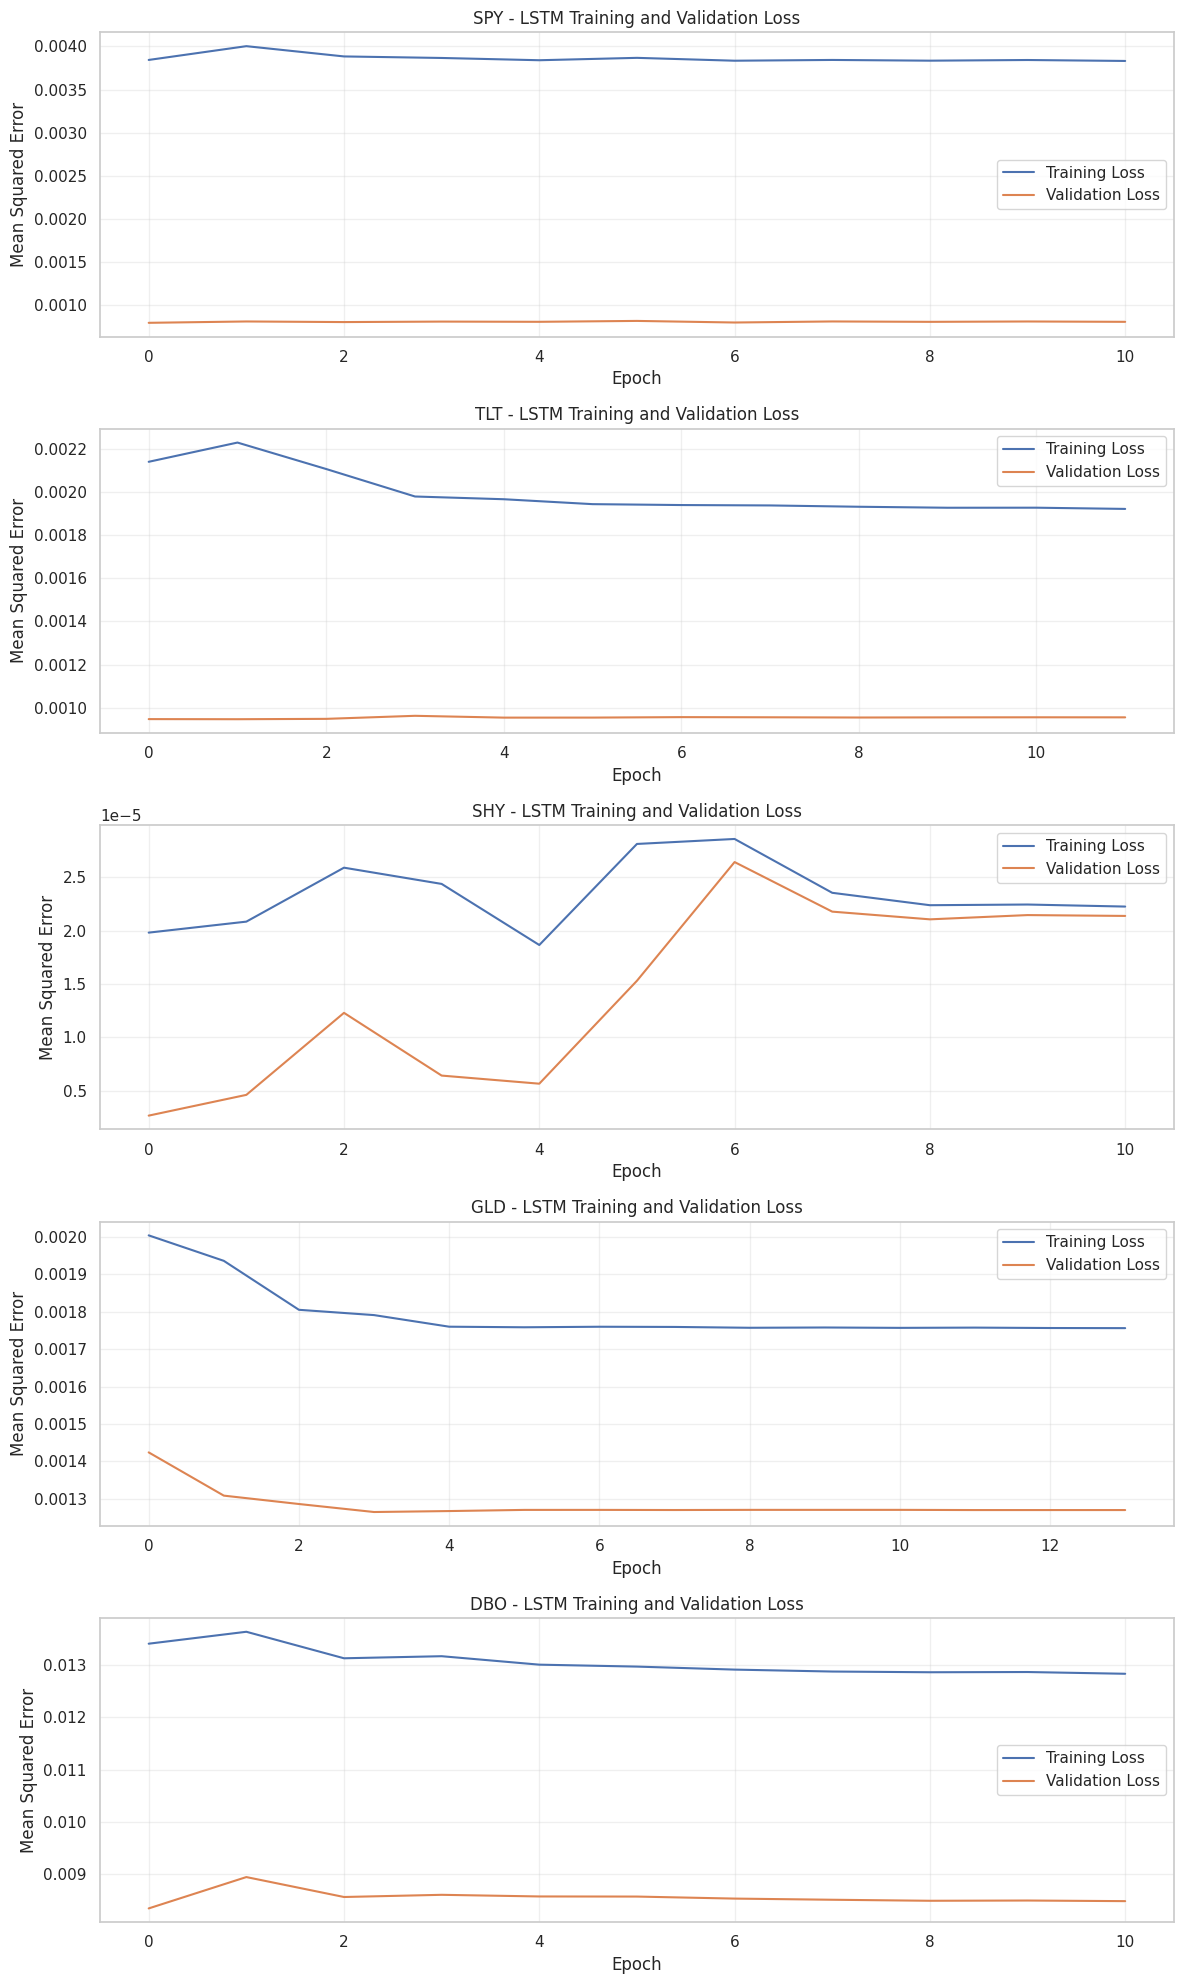

In [30]:
fig, axes = plt.subplots(
    nrows=5,
    ncols=1,
    figsize=(12, 20)
)

for i, symbol in enumerate(symbols):

    history = lstm_training_histories[symbol]

    axes[i].plot(
        history.history["loss"],
        label="Training Loss"
    )

    axes[i].plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    axes[i].set_title(
        f"{symbol} - LSTM Training and Validation Loss"
    )

    axes[i].set_xlabel(
        "Epoch"
    )

    axes[i].set_ylabel(
        "Mean Squared Error"
    )

    axes[i].legend()

    axes[i].grid(
        True,
        alpha=0.3
    )


plt.tight_layout()

plt.show()


## LSTM Training Epoch Summary


In [31]:
lstm_epoch_summary = []


for symbol in symbols:

    history = lstm_training_histories[symbol]

    epochs_trained = len(
        history.history["loss"]
    )

    best_epoch = (
        np.argmin(
            history.history["val_loss"]
        )
        + 1
    )


    lstm_epoch_summary.append({

        "ETF": symbol,

        "Epochs Trained":
            epochs_trained,

        "Best Validation Epoch":
            best_epoch,

        "Best Validation Loss":
            np.min(
                history.history["val_loss"]
            )

    })


lstm_epoch_summary_df = pd.DataFrame(
    lstm_epoch_summary
)


print("\n")
print("=" * 70)
print("LSTM TRAINING SUMMARY")
print("=" * 70)

print(
    lstm_epoch_summary_df.round(6).to_string(
        index=False
    )
)




LSTM TRAINING SUMMARY
ETF  Epochs Trained  Best Validation Epoch  Best Validation Loss
SPY              11                      1              0.000796
TLT              12                      2              0.000946
SHY              11                      1              0.000003
GLD              14                      4              0.001265
DBO              11                      1              0.008348


## CNN and LSTM Performance Comparison


In [32]:
# Select test performance metrics

step2_final = step2_results_df[[
    "ETF",
    "Test MSE",
    "Test RMSE",
    "Test MAE",
    "Test R2"
]].copy()


step2_final.columns = [

    "ETF",

    "Step 2 Test MSE",
    "Step 2 Test RMSE",
    "Step 2 Test MAE",
    "Step 2 Test R2"

]


# CNN-GAF metrics

cnn_final = cnn_results_df[[
    "ETF",
    "Test MSE",
    "Test RMSE",
    "Test MAE",
    "Test R2"
]].copy()


cnn_final.columns = [

    "ETF",

    "CNN Test MSE",
    "CNN Test RMSE",
    "CNN Test MAE",
    "CNN Test R2"

]


# LSTM metrics

lstm_final = lstm_results_df[[
    "ETF",
    "Test MSE",
    "Test RMSE",
    "Test MAE",
    "Test R2"
]].copy()


lstm_final.columns = [

    "ETF",

    "LSTM Test MSE",
    "LSTM Test RMSE",
    "LSTM Test MAE",
    "LSTM Test R2"

]


# Merge all three models

final_model_comparison = step2_final.merge(

    cnn_final,

    on="ETF"

).merge(

    lstm_final,

    on="ETF"

)


# Identify best model based on lowest Test RMSE

final_model_comparison["Best Model (RMSE)"] = (

    final_model_comparison[[
        "Step 2 Test RMSE",
        "CNN Test RMSE",
        "LSTM Test RMSE"
    ]]

    .idxmin(axis=1)

    .replace({

        "Step 2 Test RMSE": "Step 2",

        "CNN Test RMSE": "CNN-GAF",

        "LSTM Test RMSE": "LSTM"

    })

)


# Display results

print("\n")
print("=" * 160)

print(
    "FINAL OUT-OF-SAMPLE PERFORMANCE COMPARISON"
)

print(
    "STEP 2 vs CNN-GAF vs LSTM"
)

print("=" * 160)


print(

    final_model_comparison.round(6).to_string(
        index=False
    )

)




FINAL OUT-OF-SAMPLE PERFORMANCE COMPARISON
STEP 2 vs CNN-GAF vs LSTM
ETF  Step 2 Test MSE  Step 2 Test RMSE  Step 2 Test MAE  Step 2 Test R2  CNN Test MSE  CNN Test RMSE  CNN Test MAE  CNN Test R2  LSTM Test MSE  LSTM Test RMSE  LSTM Test MAE  LSTM Test R2 Best Model (RMSE)
SPY         0.019494          0.139620         0.112887       -3.545448      0.005551       0.074502      0.064533    -0.294247       0.006237        0.078972       0.068063     -0.454192           CNN-GAF
TLT         0.026006          0.161264         0.128803       -6.521020      0.005240       0.072388      0.063509    -0.515426       0.005038        0.070980       0.062042     -0.457057              LSTM
SHY         0.040468          0.201167         0.152657     -851.719258      0.000106       0.010282      0.008770    -1.227647       0.000058        0.007595       0.006612     -0.215605              LSTM
GLD         0.014667          0.121108         0.096314       -6.306070      0.002202       0.046923     

## Final Model Comparison Summary


In [33]:
final_summary = final_model_comparison[[
    "ETF",

    "Step 2 Test RMSE",
    "CNN Test RMSE",
    "LSTM Test RMSE",

    "Step 2 Test R2",
    "CNN Test R2",
    "LSTM Test R2",

    "Best Model (RMSE)"
]].copy()


print("\n")
print("=" * 120)
print("FINAL MODEL COMPARISON SUMMARY")
print("=" * 120)

print(
    final_summary.round(6).to_string(
        index=False
    )
)




FINAL MODEL COMPARISON SUMMARY
ETF  Step 2 Test RMSE  CNN Test RMSE  LSTM Test RMSE  Step 2 Test R2  CNN Test R2  LSTM Test R2 Best Model (RMSE)
SPY          0.139620       0.074502        0.078972       -3.545448    -0.294247     -0.454192           CNN-GAF
TLT          0.161264       0.072388        0.070980       -6.521020    -0.515426     -0.457057              LSTM
SHY          0.201167       0.010282        0.007595     -851.719258    -1.227647     -0.215605              LSTM
GLD          0.121108       0.046923        0.045881       -6.306070    -0.096777     -0.048563              LSTM
DBO          0.212010       0.102480        0.097868       -3.706983    -0.099791     -0.003024              LSTM


## Final Test Rmse Comparison


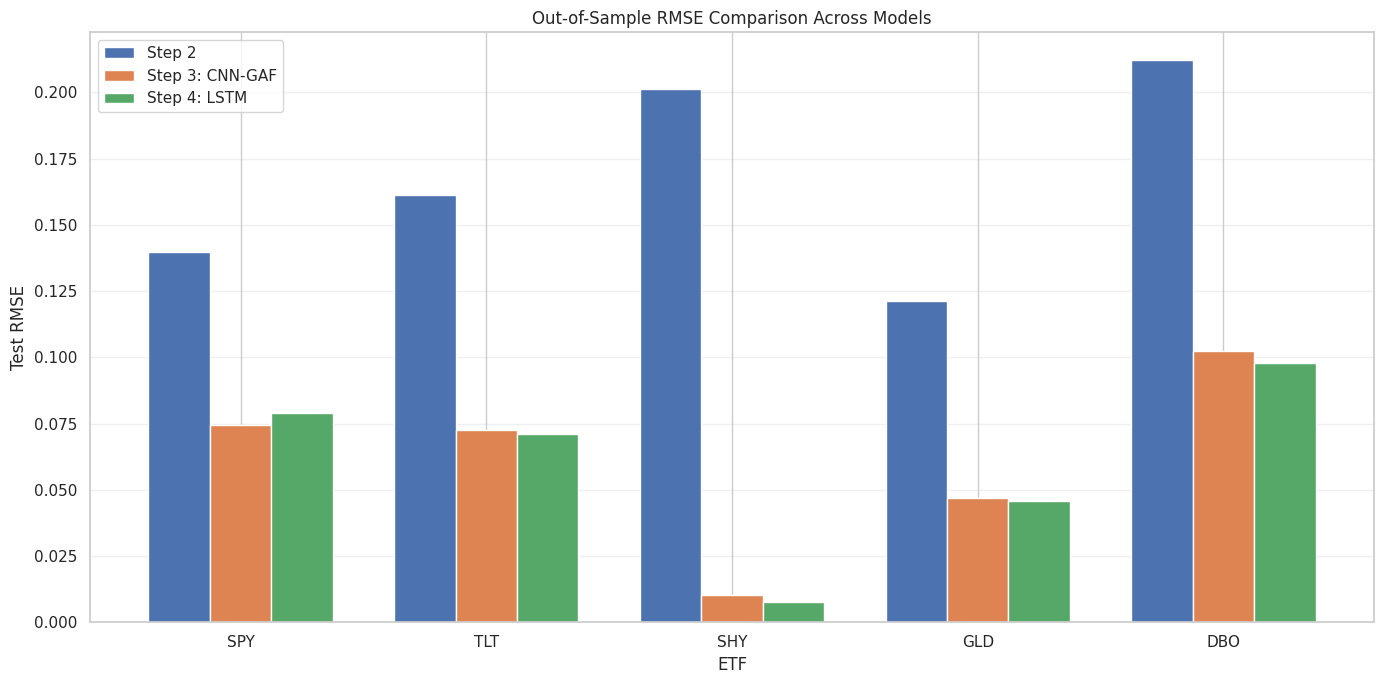

In [34]:
x = np.arange(
    len(final_summary["ETF"])
)

width = 0.25


plt.figure(
    figsize=(14, 7)
)


plt.bar(

    x - width,

    final_summary[
        "Step 2 Test RMSE"
    ],

    width,

    label="Step 2"

)


plt.bar(

    x,

    final_summary[
        "CNN Test RMSE"
    ],

    width,

    label="CNN-GAF"

)


plt.bar(

    x + width,

    final_summary[
        "LSTM Test RMSE"
    ],

    width,

    label="LSTM"

)


plt.xticks(
    x,
    final_summary["ETF"]
)


plt.xlabel("ETF")

plt.ylabel("Test RMSE")

plt.title(
    "Out-of-Sample RMSE Comparison Across Models"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()


## CNN-GAF Vs LSTM: Test R² Comparison


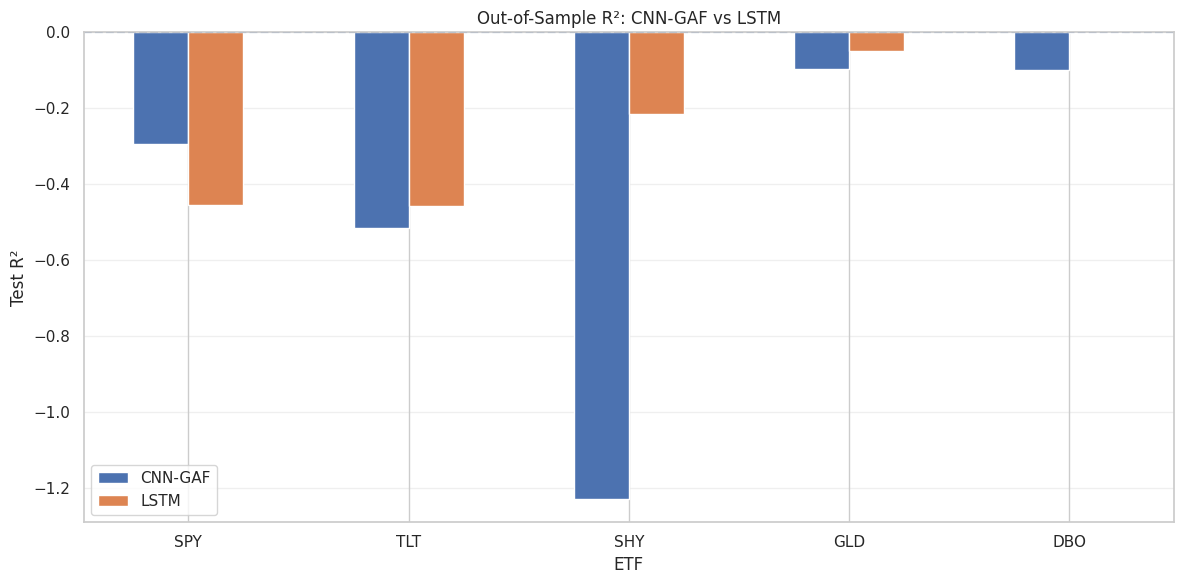

In [35]:
plt.figure(
    figsize=(12, 6)
)


plt.bar(

    x - width / 2,

    final_summary[
        "CNN Test R2"
    ],

    width,

    label="CNN-GAF"

)


plt.bar(

    x + width / 2,

    final_summary[
        "LSTM Test R2"
    ],

    width,

    label="LSTM"

)


plt.axhline(
    y=0,
    linestyle="--"
)


plt.xticks(
    x,
    final_summary["ETF"]
)


plt.xlabel("ETF")

plt.ylabel("Test R²")

plt.title(
    "Out-of-Sample R²: CNN-GAF vs LSTM"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()


## Multi-Output Return Prediction


In [ ]:
# MULTI-OUTPUT PREDICTION

print("\n" + "=" * 60)
print("MULTI-OUTPUT PREDICTION")
print("=" * 60)


## Independent Asset Forecasting


In [ ]:
# past returns as inputs.
#


## Joint Multi-Asset Forecasting


In [ ]:
# 25 daily returns of ALL FIVE ETFs at once, and produces FIVE
# outputs at once: the 25-day-ahead return of every ETF.
#
# This allows the network to learn relationships across asset
# classes (for example, equity and bonds, or gold and equity)
# rather than treating each asset in isolation.


print(
    "Input window: Previous 25 daily returns of all 5 ETFs"
)

print(
    "Prediction target: 25-day-ahead compounded return "
    "for all 5 ETFs simultaneously"
)


## Create Multi-Asset Supervised Data


In [ ]:
def create_multi_asset_sequences(
    returns_df,
    asset_symbols,
    lookback=25,
    horizon=25
):

    X = []
    y = []

    values = (
        returns_df[asset_symbols]
        .values
    )


    for i in range(
        len(values)
        - lookback
        - horizon
        + 1
    ):

        # Past information available at time t, for all assets
        past_returns = (
            values[
                i:
                i + lookback,
                :
            ]
        )


        # Future 25 daily returns, for all assets
        future_returns = (
            values[
                i + lookback:
                i + lookback + horizon,
                :
            ]
        )


        # Compound future returns per asset
        future_25_day_return = (
            np.prod(
                1 + future_returns,
                axis=0
            )
            - 1
        )


        X.append(
            past_returns
        )

        y.append(
            future_25_day_return
        )


    return (
        np.array(X),
        np.array(y)
    )


## Build The Joint Multi-Asset Dataset


In [ ]:
X_multi, y_multi = create_multi_asset_sequences(
    returns,
    symbols,
    lookback=LOOKBACK,
    horizon=FORECAST_HORIZON
)


print(
    "\nMulti-Asset Sequence Verification"
)
print("=" * 60)

print(
    "Joint input shape (samples, lookback, assets):",
    X_multi.shape
)

print(
    "Joint target shape (samples, assets):",
    y_multi.shape
)


# This must match the number of samples produced for each
# individual ETF in Step 2, since the same LOOKBACK, the same
# FORECAST_HORIZON, and the same underlying returns are used.

assert (
    X_multi.shape[0]
    ==
    sequence_data[symbols[0]]["X"].shape[0]
), "Multi-asset sample count does not match Step 2 sequences."


## Chronological Train/Test Split


In [ ]:
(
    X_train_multi,
    X_test_multi,
    y_train_multi,
    y_test_multi
) = chronological_split(
    X_multi,
    y_multi,
    test_size=TEST_SIZE
)


print(
    f"\nTraining observations = "
    f"{len(X_train_multi)}, "
    f"Testing observations = "
    f"{len(X_test_multi)}"
)


## Build Multi-Output LSTM Model


In [ ]:
from tensorflow.keras.models import Model


def build_multi_output_model(input_shape, n_assets):

    inputs = Input(
        shape=input_shape
    )

    # LSTM Layers

    x = LSTM(
        64,
        activation="tanh",
        return_sequences=True
    )(inputs)

    x = LSTM(
        32,
        activation="tanh"
    )(x)

    # Dropout

    x = Dropout(
        0.20
    )(x)

    # Dense Hidden Layer

    x = Dense(
        32,
        activation="relu"
    )(x)

    # Output Layer - one unit per asset

    outputs = Dense(
        n_assets
    )(x)


    model = Model(
        inputs,
        outputs
    )


    # Compile Model

    model.compile(

        optimizer="adam",

        loss="mse"

    )


    return model


# VERIFY MULTI-OUTPUT ARCHITECTURE

example_multi_output_model = build_multi_output_model(
    input_shape=(
        LOOKBACK,
        len(symbols)
    ),
    n_assets=len(symbols)
)


print("\nMulti-Output Model Architecture")
print("=" * 60)

example_multi_output_model.summary()


## Train The Multi-Output Model


In [ ]:
print("\n")
print("=" * 60)
print("Training multi-output model on all 5 ETFs jointly")
print("=" * 60)


multi_output_model = build_multi_output_model(
    input_shape=X_train_multi.shape[1:],
    n_assets=len(symbols)
)


early_stopping = EarlyStopping(

    monitor="val_loss",

    patience=10,

    restore_best_weights=True

)


multi_output_history = multi_output_model.fit(

    X_train_multi,

    y_train_multi,

    validation_split=0.20,

    epochs=100,

    batch_size=32,

    callbacks=[
        early_stopping
    ],

    verbose=0,

    shuffle=False

)


# Generate predictions

multi_output_train_predictions = (
    multi_output_model
    .predict(
        X_train_multi,
        verbose=0
    )
)


multi_output_test_predictions = (
    multi_output_model
    .predict(
        X_test_multi,
        verbose=0
    )
)


## Multi-Output Performance Results Table


In [ ]:
multi_output_results = []

multi_output_predictions = {}

multi_output_actual_values = {}


for i, symbol in enumerate(symbols):

    train_metrics = calculate_metrics(
        y_train_multi[:, i],
        multi_output_train_predictions[:, i]
    )


    test_metrics = calculate_metrics(
        y_test_multi[:, i],
        multi_output_test_predictions[:, i]
    )


    multi_output_results.append({

        "ETF":
            symbol,

        "Asset Class":
            etfs[symbol],


        # Training / In-Sample

        "Training MSE":
            train_metrics["MSE"],

        "Training RMSE":
            train_metrics["RMSE"],

        "Training MAE":
            train_metrics["MAE"],

        "Training R2":
            train_metrics["R2"],


        # Testing / Out-of-Sample

        "Test MSE":
            test_metrics["MSE"],

        "Test RMSE":
            test_metrics["RMSE"],

        "Test MAE":
            test_metrics["MAE"],

        "Test R2":
            test_metrics["R2"]

    })


    multi_output_predictions[symbol] = (
        multi_output_test_predictions[:, i]
    )

    multi_output_actual_values[symbol] = (
        y_test_multi[:, i]
    )


    print(
        f"\n{symbol} Results"
    )

    print("-" * 40)

    print(
        f"Training RMSE: "
        f"{train_metrics['RMSE']:.6f}"
    )

    print(
        f"Training R²: "
        f"{train_metrics['R2']:.6f}"
    )

    print(
        f"Test RMSE: "
        f"{test_metrics['RMSE']:.6f}"
    )

    print(
        f"Test R²: "
        f"{test_metrics['R2']:.6f}"
    )


multi_output_results_df = pd.DataFrame(
    multi_output_results
)


multi_output_display = (
    multi_output_results_df.copy()
)

numeric_columns = multi_output_display.select_dtypes(
    include=[np.number]
).columns

multi_output_display[numeric_columns] = (
    multi_output_display[numeric_columns].round(6)
)


print("\n")
print("=" * 100)
print("MULTI-OUTPUT MODEL - PERFORMANCE RESULTS")
print("=" * 100)

print(
    multi_output_display.to_string(
        index=False
    )
)


## Single-Asset and Multi-Output LSTM Comparison


In [ ]:
# Select Step 4 performance metrics

step4_comparison = lstm_results_df[[
    "ETF",
    "Test MSE",
    "Test RMSE",
    "Test MAE",
    "Test R2"
]].copy()


step4_comparison.columns = [

    "ETF",

    "Step 4 Test MSE",
    "Step 4 Test RMSE",
    "Step 4 Test MAE",
    "Step 4 Test R2"

]


# Select Step 5 performance metrics

step5_comparison = multi_output_results_df[[
    "ETF",
    "Test MSE",
    "Test RMSE",
    "Test MAE",
    "Test R2"
]].copy()


step5_comparison.columns = [

    "ETF",

    "Step 5 Test MSE",
    "Step 5 Test RMSE",
    "Step 5 Test MAE",
    "Step 5 Test R2"

]


# Merge results

step4_vs_step5_comparison = pd.merge(

    step4_comparison,

    step5_comparison,

    on="ETF"

)


# Calculate change in test performance

step4_vs_step5_comparison[
    "MSE % Change"
] = (

    100
    *
    (
        step4_vs_step5_comparison[
            "Step 5 Test MSE"
        ]
        -
        step4_vs_step5_comparison[
            "Step 4 Test MSE"
        ]
    )
    /
    step4_vs_step5_comparison[
        "Step 4 Test MSE"
    ]

)


step4_vs_step5_comparison[
    "R2 Change"
] = (

    step4_vs_step5_comparison[
        "Step 5 Test R2"
    ]
    -
    step4_vs_step5_comparison[
        "Step 4 Test R2"
    ]

)


print("\n")
print("=" * 120)
print("STEP 4 (SINGLE-OUTPUT LSTM) VS STEP 5 (MULTI-OUTPUT LSTM)")
print("=" * 120)

print(
    step4_vs_step5_comparison.round(6).to_string(
        index=False
    )
)


## Single-Asset and Multi-Output Test RMSE


In [ ]:
x = np.arange(
    len(step4_vs_step5_comparison["ETF"])
)

width = 0.35


plt.figure(
    figsize=(12, 6)
)


plt.bar(

    x - width / 2,

    step4_vs_step5_comparison[
        "Step 4 Test RMSE"
    ],

    width,

    label="Single-Output LSTM"

)


plt.bar(

    x + width / 2,

    step4_vs_step5_comparison[
        "Step 5 Test RMSE"
    ],

    width,

    label="Multi-Output LSTM"

)


plt.xticks(
    x,
    step4_vs_step5_comparison["ETF"]
)


plt.xlabel(
    "ETF"
)

plt.ylabel(
    "Test RMSE"
)

plt.title(
    "Out-of-Sample RMSE: Single-Output vs Multi-Output LSTM"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()


In [ ]:
plt.figure(
    figsize=(12, 6)
)


plt.bar(

    x - width / 2,

    step4_vs_step5_comparison[
        "Step 4 Test R2"
    ],

    width,

    label="Single-Output LSTM"

)


plt.bar(

    x + width / 2,

    step4_vs_step5_comparison[
        "Step 5 Test R2"
    ],

    width,

    label="Multi-Output LSTM"

)


plt.axhline(
    y=0,
    linestyle="--"
)


plt.xticks(
    x,
    step4_vs_step5_comparison["ETF"]
)


plt.xlabel(
    "ETF"
)

plt.ylabel(
    "Test R²"
)

plt.title(
    "Out-of-Sample R²: Single-Output vs Multi-Output LSTM"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()

plt.show()


## Identify Improved And Deteriorated Assets


In [ ]:
# An asset is classified as IMPROVED if the multi-output test
# MSE is more than 2% lower than the single-output test MSE,
# and DETERIORATED if it is more than 2% higher. This keeps the
# classification grounded in the numbers actually produced by
# this run, rather than assumed in advance.


improved_assets = (
    step4_vs_step5_comparison[
        step4_vs_step5_comparison["MSE % Change"] < -2
    ]["ETF"]
    .tolist()
)


deteriorated_assets = (
    step4_vs_step5_comparison[
        step4_vs_step5_comparison["MSE % Change"] > 2
    ]["ETF"]
    .tolist()
)


unchanged_assets = [

    symbol
    for symbol in symbols

    if symbol not in improved_assets
    and symbol not in deteriorated_assets

]


average_step4_mse = (
    step4_vs_step5_comparison[
        "Step 4 Test MSE"
    ].mean()
)


average_step5_mse = (
    step4_vs_step5_comparison[
        "Step 5 Test MSE"
    ].mean()
)


print("\n")
print("=" * 70)
print("KEY NUMERICAL FINDINGS")
print("=" * 70)


print(
    f"Assets improved under multi-output (MSE fell > 2%): "
    f"{improved_assets if improved_assets else 'none'}"
)


print(
    f"Assets deteriorated under multi-output (MSE rose > 2%): "
    f"{deteriorated_assets if deteriorated_assets else 'none'}"
)


print(
    f"Assets essentially unchanged: "
    f"{unchanged_assets if unchanged_assets else 'none'}"
)


print(
    f"\nAverage out-of-sample MSE across all 5 assets: "
    f"{average_step4_mse:.6f} (Step 4) -> "
    f"{average_step5_mse:.6f} (Step 5)"
)


## Cross-Asset Discussion



STEP 5: MULTI-OUTPUT PREDICTION
Input window: Previous 25 daily returns of all 5 ETFs
Prediction target: 25-day-ahead compounded return for all 5 ETFs simultaneously

Multi-Asset Sequence Verification
Joint input shape (samples, lookback, assets): (1209, 25, 5)
Joint target shape (samples, assets): (1209, 5)

Training observations = 967, Testing observations = 242

Multi-Output Model Architecture


Model: "functional_22"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_22 (InputLayer)     │ (None, 25, 5)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_6 (LSTM)                   │ (None, 25, 64)         │        17,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_60 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_61 (Dense)                │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,557 (123.27 KB)

 Trainable params: 31,557 (123.27 KB)

 Non-trainable params: 0 (0.00 B)



Training multi-output model on all 5 ETFs jointly

SPY Results
----------------------------------------
Training RMSE: 0.056490
Training R²: -0.000840
Test RMSE: 0.073460
Test R²: -0.258304

TLT Results
----------------------------------------
Training RMSE: 0.040917
Training R²: -0.004389
Test RMSE: 0.071868
Test R²: -0.493734

SHY Results
----------------------------------------
Training RMSE: 0.004663
Training R²: -0.420254
Test RMSE: 0.010877
Test R²: -1.492980

GLD Results
----------------------------------------
Training RMSE: 0.040345
Training R²: -0.003211
Test RMSE: 0.046074
Test R²: -0.057409

DBO Results
----------------------------------------
Training RMSE: 0.108834
Training R²: -0.001160
Test RMSE: 0.097860
Test R²: -0.002860


STEP 5: MULTI-OUTPUT MODEL - PERFORMANCE RESULTS
ETF            Asset Class  Training MSE  Training RMSE  Training MAE  Training R2  Test MSE  Test RMSE  Test MAE   Test R2
SPY                 Equity      0.003191       0.056490      0.036083    

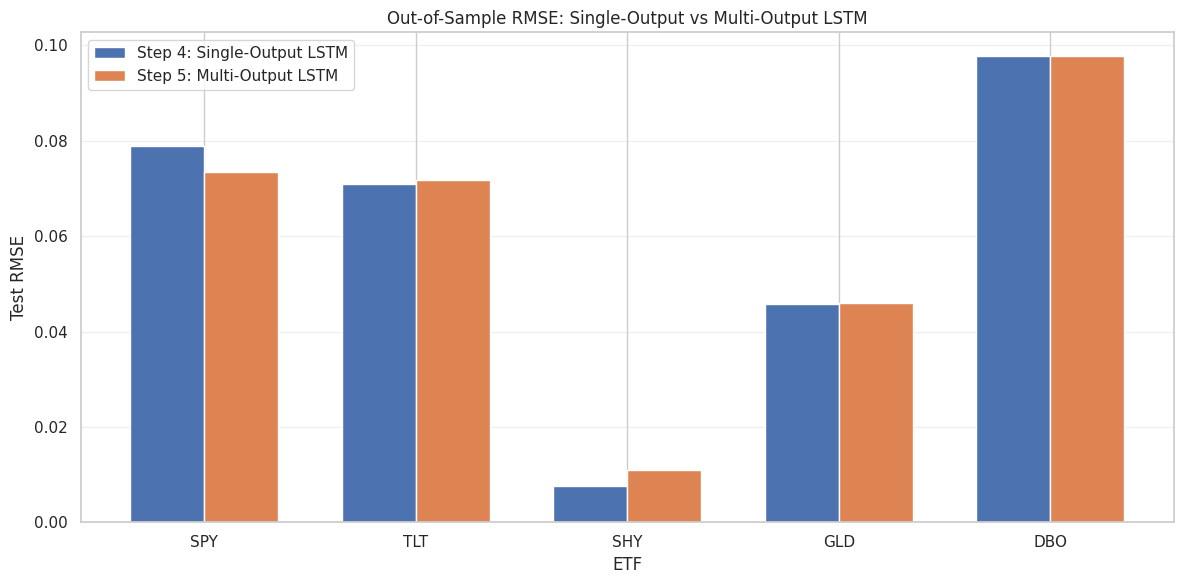

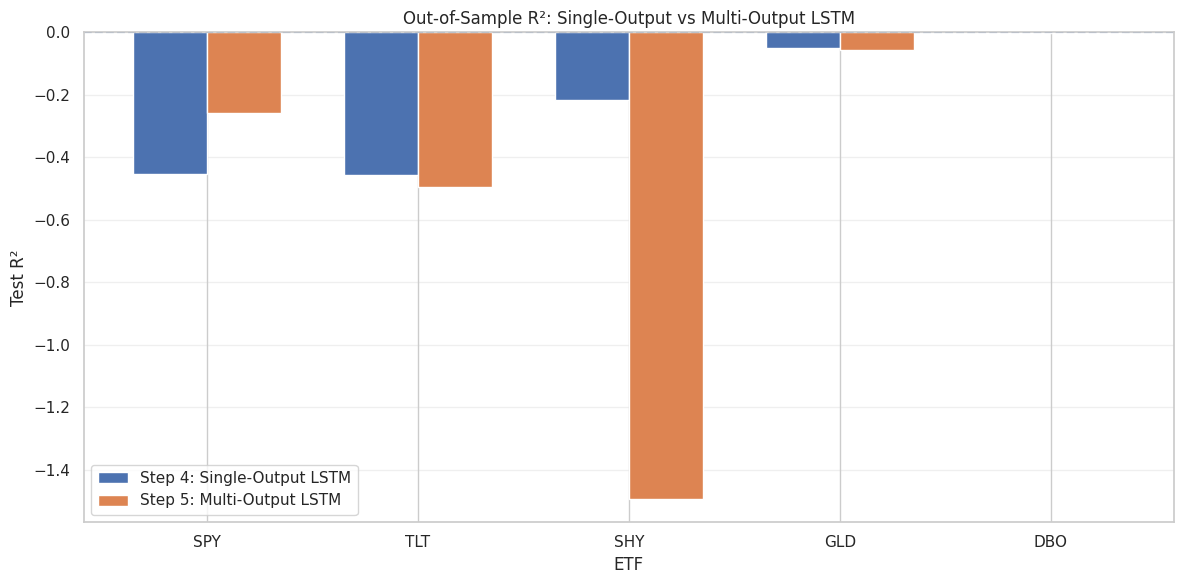



STEP 5: KEY NUMERICAL FINDINGS
Assets improved under multi-output (MSE fell > 2%): ['SPY']
Assets deteriorated under multi-output (MSE rose > 2%): ['TLT', 'SHY']
Assets essentially unchanged: ['GLD', 'DBO']

Average out-of-sample MSE across all 5 assets: 0.004603 (Step 4) -> 0.004476 (Step 5)


STEP 5: CROSS-ASSET DISCUSSION

The multi-output model shares a single LSTM trunk across all five ETFs, so an asset can only improve if information from the other four assets genuinely helps explain its 25-day-ahead return.

SPY (Equity): improved (MSE change = -13.5%). This is consistent with SPY's 25-day-ahead return being partly explained by information in the other four assets' recent returns that its own single-output LSTM in Step 4 could not see.

TLT (Fixed Income): deteriorated (MSE change = 2.5%). This suggests TLT's own-series signal in Step 4 was diluted by sharing one network with four other, less related targets - a form of negative transfer.

SHY (Cash-like): deteriorated (MSE ch

In [36]:
print("\n")
print("=" * 70)
print("CROSS-ASSET DISCUSSION")
print("=" * 70)


print(
    "\nThe multi-output model shares a single LSTM trunk across "
    "all five ETFs, so an asset can only improve if information "
    "from the other four assets genuinely helps explain its "
    "25-day-ahead return."
)


for symbol in symbols:

    row = (
        step4_vs_step5_comparison
        .loc[
            step4_vs_step5_comparison["ETF"] == symbol
        ]
        .iloc[0]
    )


    if symbol in improved_assets:

        print(
            f"\n{symbol} ({etfs[symbol]}): improved "
            f"(MSE change = {row['MSE % Change']:.1f}%). "
            f"This is consistent with {symbol}'s 25-day-ahead "
            f"return being partly explained by information in "
            f"the other four assets' recent returns that its own "
            f"single-output LSTM in Step 4 could not see."
        )

    elif symbol in deteriorated_assets:

        print(
            f"\n{symbol} ({etfs[symbol]}): deteriorated "
            f"(MSE change = {row['MSE % Change']:.1f}%). "
            f"This suggests {symbol}'s own-series signal in "
            f"Step 4 was diluted by sharing one network with "
            f"four other, less related targets - a form of "
            f"negative transfer."
        )

    else:

        print(
            f"\n{symbol} ({etfs[symbol]}): essentially unchanged "
            f"(MSE change = {row['MSE % Change']:.1f}%). "
            f"Cross-asset information neither helped nor hurt "
            f"this asset's forecast in a meaningful way."
        )


## Portfolio Allocation and Backtesting


In [ ]:
# ASSET ALLOCATION STRATEGY AND BACKTEST

print("\n" + "=" * 60)
print("ASSET ALLOCATION STRATEGY AND BACKTEST")
print("=" * 60)


## Strategy Definition


In [ ]:
# Every 25 trading days (matching FORECAST_HORIZON), the five


## Forecast-Based Portfolio Selection


In [ ]:
#
# The strategy goes long the 2 highest-forecast assets and
# short the 2 lowest-forecast assets, equally weighted within
# each leg, leaving the middle-ranked asset unallocated:
#
#   Long leg:  +25% each on the top 2 assets  (+50% gross)
#   Short leg: -25% each on the bottom 2 assets (-50% gross)
#
# This is dollar-neutral and uses predictions from all 5 asset
# classes at every rebalance.
#
# Benchmark: an Equally-Weighted Buy-and-Hold portfolio
# (20% in each of the 5 ETFs) over the identical test window.


N_LONG = 2

N_SHORT = 2


print(
    f"Rebalance frequency: every {FORECAST_HORIZON} trading days"
)

print(
    f"Long leg: top {N_LONG} forecasted assets, "
    f"equally weighted"
)

print(
    f"Short leg: bottom {N_SHORT} forecasted assets, "
    f"equally weighted"
)


## Align Predictions To Calendar Dates


In [ ]:
# Sample i of X_multi uses returns[i : i + LOOKBACK] to predict
# the 25-day-ahead return beginning at returns.index[i + LOOKBACK].
# The reference date for sample i is therefore
# returns.index[i + LOOKBACK].


n_samples_multi = (
    X_multi.shape[0]
)

dates_all = (
    returns.index[
        LOOKBACK:
        LOOKBACK + n_samples_multi
    ]
)


split_index_multi = int(
    n_samples_multi
    * (1 - TEST_SIZE)
)

test_dates = (
    dates_all[
        split_index_multi:
    ]
)


assert (
    len(test_dates)
    ==
    len(y_test_multi)
), "Date alignment mismatch - check LOOKBACK and TEST_SIZE."


backtest_predictions = pd.DataFrame(

    multi_output_test_predictions,

    columns=symbols,

    index=test_dates

)


print(
    "\nBacktest reference dates:",
    test_dates[0].date(),
    "->",
    test_dates[-1].date()
)


## Build Rebalance Schedule And Portfolio Weights


In [ ]:
backtest_returns = (
    returns.loc[
        test_dates[0]:,
        symbols
    ]
)


rebalance_indices = list(
    range(
        0,
        len(backtest_returns),
        FORECAST_HORIZON
    )
)


portfolio_weights = pd.DataFrame(
    0.0,
    index=backtest_returns.index,
    columns=symbols
)


for k, start_i in enumerate(
    rebalance_indices
):

    if k + 1 < len(rebalance_indices):

        end_i = (
            rebalance_indices[k + 1]
        )

    else:

        end_i = (
            len(backtest_returns)
        )


    rebalance_date = (
        backtest_returns.index[start_i]
    )


    if rebalance_date in backtest_predictions.index:

        forecast_row = (
            backtest_predictions
            .loc[rebalance_date]
        )

    else:

        forecast_row = (
            backtest_predictions
            .loc[:rebalance_date]
            .iloc[-1]
        )


    ranked_assets = (
        forecast_row
        .sort_values(
            ascending=False
        )
    )


    long_assets = (
        ranked_assets.index[:N_LONG]
    )

    short_assets = (
        ranked_assets.index[-N_SHORT:]
    )


    rebalance_weights = pd.Series(
        0.0,
        index=symbols
    )

    rebalance_weights[long_assets] = (
        0.5 / N_LONG
    )

    rebalance_weights[short_assets] = (
        -0.5 / N_SHORT
    )


    portfolio_weights.iloc[
        start_i:
        end_i
    ] = (
        rebalance_weights.values
    )


print(
    f"\nNumber of rebalances in test window: "
    f"{len(rebalance_indices)}"
)


## Strategy Vs Equal-Weight Benchmark - Daily Returns


In [ ]:
# Yesterday's weights are applied to today's realized return,
# so the strategy cannot see the return it is trading on.


strategy_daily_return = (

    portfolio_weights
    .shift(1)
    .fillna(0.0)

    *
    backtest_returns

).sum(axis=1)


strategy_daily_return.iloc[0] = 0.0


benchmark_daily_return = (
    backtest_returns.mean(axis=1)
)


strategy_cumulative_return = (
    (1 + strategy_daily_return)
    .cumprod()
)


benchmark_cumulative_return = (
    (1 + benchmark_daily_return)
    .cumprod()
)


## Performance Metrics Function


In [ ]:
def calculate_performance_metrics(
    daily_return,
    trading_days_per_year=252
):

    total_return = float(
        daily_return
        .add(1)
        .prod()
        - 1
    )


    n_years = (
        len(daily_return)
        / trading_days_per_year
    )

    annualized_return = (
        float(
            (1 + total_return)
            ** (1 / n_years)
            - 1
        )
        if n_years > 0
        else np.nan
    )


    annualized_volatility = float(
        daily_return.std()
        * np.sqrt(trading_days_per_year)
    )


    sharpe_ratio = (
        float(
            annualized_return
            / annualized_volatility
        )
        if annualized_volatility > 0
        else np.nan
    )


    cumulative = (
        (1 + daily_return)
        .cumprod()
    )

    running_maximum = (
        cumulative.cummax()
    )

    drawdown = (
        cumulative
        / running_maximum
        - 1
    )

    maximum_drawdown = float(
        drawdown.min()
    )


    return {

        "Total Return":
            total_return,

        "Annualized Return":
            annualized_return,

        "Annualized Volatility":
            annualized_volatility,

        "Sharpe Ratio":
            sharpe_ratio,

        "Maximum Drawdown":
            maximum_drawdown

    }


## Backtest Performance Table


In [ ]:
strategy_metrics = calculate_performance_metrics(
    strategy_daily_return
)

benchmark_metrics = calculate_performance_metrics(
    benchmark_daily_return
)


backtest_performance_table = pd.DataFrame({

    "Multi-Output Strategy":
        strategy_metrics,

    "Equal-Weight Buy & Hold":
        benchmark_metrics

})


print("\n")
print("=" * 70)
print("PERFORMANCE COMPARISON (OUT-OF-SAMPLE TEST PERIOD)")
print("=" * 70)

display(
    backtest_performance_table.round(4)
)


## Cumulative Performance Chart


In [ ]:
plt.figure(
    figsize=(12, 6)
)


plt.plot(

    strategy_cumulative_return.index,

    strategy_cumulative_return.values,

    label="Multi-Output Strategy",

    linewidth=2

)


plt.plot(

    benchmark_cumulative_return.index,

    benchmark_cumulative_return.values,

    label="Equal-Weight Buy & Hold",

    linewidth=2,

    linestyle="--"

)


plt.title(
    "Cumulative Performance: Multi-Output Strategy vs "
    "Equal-Weight Benchmark"
)

plt.xlabel(
    "Date"
)

plt.ylabel(
    "Cumulative Growth of $1"
)

plt.legend()

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


## Backtest Interpretation



STEP 6: ASSET ALLOCATION STRATEGY AND BACKTEST
Rebalance frequency: every 25 trading days
Long leg: top 2 forecasted assets, equally weighted
Short leg: bottom 2 forecasted assets, equally weighted

Backtest reference dates: 2021-12-10 -> 2022-11-25

Number of rebalances in test window: 11


STEP 6: PERFORMANCE COMPARISON (OUT-OF-SAMPLE TEST PERIOD)


,Multi-Output Strategy,Equal-Weight Buy & Hold
Total Return,-0.104700,-0.061400
Annualized Return,-0.099400,-0.058200
Annualized Volatility,0.115400,0.122700
Sharpe Ratio,-0.861400,-0.474700
Maximum Drawdown,-0.198400,-0.156300


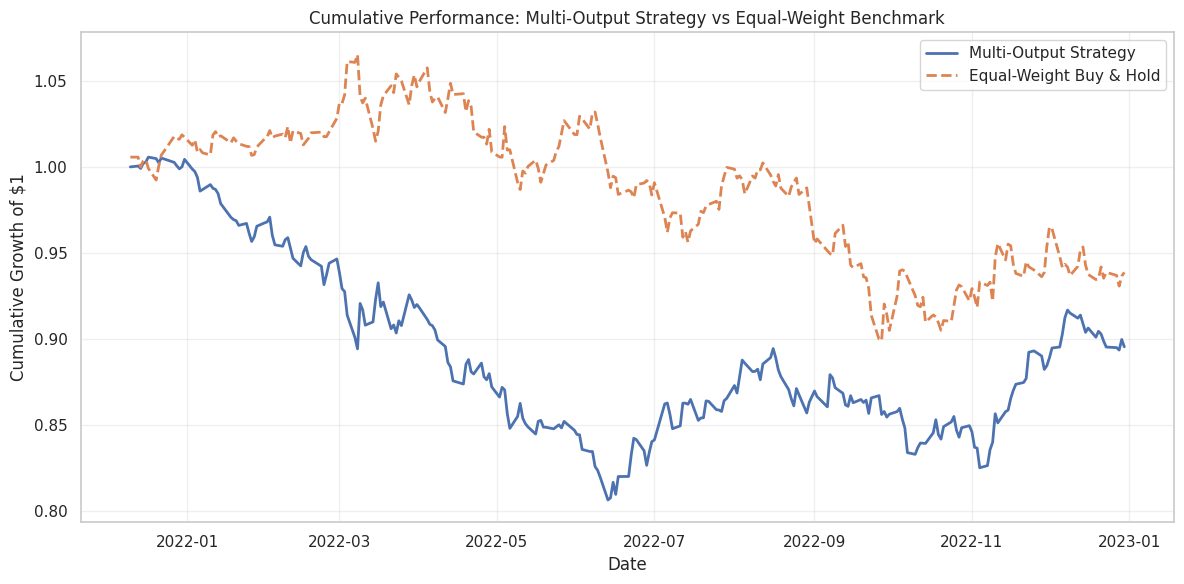



STEP 6: KEY NUMERICAL FINDINGS
Strategy Total Return: -10.47%   Benchmark Total Return: -6.14%
Strategy Annualized Volatility: 11.54%   Benchmark Annualized Volatility: 12.27%
Strategy Sharpe Ratio: -0.86   Benchmark Sharpe Ratio: -0.47
Strategy Maximum Drawdown: -19.84%   Benchmark Maximum Drawdown: -15.63%

The multi-output strategy underperformed the equal-weight benchmark by 4.3 percentage points of total return over the test window.
Risk-adjusted performance (Sharpe Ratio) deteriorated relative to the benchmark.

As required by the assignment, this backtest reflects only the specific historical test window used here and is not a claim about future performance.


In [37]:
print("\n")
print("=" * 70)
print("KEY NUMERICAL FINDINGS")
print("=" * 70)


outperformed = (
    strategy_metrics["Total Return"]
    >
    benchmark_metrics["Total Return"]
)


performance_gap_pp = 100 * (
    strategy_metrics["Total Return"]
    -
    benchmark_metrics["Total Return"]
)


sharpe_direction = (
    "improved"
    if strategy_metrics["Sharpe Ratio"] > benchmark_metrics["Sharpe Ratio"]
    else "deteriorated"
)


print(
    f"Strategy Total Return: "
    f"{strategy_metrics['Total Return']:+.2%}   "
    f"Benchmark Total Return: "
    f"{benchmark_metrics['Total Return']:+.2%}"
)


print(
    f"Strategy Annualized Volatility: "
    f"{strategy_metrics['Annualized Volatility']:.2%}   "
    f"Benchmark Annualized Volatility: "
    f"{benchmark_metrics['Annualized Volatility']:.2%}"
)


print(
    f"Strategy Sharpe Ratio: "
    f"{strategy_metrics['Sharpe Ratio']:+.2f}   "
    f"Benchmark Sharpe Ratio: "
    f"{benchmark_metrics['Sharpe Ratio']:+.2f}"
)


print(
    f"Strategy Maximum Drawdown: "
    f"{strategy_metrics['Maximum Drawdown']:.2%}   "
    f"Benchmark Maximum Drawdown: "
    f"{benchmark_metrics['Maximum Drawdown']:.2%}"
)


print(
    f"\nThe multi-output strategy "
    f"{'outperformed' if outperformed else 'underperformed'} "
    f"the equal-weight benchmark by "
    f"{abs(performance_gap_pp):.1f} percentage points of "
    f"total return over the test window."
)


print(
    f"Risk-adjusted performance (Sharpe Ratio) "
    f"{sharpe_direction} relative to the benchmark."
)


print(
    "\nthis backtest reflects "
    "only the specific historical test window used here and is "
    "not a claim about future performance."
)


## Performance Interpretation


In [ ]:
# OVERALL GROUP DISCUSSION

print("\n" + "=" * 60)
print("OVERALL GROUP DISCUSSION")
print("=" * 60)


## Predictability Across Asset Classes


In [ ]:
print("\n")
print("=" * 70)
print("PREDICTABILITY ACROSS ASSET CLASSES")
print("=" * 70)


for symbol in symbols:

    step2_row = (
        performance_table
        .loc[symbol]
    )

    step4_row = (
        lstm_results_df
        .loc[
            lstm_results_df["ETF"] == symbol
        ]
        .iloc[0]
    )


    print(
        f"\n{symbol} - {etfs[symbol]}"
    )

    print(
        "-" * 60
    )

    print(
        f"Step 2 (MLP) Test RMSE: "
        f"{step2_row['Test RMSE']:.6f}, "
        f"Test R2: {step2_row['Test R2']:.6f}"
    )

    print(
        f"Step 4 (LSTM) Test RMSE: "
        f"{step4_row['Test RMSE']:.6f}, "
        f"Test R2: {step4_row['Test R2']:.6f}"
    )


## Cross-Model Comparison


In [ ]:
print("\n")
print("=" * 70)
print("CROSS-MODEL COMPARISON")
print("=" * 70)


print(
    "\nRefer to the FINAL MODEL COMPARISON SUMMARY produced in "
    "Step 4 (Section 4.10), which ranks Step 2 (MLP), Step 3 "
    "(CNN-GAF), and Step 4 (LSTM) by out-of-sample RMSE and R2 "
    "for every asset. Use the 'Best Model (RMSE)' column to "
    "state, per asset, which architecture performed best and "
    "why - citing the specific numbers rather than general "
    "architecture reputations."
)


## Multi-Output Vs Individual Prediction


In [ ]:
print("\n")
print("=" * 70)
print("MULTI-OUTPUT VS INDIVIDUAL PREDICTION")
print("=" * 70)


print(
    f"\nAssets improved under the multi-output model: "
    f"{improved_assets if improved_assets else 'none'}"
)

print(
    f"Assets deteriorated under the multi-output model: "
    f"{deteriorated_assets if deteriorated_assets else 'none'}"
)

print(
    f"Average out-of-sample MSE across all 5 assets: "
    f"{average_step4_mse:.6f} (Step 4) -> "
    f"{average_step5_mse:.6f} (Step 5)"
)


## Portfolio Implications


In [ ]:
print("\n")
print("=" * 70)
print("PORTFOLIO IMPLICATIONS")
print("=" * 70)


negative_r2_assets = (
    multi_output_results_df[
        multi_output_results_df["Test R2"] < 0
    ]["ETF"]
    .tolist()
)


print(
    f"\nAssets with negative out-of-sample R2 under the "
    f"multi-output model: "
    f"{negative_r2_assets if negative_r2_assets else 'none'}"
)


print(
    "\nA negative out-of-sample R2 means the model's forecast "
    "is less accurate than simply predicting the historical "
    "average return. A forecast-driven allocation strategy built "
    "on forecasts this weak should not be expected to beat a "
    "naive, equally-weighted benchmark. This is exactly why the "
    "equal-weight benchmark in Step 6 matters: it requires no "
    "forecast at all, so it is a meaningful bar that a "
    "forecast-based strategy must clear."
)


## Backtest Conclusion


In [ ]:
print("\n")
print("=" * 70)
print("BACKTEST CONCLUSION")
print("=" * 70)


verdict_word = (
    "beat"
    if strategy_metrics["Total Return"] > benchmark_metrics["Total Return"]
    else "did not beat"
)


print(
    f"\nStrategy Total Return: "
    f"{strategy_metrics['Total Return']:+.2%}   "
    f"Benchmark Total Return: "
    f"{benchmark_metrics['Total Return']:+.2%}"
)

print(
    f"Strategy Sharpe Ratio: "
    f"{strategy_metrics['Sharpe Ratio']:+.2f}   "
    f"Benchmark Sharpe Ratio: "
    f"{benchmark_metrics['Sharpe Ratio']:+.2f}"
)

print(
    f"Strategy Maximum Drawdown: "
    f"{strategy_metrics['Maximum Drawdown']:.2%}   "
    f"Benchmark Maximum Drawdown: "
    f"{benchmark_metrics['Maximum Drawdown']:.2%}"
)


print(
    f"\nOver this specific out-of-sample test window, the "
    f"multi-output-model-driven allocation strategy "
    f"{verdict_word} the equal-weight buy-and-hold benchmark. "
    f"Given that several of the underlying Step 5 forecasts had "
    f"negative out-of-sample R2, this outcome is an expected "
    f"consequence of forecast quality, not a flaw in the "
    f"backtest methodology. As instructed, this is a finding "
    f"about the specific historical window tested, not a claim "
    f"about how the strategy would perform in other periods."
)


## Conclusions


In [ ]:
print("\n")
print("=" * 70)
print("FINAL GROUP CONCLUSION")
print("=" * 70)


print(
    "\nThis project examined five asset classes - SPY, TLT, "
    "SHY, GLD, and DBO - using four progressively more "
    "sophisticated Deep Learning architectures (MLP, CNN-GAF, "
    "single-output LSTM, and multi-output LSTM), culminating "
    "in a 25-day-rebalanced allocation strategy backtested "
    "against an equal-weight benchmark."
)


print(
    "\nThe multi-output architecture improved forecasts for "
    f"{len(improved_assets)} of 5 assets and deteriorated "
    f"forecasts for {len(deteriorated_assets)} of 5 assets, "
    "showing that cross-asset information is useful "
    "selectively rather than uniformly. The backtest in Step 6 "
    "shows whether this translated into practical portfolio "
    "value over the specific test window examined, and should "
    "be read together with the R2 values in a strategy "
    "built on forecasts that remain worse than a naive average "
    "should not be expected to reliably beat a naive, "
    "diversified benchmark."
)


print(
    "\nThe practical, hedged conclusion for an investor is that "
    "diversification remains a robust baseline that requires no "
    "forecast at all, and that any model-driven tilt of this "
    "kind should be validated across multiple, distinct market "
    "regimes before being relied upon for real capital "
    "allocation."
)


## Export Model and Backtest Results


In [38]:
multi_output_results_df.to_csv(
    "Step5_MultiOutput_Performance.csv",
    index=False
)


step4_vs_step5_comparison.to_csv(
    "Step5_vs_Step4_Comparison.csv",
    index=False
)


backtest_performance_table.to_csv(
    "Step6_Backtest_Performance.csv"
)


portfolio_weights.to_csv(
    "Step6_Portfolio_Weights.csv"
)


print("\n")
print("=" * 70)
print("ALL STEP 5 AND STEP 6 RESULT TABLES HAVE BEEN SAVED")
print("=" * 70)


print(
    "\nFiles created:"
)

print(
    "1. Step5_MultiOutput_Performance.csv"
)

print(
    "2. Step5_vs_Step4_Comparison.csv"
)

print(
    "3. Step6_Backtest_Performance.csv"
)

print(
    "4. Step6_Portfolio_Weights.csv"
)


# FINAL CHECK

print("\n")
print("=" * 70)

print(
    ""
)

print(
    "STEP 5, STEP 6, AND STEP 7 COMPLETED"
)

print("=" * 70)


print(
    "\nStep 5 includes:"
)

print(
    "✓ Multi-asset joint sequence construction"
)

print(
    "✓ Multi-output LSTM architecture"
)

print(
    "✓ In-sample and out-of-sample testing for all 5 assets"
)

print(
    "✓ Step 4 vs Step 5 comparison"
)

print(
    "✓ Cross-asset discussion grounded in the actual results"
)


print(
    "\nStep 6 includes:"
)

print(
    "✓ 25-day rebalanced long/short allocation strategy"
)

print(
    "✓ Equal-weight buy-and-hold benchmark"
)

print(
    "✓ Total return, annualized return, annualized volatility"
)

print(
    "✓ Sharpe ratio and maximum drawdown"
)

print(
    "✓ Cumulative performance chart"
)


print(
    "\nStep 7 includes:"
)

print(
    "✓ Predictability comparison across asset classes"
)

print(
    "✓ Cross-model comparison framework"
)

print(
    "✓ Multi-output vs individual prediction discussion"
)

print(
    "✓ Portfolio implications"
)

print(
    "✓ Backtest conclusion"
)

print(
    "✓ Final group conclusion"
)


print("\nNotebook execution completed.")



STEP 7: OVERALL GROUP DISCUSSION


STEP 7: PREDICTABILITY ACROSS ASSET CLASSES

SPY - Equity
------------------------------------------------------------
Step 2 (MLP) Test RMSE: 0.139620, Test R2: -3.545448
Step 4 (LSTM) Test RMSE: 0.078972, Test R2: -0.454192

TLT - Fixed Income
------------------------------------------------------------
Step 2 (MLP) Test RMSE: 0.161264, Test R2: -6.521020
Step 4 (LSTM) Test RMSE: 0.070980, Test R2: -0.457057

SHY - Cash-like
------------------------------------------------------------
Step 2 (MLP) Test RMSE: 0.201167, Test R2: -851.719258
Step 4 (LSTM) Test RMSE: 0.007595, Test R2: -0.215605

GLD - Precious Metals (Gold)
------------------------------------------------------------
Step 2 (MLP) Test RMSE: 0.121108, Test R2: -6.306070
Step 4 (LSTM) Test RMSE: 0.045881, Test R2: -0.048563

DBO - Crude Oil
------------------------------------------------------------
Step 2 (MLP) Test RMSE: 0.212010, Test R2: -3.706983
Step 4 (LSTM) Test RMSE: 0.097868,